In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Psiquiatría.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 7 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=138.0, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 364
Page 1, Q1, A: Yellow percentage: 0.0%


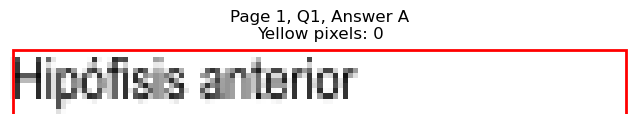

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=133.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 116
Page 1, Q1, B: Total non-white pixels: 445
Page 1, Q1, B: Yellow percentage: 26.1%


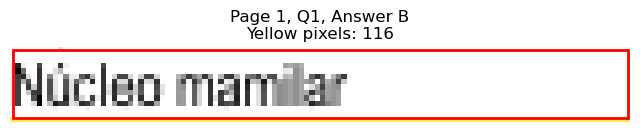

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=142.9, y1=139.9
Page 1, Q1, C: Yellow pixels: 1320
Page 1, Q1, C: Total non-white pixels: 1625
Page 1, Q1, C: Yellow percentage: 81.2%


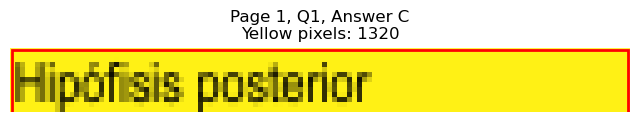

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=377.2, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 239
Page 1, Q1, D: Yellow percentage: 0.0%


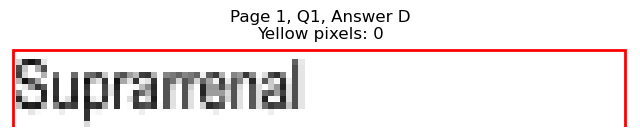

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=365.7, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 194
Page 1, Q1, E: Yellow percentage: 0.0%


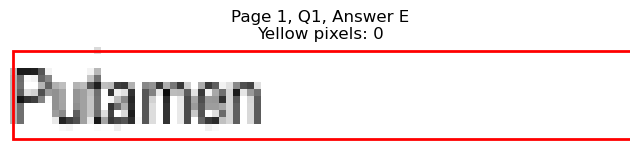


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=170.5, y1=190.4
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 521
Page 1, Q2, A: Yellow percentage: 0.0%


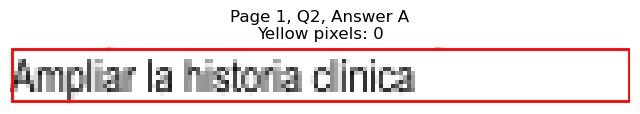

Page 1, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=180.6, y1=203.0
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 545
Page 1, Q2, B: Yellow percentage: 0.0%


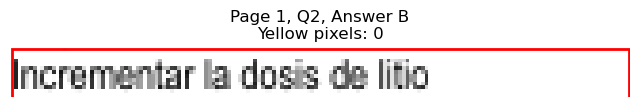

Page 1, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=210.8, y1=215.6
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 706
Page 1, Q2, C: Yellow percentage: 0.0%


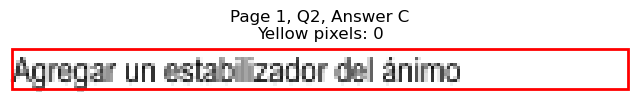

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=437.8, y1=190.4
Page 1, Q2, D: Yellow pixels: 161
Page 1, Q2, D: Total non-white pixels: 719
Page 1, Q2, D: Yellow percentage: 22.4%


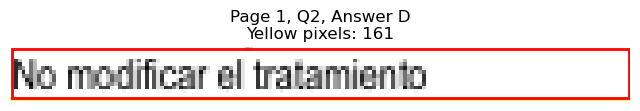

Page 1, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=470.0, y1=203.0
Page 1, Q2, E: Yellow pixels: 1964
Page 1, Q2, E: Total non-white pixels: 2522
Page 1, Q2, E: Yellow percentage: 77.9%


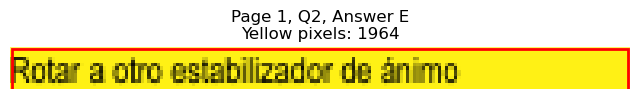


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=190.2, y1=291.5
Page 1, Q3, A: Yellow pixels: 173
Page 1, Q3, A: Total non-white pixels: 715
Page 1, Q3, A: Yellow percentage: 24.2%


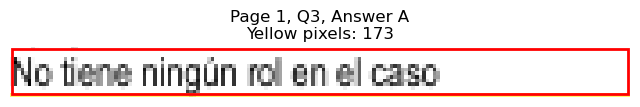

Page 1, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=195.3, y1=304.1
Page 1, Q3, B: Yellow pixels: 1849
Page 1, Q3, B: Total non-white pixels: 2492
Page 1, Q3, B: Yellow percentage: 74.2%


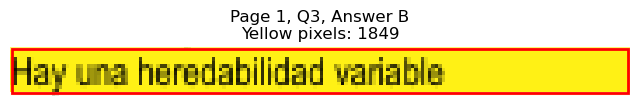

Page 1, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=181.1, y1=316.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 720
Page 1, Q3, C: Yellow percentage: 0.0%


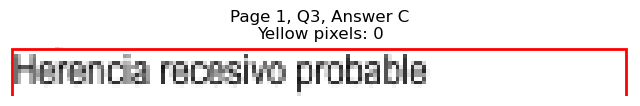

Page 1, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=448.4, y1=291.5
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 634
Page 1, Q3, D: Yellow percentage: 0.0%


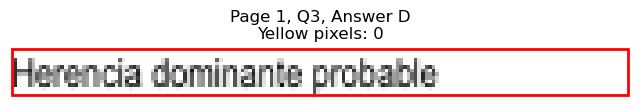

Page 1, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=447.9, y1=304.1
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 611
Page 1, Q3, E: Yellow percentage: 0.0%


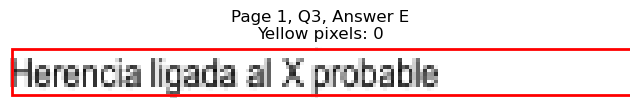


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=96.0, y1=354.6
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 294
Page 1, Q4, A: Yellow percentage: 0.0%


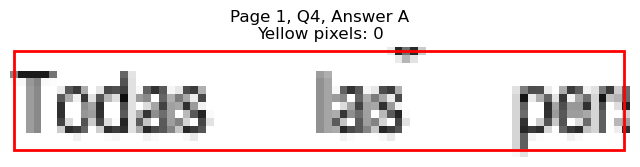

Page 1, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=246.9, y1=379.8
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 843
Page 1, Q4, B: Yellow percentage: 0.0%


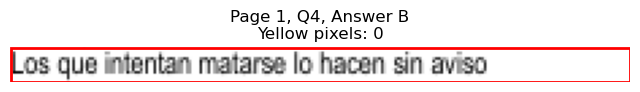

Page 1, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=236.2, y1=392.4
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 862
Page 1, Q4, C: Yellow percentage: 0.0%


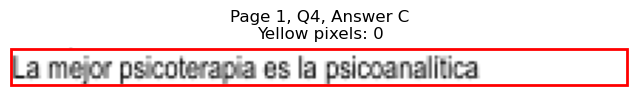

Page 1, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=493.1, y1=354.6
Page 1, Q4, D: Yellow pixels: 213
Page 1, Q4, D: Total non-white pixels: 1073
Page 1, Q4, D: Yellow percentage: 19.9%


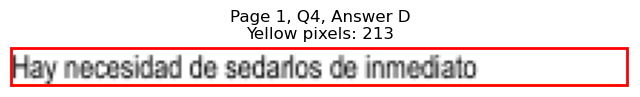

Page 1, Q4 - E: Detected box: x0=392.6, y0=354.5, x1=435.2, y1=367.2
Page 1, Q4, E: Yellow pixels: 1002
Page 1, Q4, E: Total non-white pixels: 1316
Page 1, Q4, E: Yellow percentage: 76.1%


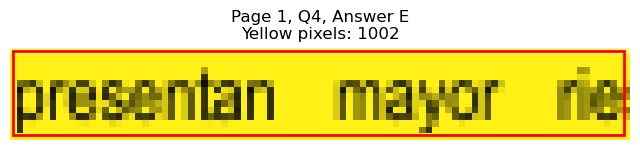


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=118.9, y1=430.3
Page 1, Q5, A: Yellow pixels: 1035
Page 1, Q5, A: Total non-white pixels: 1414
Page 1, Q5, A: Yellow percentage: 73.2%


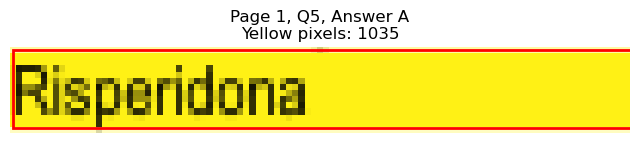

Page 1, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=110.9, y1=442.9
Page 1, Q5, B: Yellow pixels: 0
Page 1, Q5, B: Total non-white pixels: 288
Page 1, Q5, B: Yellow percentage: 0.0%


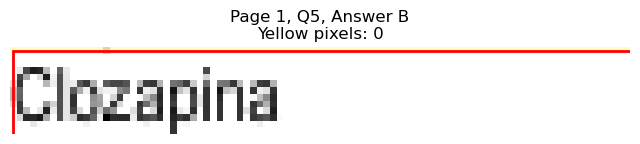

Page 1, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=115.0, y1=455.5
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 226
Page 1, Q5, C: Yellow percentage: 0.0%


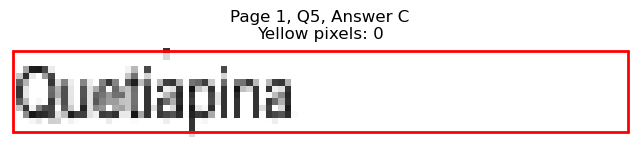

Page 1, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=377.2, y1=430.3
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 269
Page 1, Q5, D: Yellow percentage: 0.0%


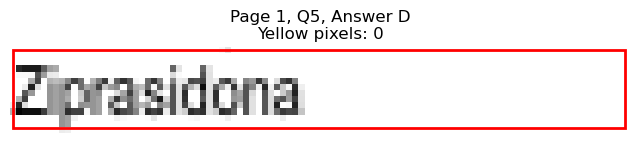

Page 1, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=388.3, y1=442.9
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 297
Page 1, Q5, E: Yellow percentage: 0.0%


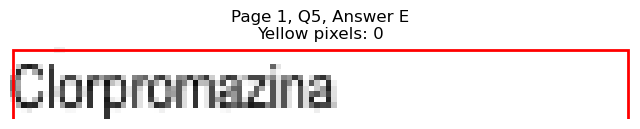


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=151.1, y1=543.8
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 439
Page 1, Q6, A: Yellow percentage: 0.0%


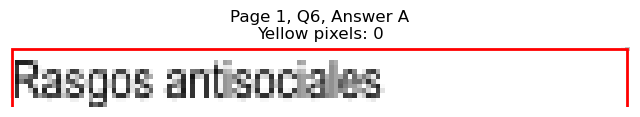

Page 1, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=145.1, y1=556.4
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 401
Page 1, Q6, B: Yellow percentage: 0.0%


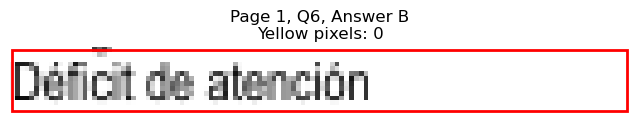

Page 1, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=169.6, y1=569.2
Page 1, Q6, C: Yellow pixels: 1559
Page 1, Q6, C: Total non-white pixels: 2128
Page 1, Q6, C: Yellow percentage: 73.3%


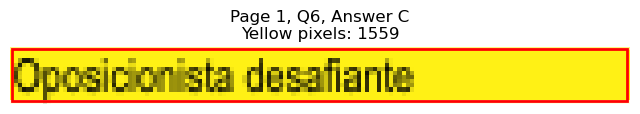

Page 1, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=402.8, y1=543.8
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 410
Page 1, Q6, D: Yellow percentage: 0.0%


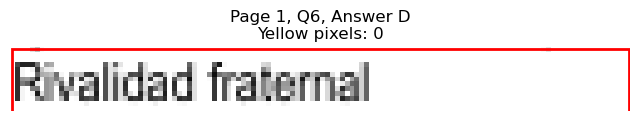

Page 1, Q6 - E: Detected box: x0=327.0, y0=543.8, x1=405.3, y1=556.4
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 435
Page 1, Q6, E: Yellow percentage: 0.0%


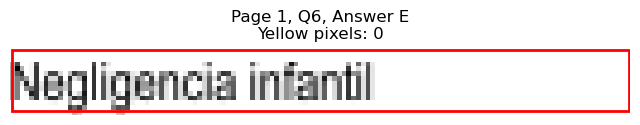


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=632.2, x1=174.6, y1=644.9
Page 1, Q7, A: Yellow pixels: 1601
Page 1, Q7, A: Total non-white pixels: 2041
Page 1, Q7, A: Yellow percentage: 78.4%


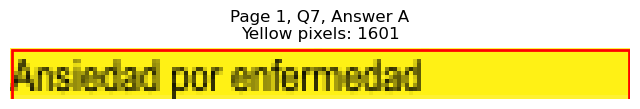

Page 1, Q7 - B: Detected box: x0=68.3, y0=644.9, x1=150.6, y1=657.5
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 426
Page 1, Q7, B: Yellow percentage: 0.0%


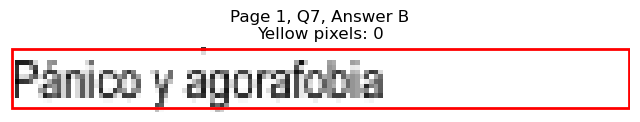

Page 1, Q7 - C: Detected box: x0=68.8, y0=657.5, x1=195.3, y1=670.1
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 620
Page 1, Q7, C: Yellow percentage: 0.0%


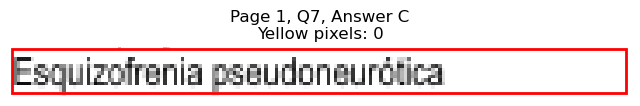

Page 1, Q7 - D: Detected box: x0=327.5, y0=632.2, x1=440.9, y1=644.9
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 586
Page 1, Q7, D: Yellow percentage: 0.0%


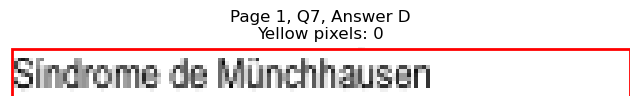

Page 1, Q7 - E: Detected box: x0=327.0, y0=644.9, x1=417.3, y1=657.5
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 453
Page 1, Q7, E: Yellow percentage: 0.0%


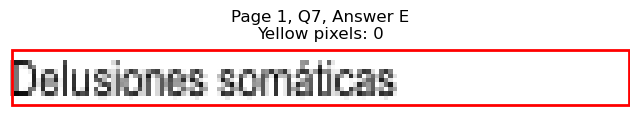


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=139.9, x1=110.4, y1=152.6
Page 2, Q1, A: Yellow pixels: 1039
Page 2, Q1, A: Total non-white pixels: 1302
Page 2, Q1, A: Yellow percentage: 79.8%


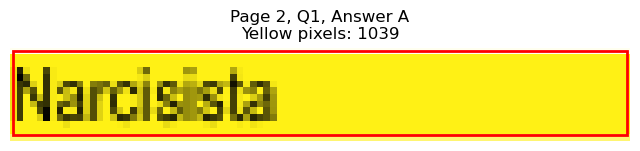

Page 2, Q1 - B: Detected box: x0=68.3, y0=152.5, x1=124.5, y1=165.2
Page 2, Q1, B: Yellow pixels: 107
Page 2, Q1, B: Total non-white pixels: 411
Page 2, Q1, B: Yellow percentage: 26.0%


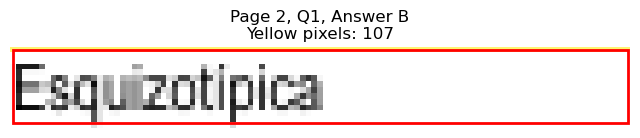

Page 2, Q1 - C: Detected box: x0=68.8, y0=165.1, x1=113.4, y1=177.8
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 230
Page 2, Q1, C: Yellow percentage: 0.0%


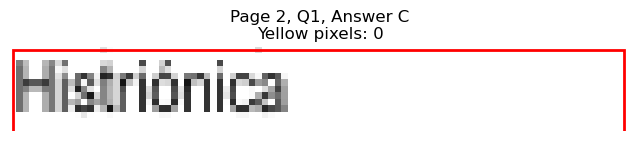

Page 2, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=367.6, y1=152.6
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 201
Page 2, Q1, D: Yellow percentage: 0.0%


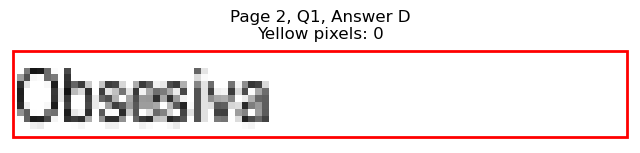

Page 2, Q1 - E: Detected box: x0=327.0, y0=152.5, x1=368.2, y1=165.2
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 213
Page 2, Q1, E: Yellow percentage: 0.0%


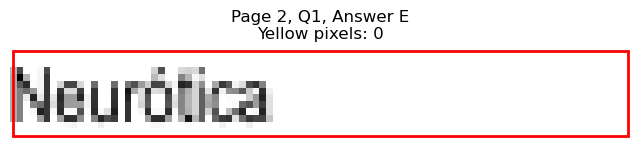


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=107.9, y1=215.6
Page 2, Q2, A: Yellow pixels: 1029
Page 2, Q2, A: Total non-white pixels: 1260
Page 2, Q2, A: Yellow percentage: 81.7%


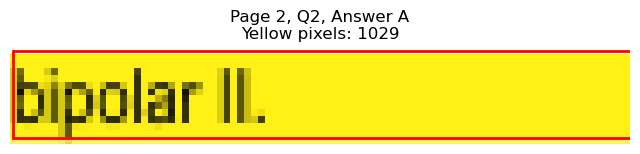

Page 2, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=103.9, y1=228.3
Page 2, Q2, B: Yellow pixels: 86
Page 2, Q2, B: Total non-white pixels: 270
Page 2, Q2, B: Yellow percentage: 31.9%


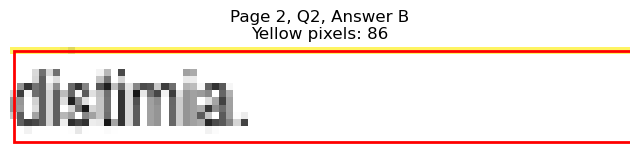

Page 2, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=105.9, y1=240.9
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 180
Page 2, Q2, C: Yellow percentage: 0.0%


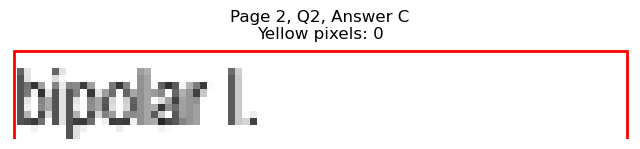

Page 2, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=394.7, y1=215.6
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 354
Page 2, Q2, D: Yellow percentage: 0.0%


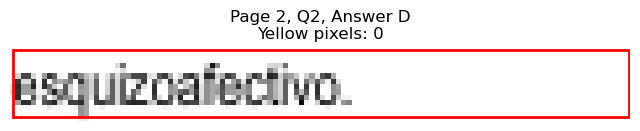

Page 2, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=371.7, y1=228.3
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 236
Page 2, Q2, E: Yellow percentage: 0.0%


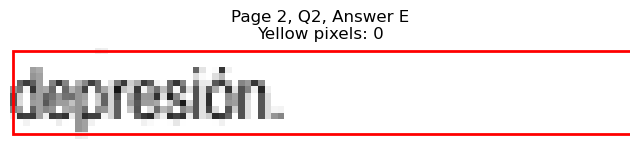


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=109.5, y1=291.5
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 220
Page 2, Q3, A: Yellow percentage: 0.0%


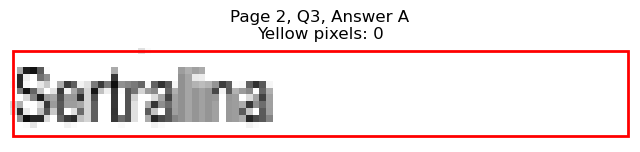

Page 2, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=113.4, y1=304.1
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 243
Page 2, Q3, B: Yellow percentage: 0.0%


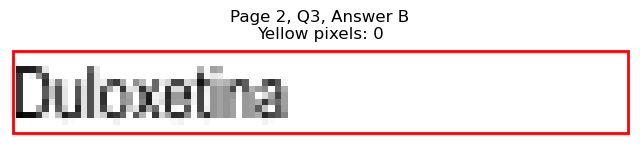

Page 2, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=112.9, y1=316.7
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 210
Page 2, Q3, C: Yellow percentage: 0.0%


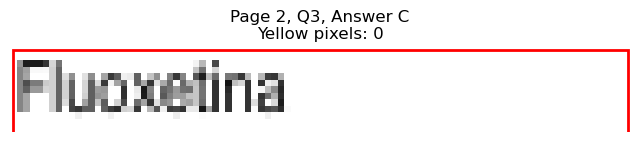

Page 2, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=376.7, y1=291.5
Page 2, Q3, D: Yellow pixels: 1086
Page 2, Q3, D: Total non-white pixels: 1400
Page 2, Q3, D: Yellow percentage: 77.6%


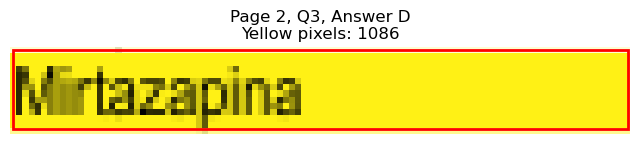

Page 2, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=376.7, y1=304.1
Page 2, Q3, E: Yellow pixels: 100
Page 2, Q3, E: Total non-white pixels: 353
Page 2, Q3, E: Yellow percentage: 28.3%


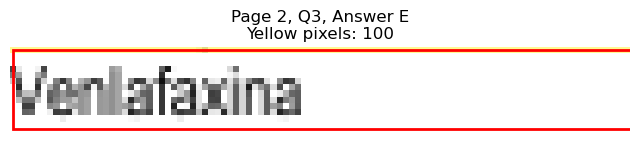


Page 2, Q3 - Selected Answer: D (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=146.5, y1=379.8
Page 2, Q4, A: Yellow pixels: 1387
Page 2, Q4, A: Total non-white pixels: 1677
Page 2, Q4, A: Yellow percentage: 82.7%


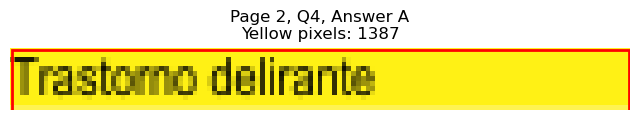

Page 2, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=185.2, y1=392.4
Page 2, Q4, B: Yellow pixels: 168
Page 2, Q4, B: Total non-white pixels: 771
Page 2, Q4, B: Yellow percentage: 21.8%


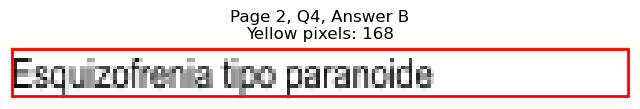

Page 2, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=210.8, y1=405.0
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 727
Page 2, Q4, C: Yellow percentage: 0.0%


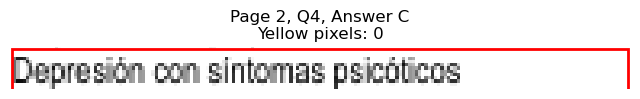

Page 2, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=429.9, y1=379.8
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 534
Page 2, Q4, D: Yellow percentage: 0.0%


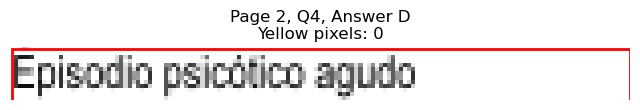

Page 2, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=432.9, y1=392.4
Page 2, Q4, E: Yellow pixels: 0
Page 2, Q4, E: Total non-white pixels: 529
Page 2, Q4, E: Yellow percentage: 0.0%


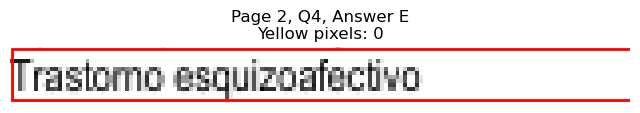


Page 2, Q4 - Selected Answer: A (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=113.4, y1=455.5
Page 2, Q5, A: Yellow pixels: 1069
Page 2, Q5, A: Total non-white pixels: 1344
Page 2, Q5, A: Yellow percentage: 79.5%


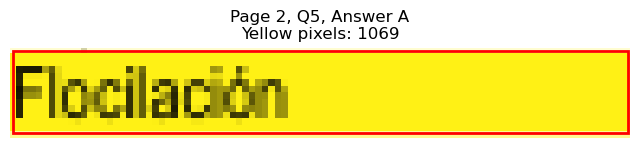

Page 2, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=110.9, y1=468.1
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 214
Page 2, Q5, B: Yellow percentage: 0.0%


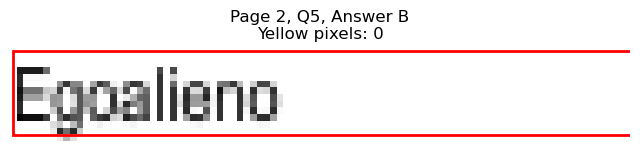

Page 2, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=118.9, y1=480.7
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 248
Page 2, Q5, C: Yellow percentage: 0.0%


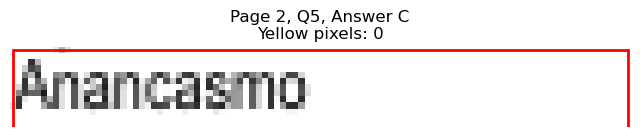

Page 2, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=367.1, y1=455.5
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 200
Page 2, Q5, D: Yellow percentage: 0.0%


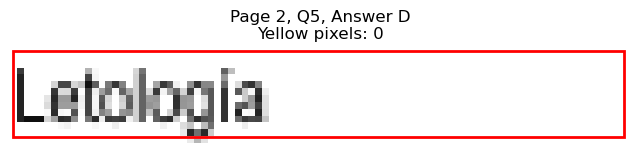

Page 2, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=371.2, y1=468.1
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 252
Page 2, Q5, E: Yellow percentage: 0.0%


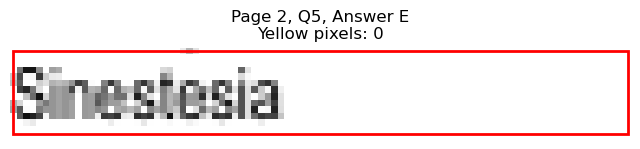


Page 2, Q5 - Selected Answer: A (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=118.5, y1=531.2
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 275
Page 2, Q6, A: Yellow percentage: 0.0%


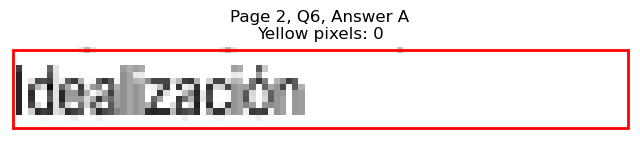

Page 2, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=98.4, y1=543.8
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 157
Page 2, Q6, B: Yellow percentage: 0.0%


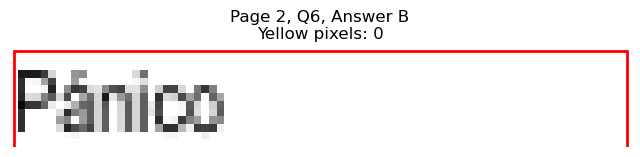

Page 2, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=113.4, y1=556.4
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 226
Page 2, Q6, C: Yellow percentage: 0.0%


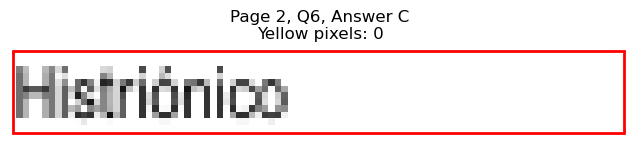

Page 2, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=375.7, y1=531.2
Page 2, Q6, D: Yellow pixels: 1098
Page 2, Q6, D: Total non-white pixels: 1386
Page 2, Q6, D: Yellow percentage: 79.2%


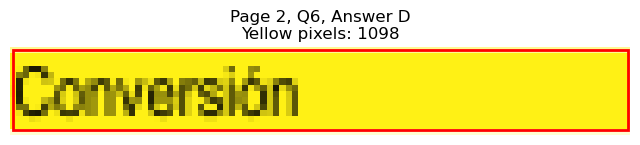

Page 2, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=363.7, y1=543.8
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 267
Page 2, Q6, E: Yellow percentage: 0.0%


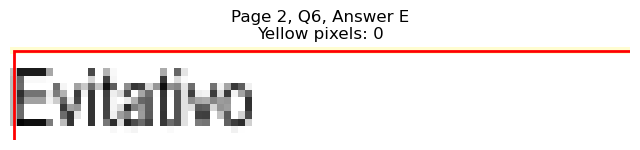


Page 2, Q6 - Selected Answer: D (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=135.5, y1=594.4
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 349
Page 2, Q7, A: Yellow percentage: 0.0%


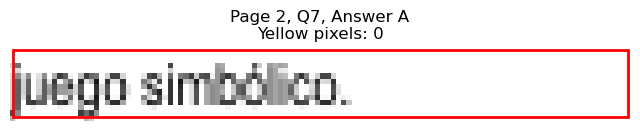

Page 2, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=170.1, y1=607.0
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 519
Page 2, Q7, B: Yellow percentage: 0.0%


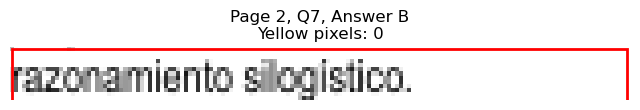

Page 2, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=174.6, y1=619.6
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 501
Page 2, Q7, C: Yellow percentage: 0.0%


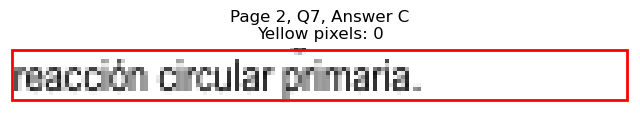

Page 2, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=444.9, y1=594.4
Page 2, Q7, D: Yellow pixels: 168
Page 2, Q7, D: Total non-white pixels: 756
Page 2, Q7, D: Yellow percentage: 22.2%


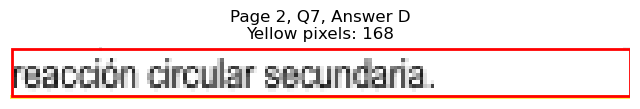

Page 2, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=466.0, y1=607.0
Page 2, Q7, E: Yellow pixels: 1929
Page 2, Q7, E: Total non-white pixels: 2470
Page 2, Q7, E: Yellow percentage: 78.1%


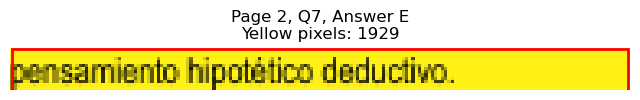


Page 2, Q7 - Selected Answer: E (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=118.0, y1=670.1
Page 2, Q8, A: Yellow pixels: 100
Page 2, Q8, A: Total non-white pixels: 328
Page 2, Q8, A: Yellow percentage: 30.5%


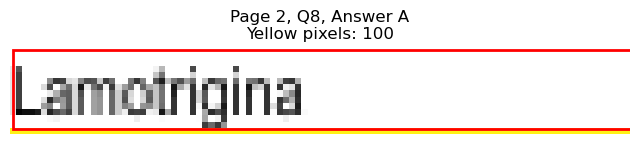

Page 2, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=131.5, y1=682.7
Page 2, Q8, B: Yellow pixels: 1220
Page 2, Q8, B: Total non-white pixels: 1482
Page 2, Q8, B: Yellow percentage: 82.3%


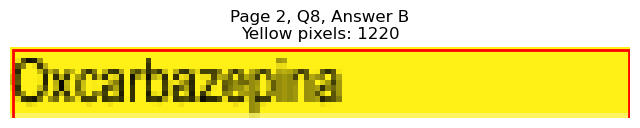

Page 2, Q8 - C: Detected box: x0=68.8, y0=682.7, x1=115.0, y1=695.3
Page 2, Q8, C: Yellow pixels: 97
Page 2, Q8, C: Total non-white pixels: 321
Page 2, Q8, C: Yellow percentage: 30.2%


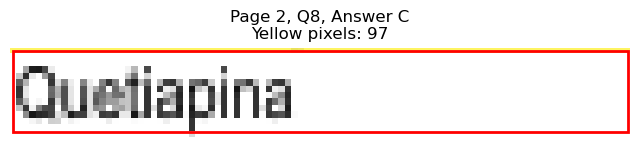

Page 2, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=378.2, y1=670.1
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 271
Page 2, Q8, D: Yellow percentage: 0.0%


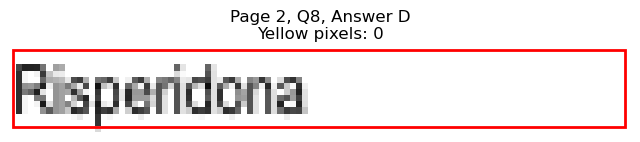

Page 2, Q8 - E: Detected box: x0=327.0, y0=670.1, x1=371.2, y1=682.7
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 233
Page 2, Q8, E: Yellow percentage: 0.0%


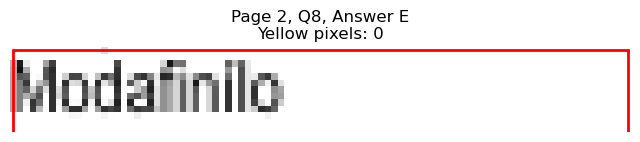


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=733.2, x1=101.4, y1=745.8
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 182
Page 2, Q9, A: Yellow percentage: 0.0%


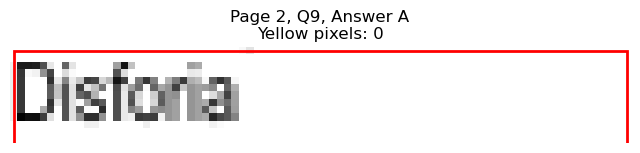

Page 2, Q9 - B: Detected box: x0=68.3, y0=745.8, x1=123.5, y1=758.4
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 249
Page 2, Q9, B: Yellow percentage: 0.0%


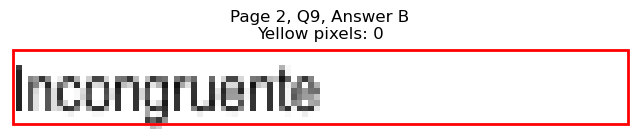

Page 2, Q9 - C: Detected box: x0=68.8, y0=758.5, x1=121.0, y1=771.2
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 278
Page 2, Q9, C: Yellow percentage: 0.0%


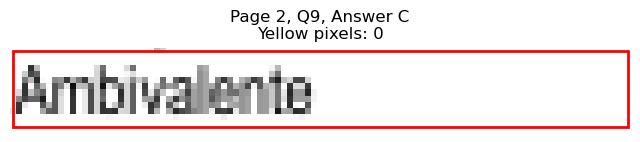

Page 2, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=388.3, y1=745.8
Page 2, Q9, D: Yellow pixels: 1216
Page 2, Q9, D: Total non-white pixels: 1456
Page 2, Q9, D: Yellow percentage: 83.5%


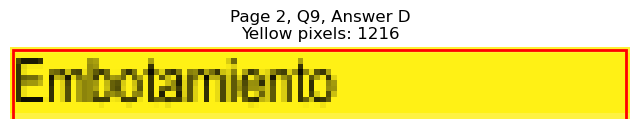

Page 2, Q9 - E: Detected box: x0=327.0, y0=745.8, x1=362.2, y1=758.4
Page 2, Q9, E: Yellow pixels: 86
Page 2, Q9, E: Total non-white pixels: 276
Page 2, Q9, E: Yellow percentage: 31.2%


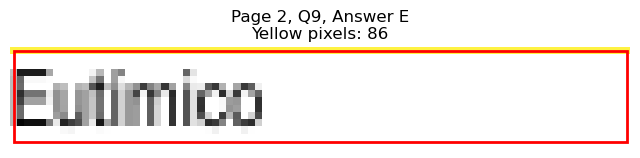


Page 2, Q9 - Selected Answer: D (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=109.5, y1=114.7
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 311
Page 3, Q1, A: Yellow percentage: 0.0%


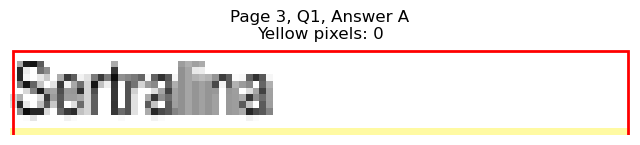

Page 3, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=113.4, y1=127.3
Page 3, Q1, B: Yellow pixels: 977
Page 3, Q1, B: Total non-white pixels: 1344
Page 3, Q1, B: Yellow percentage: 72.7%


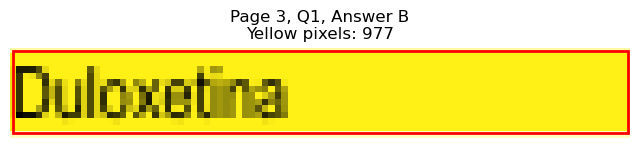

Page 3, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=114.4, y1=139.9
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 334
Page 3, Q1, C: Yellow percentage: 0.0%


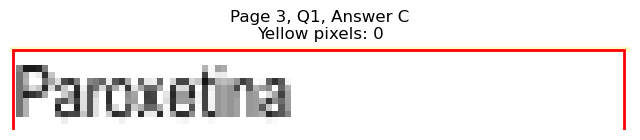

Page 3, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=376.6, y1=114.7
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 280
Page 3, Q1, D: Yellow percentage: 0.0%


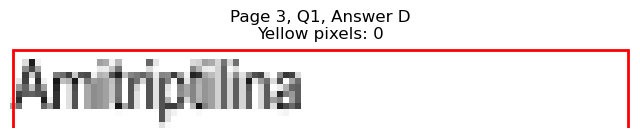

Page 3, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=370.7, y1=127.3
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 240
Page 3, Q1, E: Yellow percentage: 0.0%


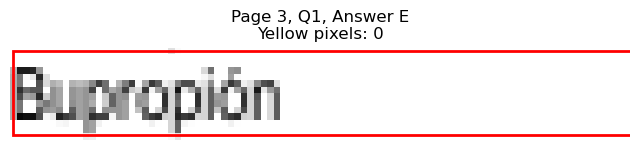


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=163.6, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 627
Page 3, Q2, A: Yellow percentage: 0.0%


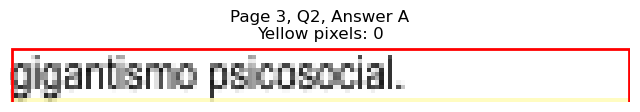

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=162.6, y1=190.4
Page 3, Q2, B: Yellow pixels: 1390
Page 3, Q2, B: Total non-white pixels: 2030
Page 3, Q2, B: Yellow percentage: 68.5%


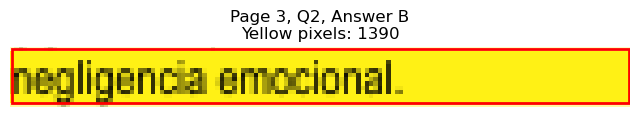

Page 3, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=138.0, y1=203.0
Page 3, Q2, C: Yellow pixels: 3
Page 3, Q2, C: Total non-white pixels: 466
Page 3, Q2, C: Yellow percentage: 0.6%


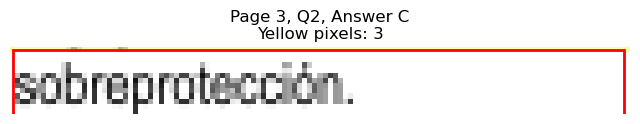

Page 3, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=397.7, y1=177.8
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 356
Page 3, Q2, D: Yellow percentage: 0.0%


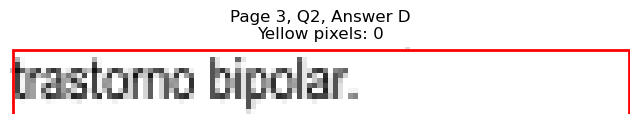

Page 3, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=412.9, y1=190.4
Page 3, Q2, E: Yellow pixels: 0
Page 3, Q2, E: Total non-white pixels: 419
Page 3, Q2, E: Yellow percentage: 0.0%


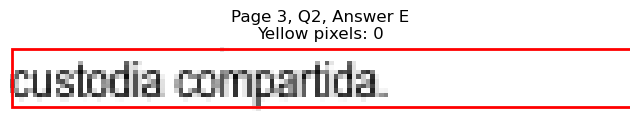


Page 3, Q2 - Selected Answer: B (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=104.9, y1=266.1
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 198
Page 3, Q3, A: Yellow percentage: 0.0%


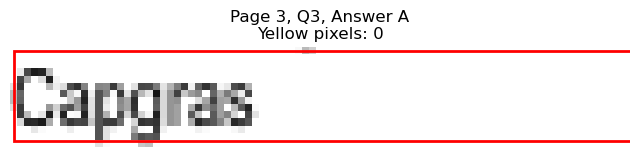

Page 3, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=98.4, y1=278.7
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 163
Page 3, Q3, B: Yellow percentage: 0.0%


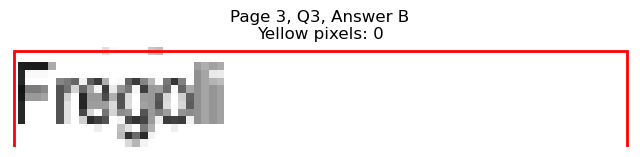

Page 3, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=107.9, y1=291.5
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 202
Page 3, Q3, C: Yellow percentage: 0.0%


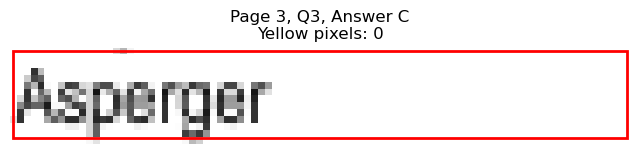

Page 3, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=368.2, y1=266.1
Page 3, Q3, D: Yellow pixels: 92
Page 3, Q3, D: Total non-white pixels: 304
Page 3, Q3, D: Yellow percentage: 30.3%


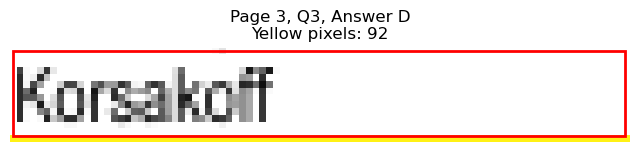

Page 3, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=391.7, y1=278.7
Page 3, Q3, E: Yellow pixels: 1258
Page 3, Q3, E: Total non-white pixels: 1495
Page 3, Q3, E: Yellow percentage: 84.1%


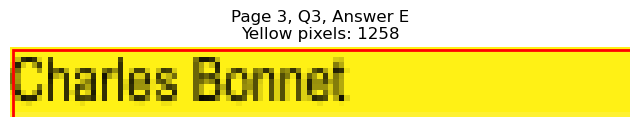


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=140.5, y1=354.6
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 365
Page 3, Q4, A: Yellow percentage: 0.0%


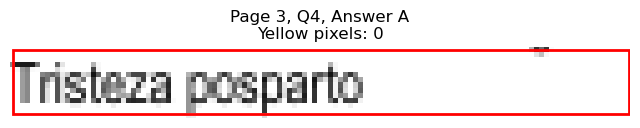

Page 3, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=141.5, y1=367.2
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 383
Page 3, Q4, B: Yellow percentage: 0.0%


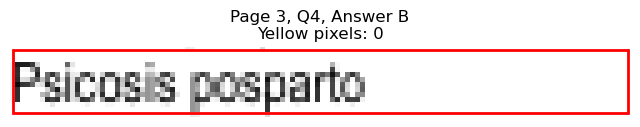

Page 3, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=160.1, y1=379.8
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 472
Page 3, Q4, C: Yellow percentage: 0.0%


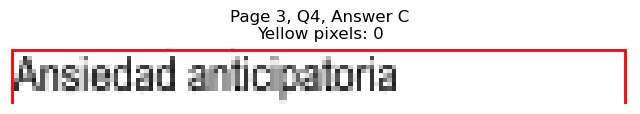

Page 3, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=412.9, y1=354.6
Page 3, Q4, D: Yellow pixels: 136
Page 3, Q4, D: Total non-white pixels: 573
Page 3, Q4, D: Yellow percentage: 23.7%


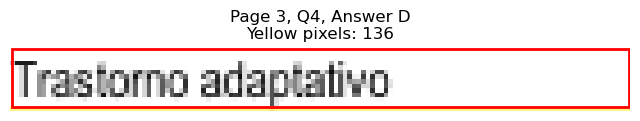

Page 3, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=408.3, y1=367.2
Page 3, Q4, E: Yellow pixels: 1399
Page 3, Q4, E: Total non-white pixels: 1848
Page 3, Q4, E: Yellow percentage: 75.7%


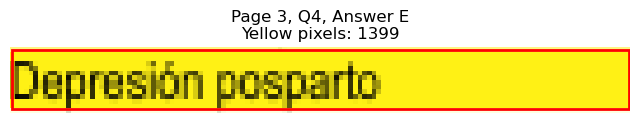


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=165.1, y1=430.3
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 492
Page 3, Q5, A: Yellow percentage: 0.0%


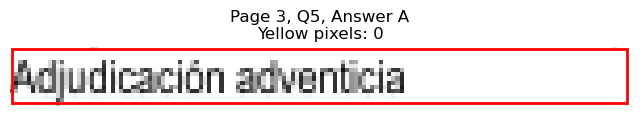

Page 3, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=173.1, y1=442.9
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 496
Page 3, Q5, B: Yellow percentage: 0.0%


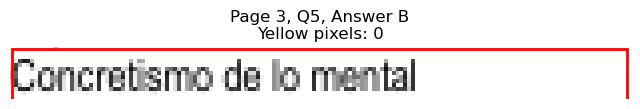

Page 3, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=168.6, y1=455.5
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 524
Page 3, Q5, C: Yellow percentage: 0.0%


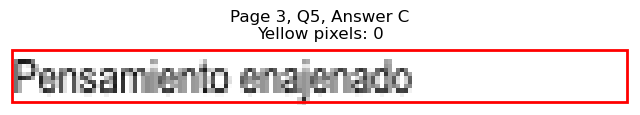

Page 3, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=443.9, y1=430.3
Page 3, Q5, D: Yellow pixels: 167
Page 3, Q5, D: Total non-white pixels: 749
Page 3, Q5, D: Yellow percentage: 22.3%


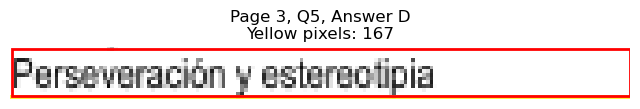

Page 3, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=412.3, y1=442.9
Page 3, Q5, E: Yellow pixels: 1418
Page 3, Q5, E: Total non-white pixels: 1768
Page 3, Q5, E: Yellow percentage: 80.2%


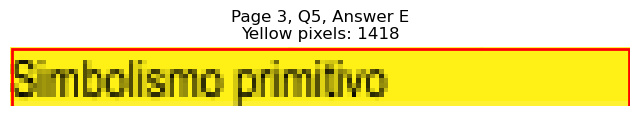


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=136.0, y1=493.4
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 368
Page 3, Q6, A: Yellow percentage: 0.0%


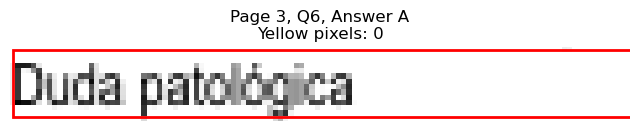

Page 3, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=115.9, y1=506.0
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 263
Page 3, Q6, B: Yellow percentage: 0.0%


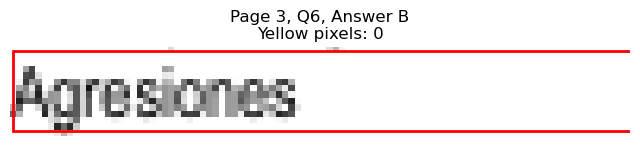

Page 3, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=104.9, y1=518.6
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 198
Page 3, Q6, C: Yellow percentage: 0.0%


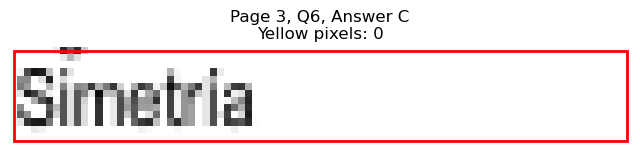

Page 3, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=368.7, y1=493.4
Page 3, Q6, D: Yellow pixels: 92
Page 3, Q6, D: Total non-white pixels: 293
Page 3, Q6, D: Yellow percentage: 31.4%


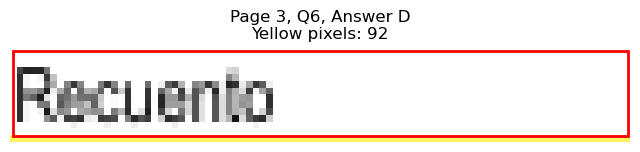

Page 3, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=389.7, y1=506.0
Page 3, Q6, E: Yellow pixels: 1235
Page 3, Q6, E: Total non-white pixels: 1469
Page 3, Q6, E: Yellow percentage: 84.1%


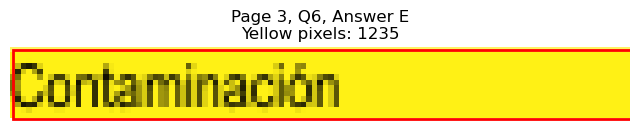


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=110.4, y1=556.4
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 230
Page 3, Q7, A: Yellow percentage: 0.0%


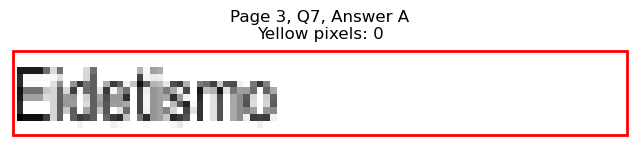

Page 3, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=99.9, y1=569.2
Page 3, Q7, B: Yellow pixels: 82
Page 3, Q7, B: Total non-white pixels: 253
Page 3, Q7, B: Yellow percentage: 32.4%


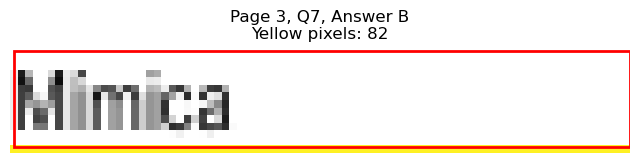

Page 3, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=118.9, y1=581.8
Page 3, Q7, C: Yellow pixels: 1105
Page 3, Q7, C: Total non-white pixels: 1313
Page 3, Q7, C: Yellow percentage: 84.2%


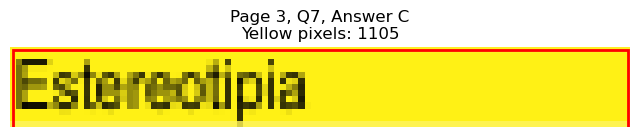

Page 3, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=371.7, y1=556.4
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 223
Page 3, Q7, D: Yellow percentage: 0.0%


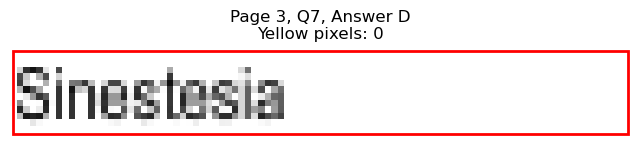

Page 3, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=361.1, y1=569.2
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 176
Page 3, Q7, E: Yellow percentage: 0.0%


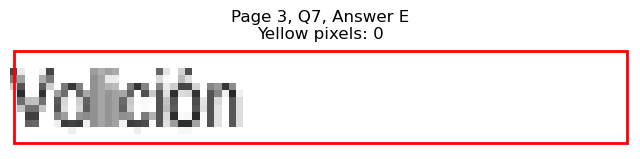


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=112.0, y1=657.5
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 216
Page 3, Q8, A: Yellow percentage: 0.0%


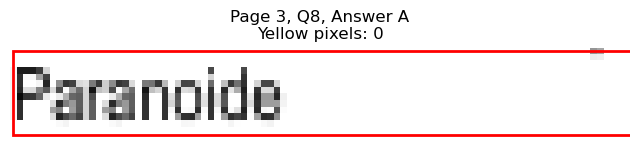

Page 3, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=110.4, y1=670.1
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 236
Page 3, Q8, B: Yellow percentage: 0.0%


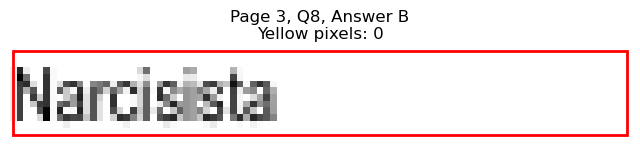

Page 3, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=105.4, y1=682.7
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 182
Page 3, Q8, C: Yellow percentage: 0.0%


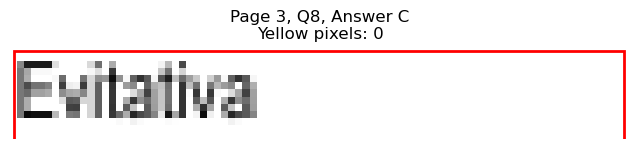

Page 3, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=362.1, y1=657.5
Page 3, Q8, D: Yellow pixels: 86
Page 3, Q8, D: Total non-white pixels: 252
Page 3, Q8, D: Yellow percentage: 34.1%


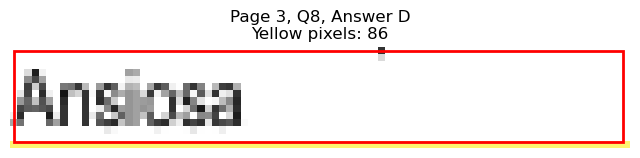

Page 3, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=373.7, y1=670.1
Page 3, Q8, E: Yellow pixels: 1074
Page 3, Q8, E: Total non-white pixels: 1358
Page 3, Q8, E: Yellow percentage: 79.1%


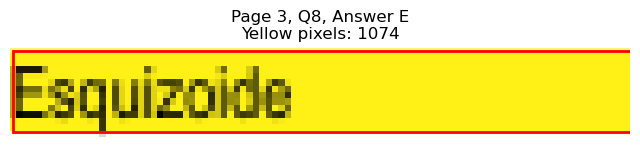


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=139.6, y1=720.6
Page 3, Q9, A: Yellow pixels: 122
Page 3, Q9, A: Total non-white pixels: 494
Page 3, Q9, A: Yellow percentage: 24.7%


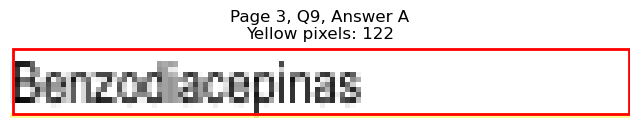

Page 3, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=121.9, y1=733.2
Page 3, Q9, B: Yellow pixels: 1106
Page 3, Q9, B: Total non-white pixels: 1456
Page 3, Q9, B: Yellow percentage: 76.0%


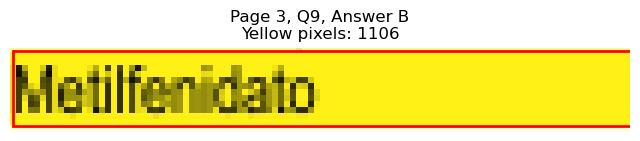

Page 3, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=112.5, y1=745.8
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 330
Page 3, Q9, C: Yellow percentage: 0.0%


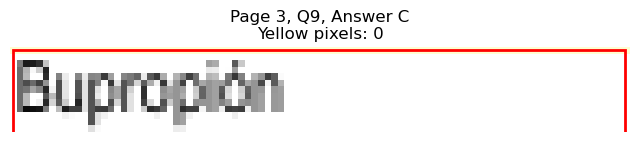

Page 3, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=437.3, y1=720.6
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 584
Page 3, Q9, D: Yellow percentage: 0.0%


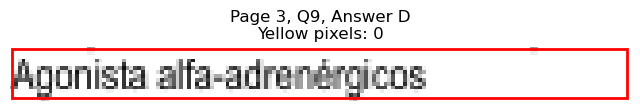

Page 3, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=377.3, y1=733.2
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 288
Page 3, Q9, E: Yellow percentage: 0.0%


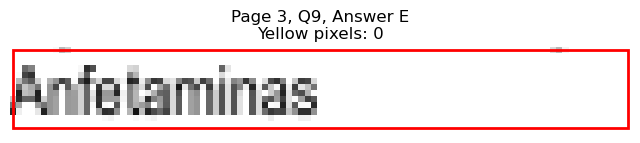


Page 3, Q9 - Selected Answer: B (based on yellow pixel count)





Page 4: Found 10 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=150.5, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 453
Page 4, Q1, A: Yellow percentage: 0.0%


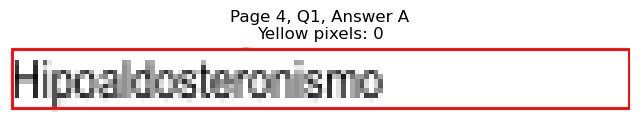

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=136.5, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 380
Page 4, Q1, B: Yellow percentage: 0.0%


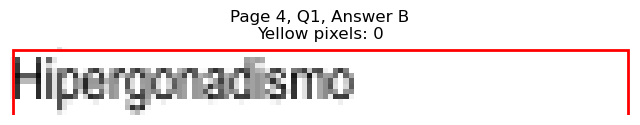

Page 4, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=136.0, y1=127.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 363
Page 4, Q1, C: Yellow percentage: 0.0%


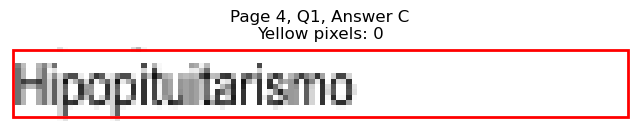

Page 4, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=408.3, y1=102.1
Page 4, Q1, D: Yellow pixels: 132
Page 4, Q1, D: Total non-white pixels: 571
Page 4, Q1, D: Yellow percentage: 23.1%


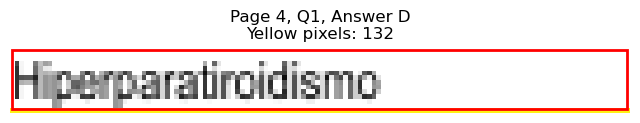

Page 4, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=386.7, y1=114.7
Page 4, Q1, E: Yellow pixels: 1178
Page 4, Q1, E: Total non-white pixels: 1430
Page 4, Q1, E: Yellow percentage: 82.4%


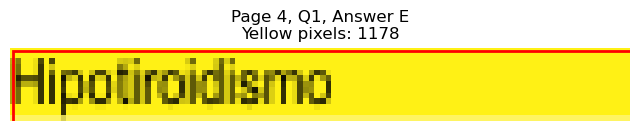


Page 4, Q1 - Selected Answer: E (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=98.9, y1=165.2
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 139
Page 4, Q2, A: Yellow percentage: 0.0%


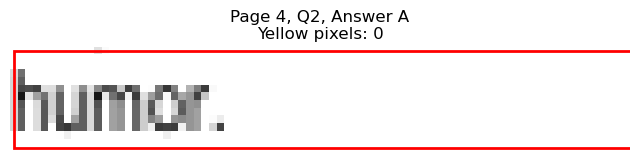

Page 4, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=102.4, y1=177.8
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 151
Page 4, Q2, B: Yellow percentage: 0.0%


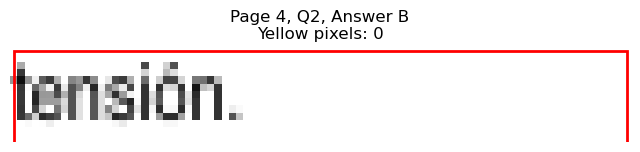

Page 4, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=97.9, y1=190.4
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 147
Page 4, Q2, C: Yellow percentage: 0.0%


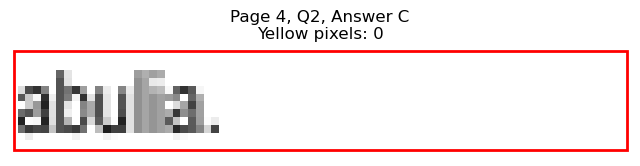

Page 4, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=357.2, y1=165.2
Page 4, Q2, D: Yellow pixels: 944
Page 4, Q2, D: Total non-white pixels: 1134
Page 4, Q2, D: Yellow percentage: 83.2%


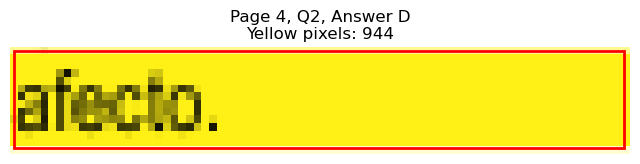

Page 4, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=364.1, y1=177.8
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 272
Page 4, Q2, E: Yellow percentage: 0.0%


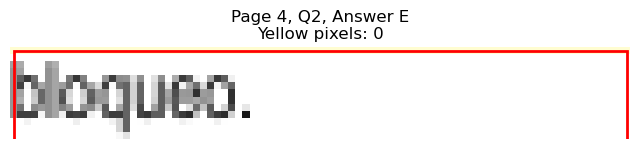


Page 4, Q2 - Selected Answer: D (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=111.4, y1=240.9
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 289
Page 4, Q3, A: Yellow percentage: 0.0%


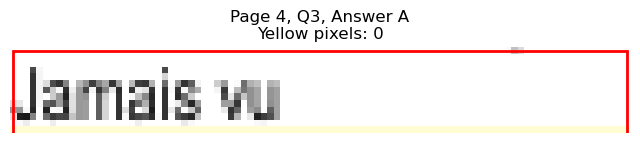

Page 4, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=101.4, y1=253.5
Page 4, Q3, B: Yellow pixels: 973
Page 4, Q3, B: Total non-white pixels: 1176
Page 4, Q3, B: Yellow percentage: 82.7%


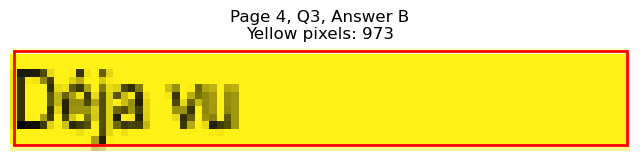

Page 4, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=113.4, y1=266.1
Page 4, Q3, C: Yellow pixels: 96
Page 4, Q3, C: Total non-white pixels: 316
Page 4, Q3, C: Yellow percentage: 30.4%


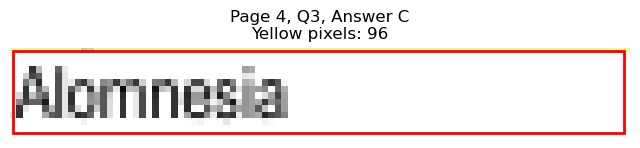

Page 4, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=378.2, y1=240.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 252
Page 4, Q3, D: Yellow percentage: 0.0%


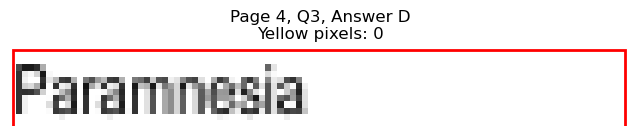

Page 4, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=364.6, y1=253.5
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 178
Page 4, Q3, E: Yellow percentage: 0.0%


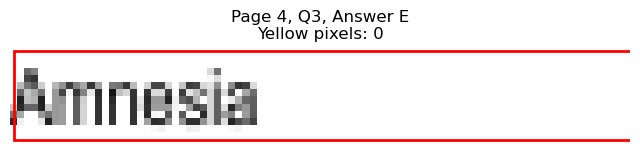


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=215.2, y1=304.1
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 759
Page 4, Q4, A: Yellow percentage: 0.0%


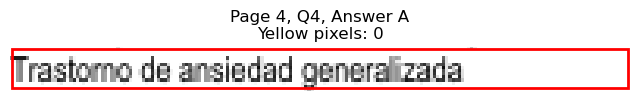

Page 4, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=153.0, y1=316.7
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 384
Page 4, Q4, B: Yellow percentage: 0.0%


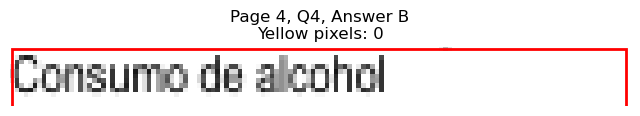

Page 4, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=119.4, y1=329.3
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 250
Page 4, Q4, C: Yellow percentage: 0.0%


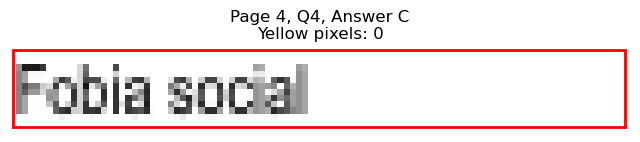

Page 4, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=406.3, y1=304.1
Page 4, Q4, D: Yellow pixels: 1379
Page 4, Q4, D: Total non-white pixels: 1820
Page 4, Q4, D: Yellow percentage: 75.8%


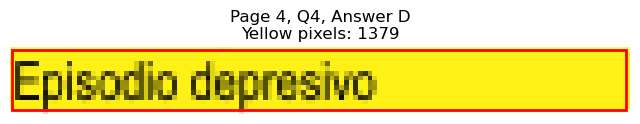

Page 4, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=474.0, y1=316.7
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 933
Page 4, Q4, E: Yellow percentage: 0.0%


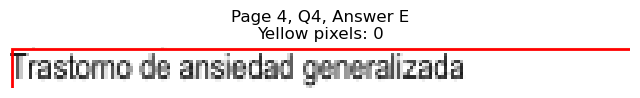


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=115.5, y1=367.2
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 251
Page 4, Q5, A: Yellow percentage: 0.0%


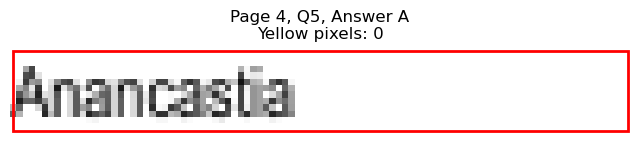

Page 4, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=115.5, y1=379.8
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 351
Page 4, Q5, B: Yellow percentage: 0.0%


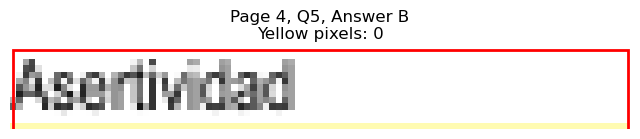

Page 4, Q5 - C: Detected box: x0=68.8, y0=379.7, x1=124.9, y1=392.4
Page 4, Q5, C: Yellow pixels: 1046
Page 4, Q5, C: Total non-white pixels: 1498
Page 4, Q5, C: Yellow percentage: 69.8%


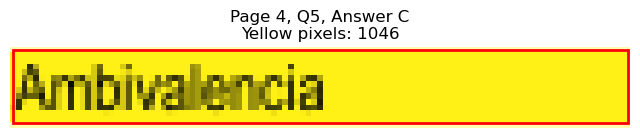

Page 4, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=373.7, y1=367.2
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 224
Page 4, Q5, D: Yellow percentage: 0.0%


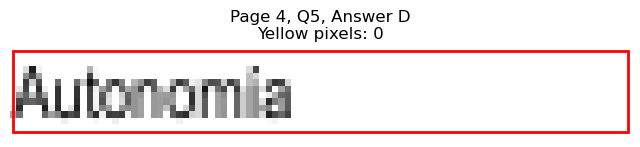

Page 4, Q5 - E: Detected box: x0=327.0, y0=367.1, x1=367.7, y1=379.8
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 197
Page 4, Q5, E: Yellow percentage: 0.0%


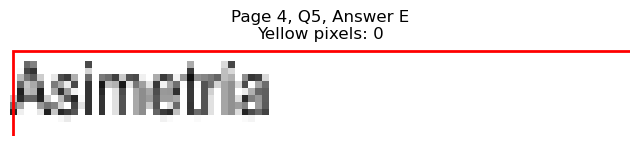


Page 4, Q5 - Selected Answer: C (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=131.1, y1=468.1
Page 4, Q6, A: Yellow pixels: 1225
Page 4, Q6, A: Total non-white pixels: 1596
Page 4, Q6, A: Yellow percentage: 76.8%


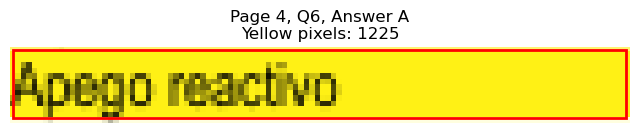

Page 4, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=128.5, y1=480.7
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 423
Page 4, Q6, B: Yellow percentage: 0.0%


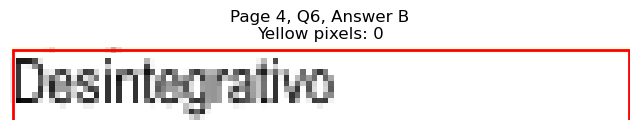

Page 4, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=112.5, y1=493.4
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 236
Page 4, Q6, C: Yellow percentage: 0.0%


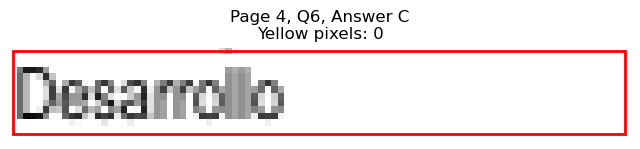

Page 4, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=393.2, y1=468.1
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 361
Page 4, Q6, D: Yellow percentage: 0.0%


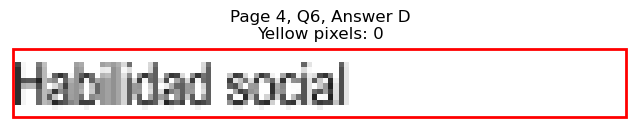

Page 4, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=389.7, y1=480.7
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 318
Page 4, Q6, E: Yellow percentage: 0.0%


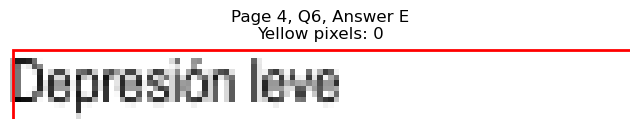


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=106.9, y1=543.8
Page 4, Q7, A: Yellow pixels: 987
Page 4, Q7, A: Total non-white pixels: 1157
Page 4, Q7, A: Yellow percentage: 85.3%


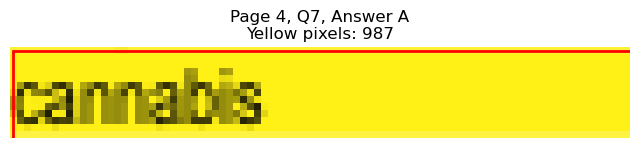

Page 4, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=99.4, y1=556.4
Page 4, Q7, B: Yellow pixels: 82
Page 4, Q7, B: Total non-white pixels: 245
Page 4, Q7, B: Yellow percentage: 33.5%


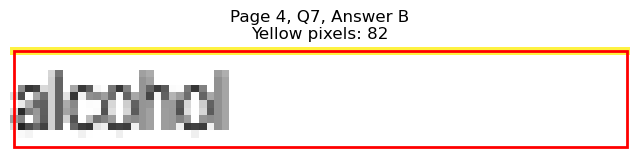

Page 4, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=102.9, y1=569.2
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 152
Page 4, Q7, C: Yellow percentage: 0.0%


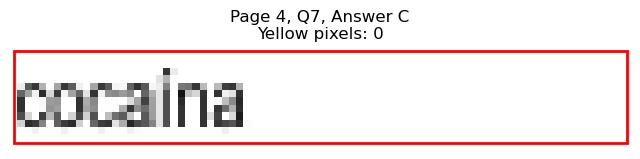

Page 4, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=397.7, y1=543.8
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 361
Page 4, Q7, D: Yellow percentage: 0.0%


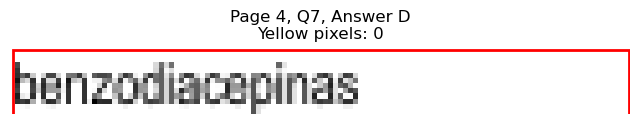

Page 4, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=356.7, y1=556.4
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 144
Page 4, Q7, E: Yellow percentage: 0.0%


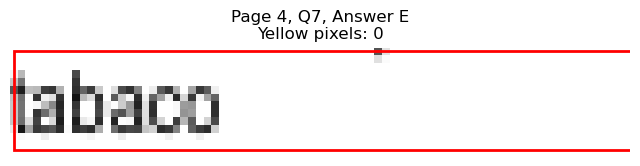


Page 4, Q7 - Selected Answer: A (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=130.5, y1=607.0
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 296
Page 4, Q8, A: Yellow percentage: 0.0%


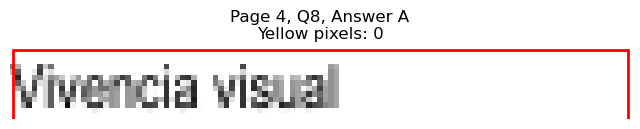

Page 4, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=145.6, y1=619.6
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 356
Page 4, Q8, B: Yellow percentage: 0.0%


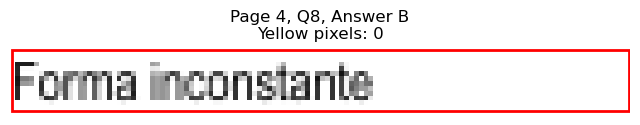

Page 4, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=150.5, y1=632.3
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 390
Page 4, Q8, C: Yellow percentage: 0.0%


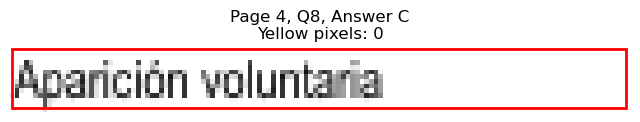

Page 4, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=410.8, y1=607.0
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 586
Page 4, Q8, D: Yellow percentage: 0.0%


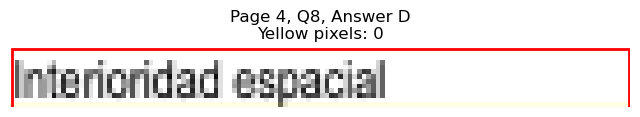

Page 4, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=398.8, y1=619.6
Page 4, Q8, E: Yellow pixels: 1311
Page 4, Q8, E: Total non-white pixels: 1708
Page 4, Q8, E: Yellow percentage: 76.8%


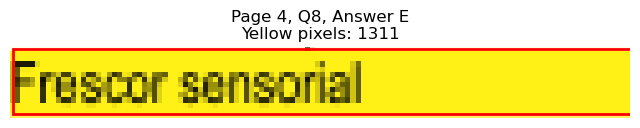


Page 4, Q8 - Selected Answer: E (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=115.9, y1=670.1
Page 4, Q9, A: Yellow pixels: 98
Page 4, Q9, A: Total non-white pixels: 342
Page 4, Q9, A: Yellow percentage: 28.7%


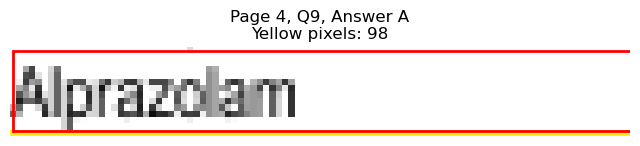

Page 4, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=107.9, y1=682.7
Page 4, Q9, B: Yellow pixels: 995
Page 4, Q9, B: Total non-white pixels: 1170
Page 4, Q9, B: Yellow percentage: 85.0%


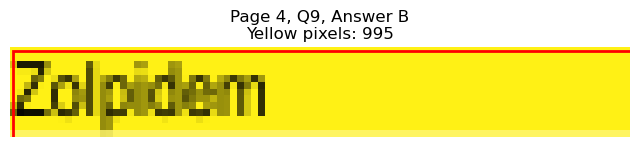

Page 4, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=121.9, y1=695.3
Page 4, Q9, C: Yellow pixels: 104
Page 4, Q9, C: Total non-white pixels: 374
Page 4, Q9, C: Yellow percentage: 27.8%


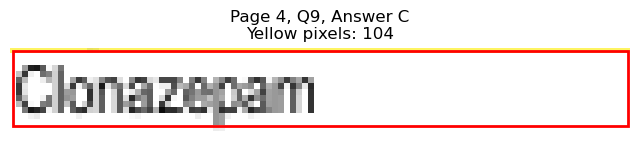

Page 4, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=378.7, y1=670.1
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 278
Page 4, Q9, D: Yellow percentage: 0.0%


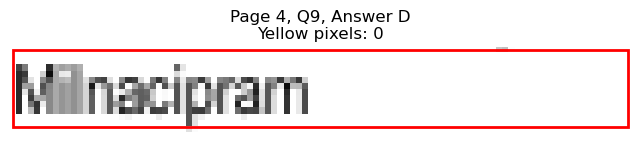

Page 4, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=369.2, y1=682.7
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 195
Page 4, Q9, E: Yellow percentage: 0.0%


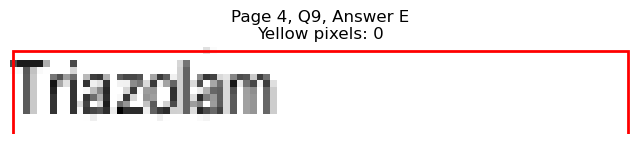


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=182.7, y1=745.8
Page 4, Q10, A: Yellow pixels: 0
Page 4, Q10, A: Total non-white pixels: 607
Page 4, Q10, A: Yellow percentage: 0.0%


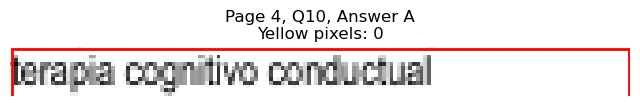

Page 4, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=155.1, y1=758.4
Page 4, Q10, B: Yellow pixels: 0
Page 4, Q10, B: Total non-white pixels: 448
Page 4, Q10, B: Yellow percentage: 0.0%


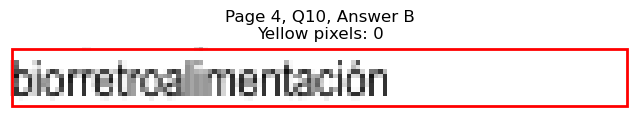

Page 4, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=153.5, y1=771.2
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 435
Page 4, Q10, C: Yellow percentage: 0.0%


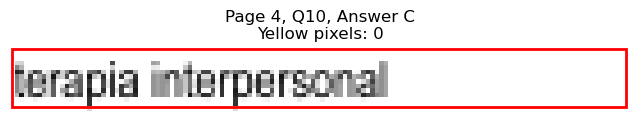

Page 4, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=381.2, y1=745.8
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 403
Page 4, Q10, D: Yellow percentage: 0.0%


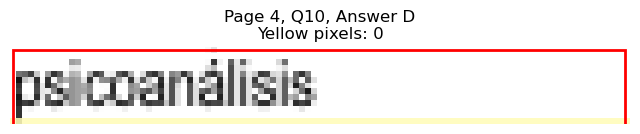

Page 4, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=440.9, y1=758.4
Page 4, Q10, E: Yellow pixels: 1684
Page 4, Q10, E: Total non-white pixels: 2296
Page 4, Q10, E: Yellow percentage: 73.3%


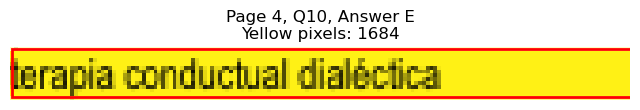


Page 4, Q10 - Selected Answer: E (based on yellow pixel count)





Page 5: Found 9 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=121.6, y1=114.7
Page 5, Q1, A: Yellow pixels: 3
Page 5, Q1, A: Total non-white pixels: 403
Page 5, Q1, A: Yellow percentage: 0.7%


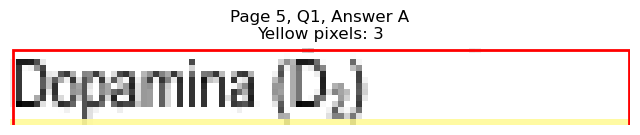

Page 5, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=120.5, y1=127.3
Page 5, Q1, B: Yellow pixels: 1017
Page 5, Q1, B: Total non-white pixels: 1442
Page 5, Q1, B: Yellow percentage: 70.5%


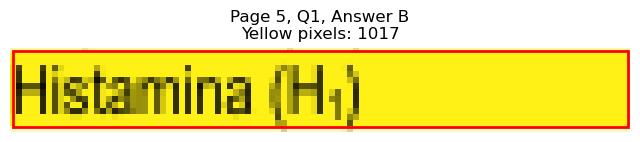

Page 5, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=130.5, y1=139.9
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 467
Page 5, Q1, C: Yellow percentage: 0.0%


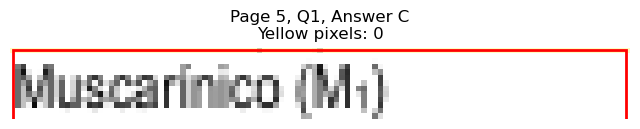

Page 5, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=402.3, y1=114.7
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 381
Page 5, Q1, D: Yellow percentage: 0.0%


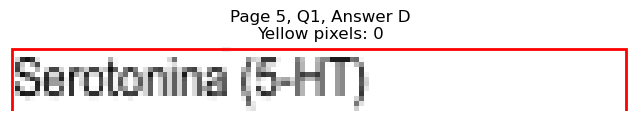

Page 5, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=402.8, y1=127.3
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 404
Page 5, Q1, E: Yellow percentage: 0.0%


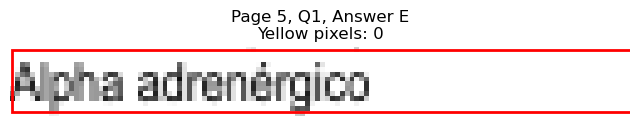


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=128.5, y1=215.6
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 299
Page 5, Q2, A: Yellow percentage: 0.0%


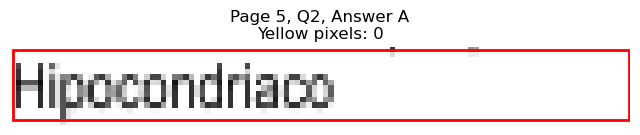

Page 5, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=102.9, y1=228.3
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 178
Page 5, Q2, B: Yellow percentage: 0.0%


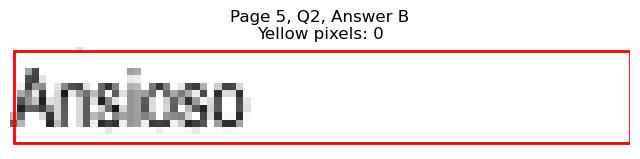

Page 5, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=115.0, y1=240.9
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 236
Page 5, Q2, C: Yellow percentage: 0.0%


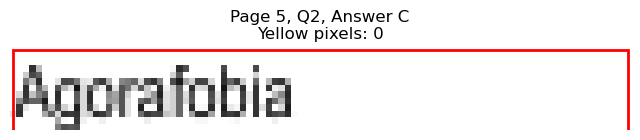

Page 5, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=395.7, y1=215.6
Page 5, Q2, D: Yellow pixels: 1274
Page 5, Q2, D: Total non-white pixels: 1666
Page 5, Q2, D: Yellow percentage: 76.5%


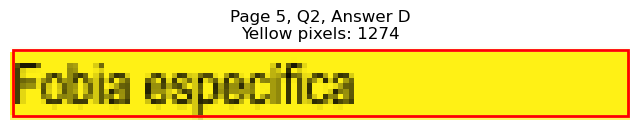

Page 5, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=414.8, y1=228.3
Page 5, Q2, E: Yellow pixels: 138
Page 5, Q2, E: Total non-white pixels: 583
Page 5, Q2, E: Yellow percentage: 23.7%


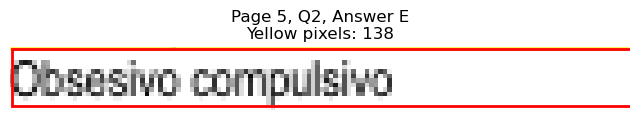


Page 5, Q2 - Selected Answer: D (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=121.5, y1=291.5
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 284
Page 5, Q3, A: Yellow percentage: 0.0%


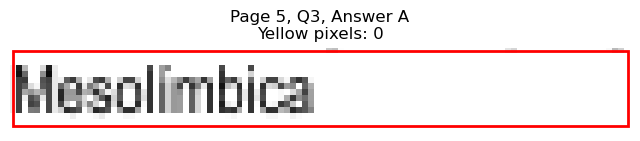

Page 5, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=124.0, y1=304.1
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 314
Page 5, Q3, B: Yellow percentage: 0.0%


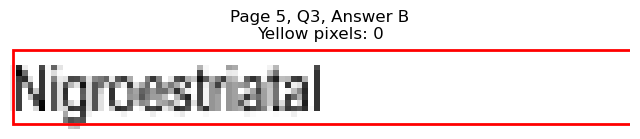

Page 5, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=146.5, y1=316.7
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 402
Page 5, Q3, C: Yellow percentage: 0.0%


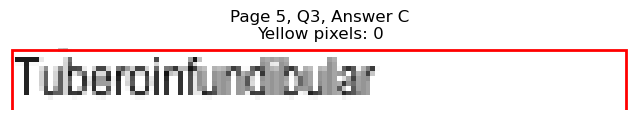

Page 5, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=360.7, y1=291.5
Page 5, Q3, D: Yellow pixels: 84
Page 5, Q3, D: Total non-white pixels: 251
Page 5, Q3, D: Yellow percentage: 33.5%


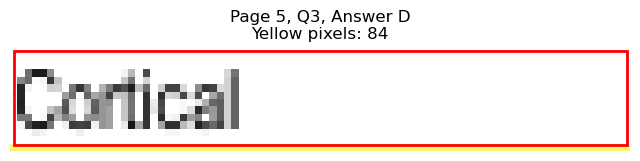

Page 5, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=380.2, y1=304.1
Page 5, Q3, E: Yellow pixels: 1131
Page 5, Q3, E: Total non-white pixels: 1456
Page 5, Q3, E: Yellow percentage: 77.7%


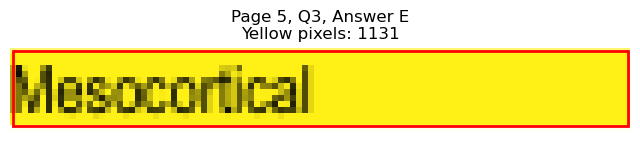


Page 5, Q3 - Selected Answer: E (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=112.0, y1=354.6
Page 5, Q4, A: Yellow pixels: 94
Page 5, Q4, A: Total non-white pixels: 313
Page 5, Q4, A: Yellow percentage: 30.0%


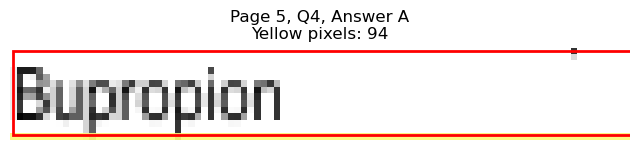

Page 5, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=112.5, y1=367.2
Page 5, Q4, B: Yellow pixels: 1066
Page 5, Q4, B: Total non-white pixels: 1330
Page 5, Q4, B: Yellow percentage: 80.2%


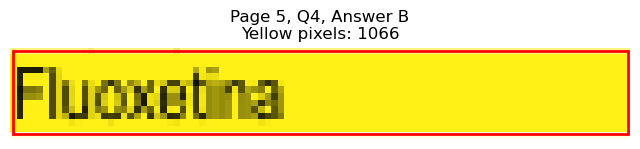

Page 5, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=115.9, y1=379.8
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 327
Page 5, Q4, C: Yellow percentage: 0.0%


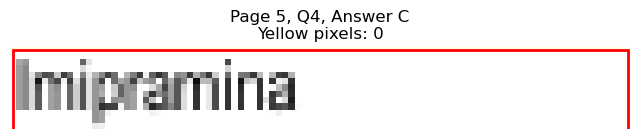

Page 5, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=383.7, y1=354.6
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 299
Page 5, Q4, D: Yellow percentage: 0.0%


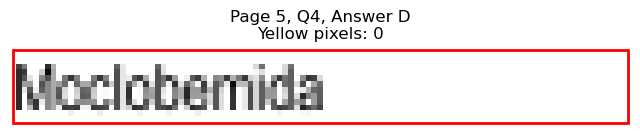

Page 5, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=372.2, y1=367.2
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 221
Page 5, Q4, E: Yellow percentage: 0.0%


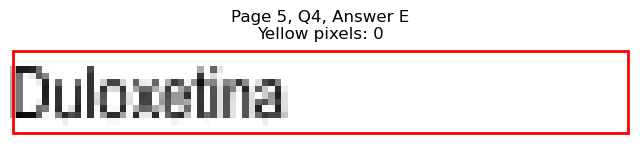


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=90.4, y1=442.9
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 168
Page 5, Q5, A: Yellow percentage: 0.0%


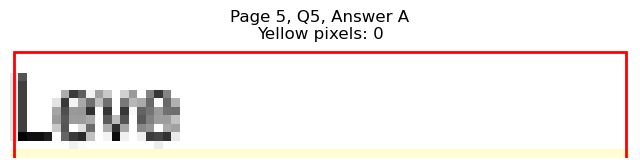

Page 5, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=105.9, y1=455.5
Page 5, Q5, B: Yellow pixels: 1003
Page 5, Q5, B: Total non-white pixels: 1232
Page 5, Q5, B: Yellow percentage: 81.4%


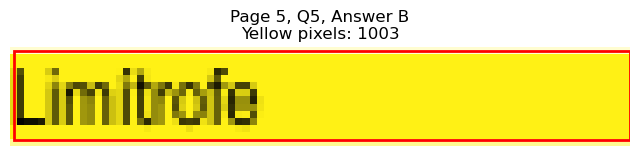

Page 5, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=111.9, y1=468.1
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 221
Page 5, Q5, C: Yellow percentage: 0.0%


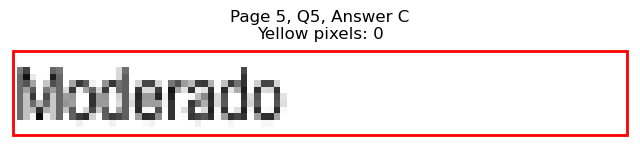

Page 5, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=354.8, y1=442.9
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 120
Page 5, Q5, D: Yellow percentage: 0.0%


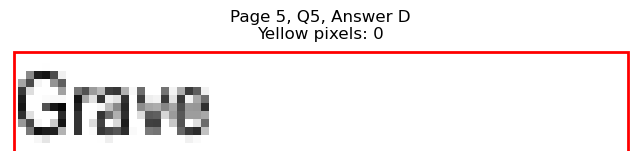

Page 5, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=366.2, y1=455.5
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 188
Page 5, Q5, E: Yellow percentage: 0.0%


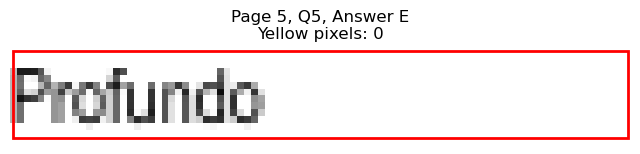


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=199.7, y1=506.0
Page 5, Q6, A: Yellow pixels: 182
Page 5, Q6, A: Total non-white pixels: 1017
Page 5, Q6, A: Yellow percentage: 17.9%


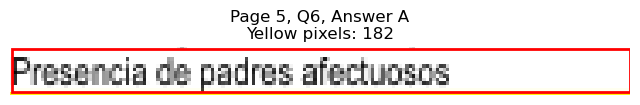

Page 5, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=266.9, y1=518.6
Page 5, Q6, B: Yellow pixels: 2002
Page 5, Q6, B: Total non-white pixels: 3004
Page 5, Q6, B: Yellow percentage: 66.6%


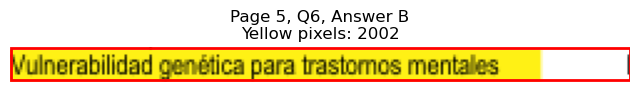

Page 5, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=176.7, y1=531.2
Page 5, Q6, C: Yellow pixels: 158
Page 5, Q6, C: Total non-white pixels: 682
Page 5, Q6, C: Yellow percentage: 23.2%


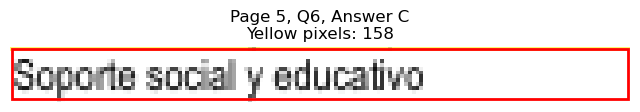

Page 5, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=393.8, y1=506.0
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 329
Page 5, Q6, D: Yellow percentage: 0.0%


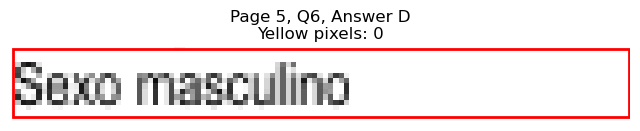

Page 5, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=417.9, y1=518.6
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 466
Page 5, Q6, E: Yellow percentage: 0.0%


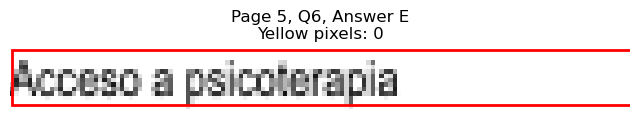


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=139.0, y1=594.4
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 364
Page 5, Q7, A: Yellow percentage: 0.0%


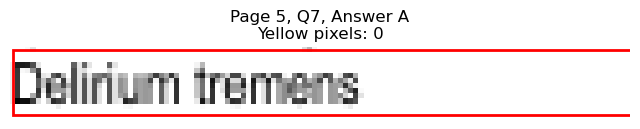

Page 5, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=101.9, y1=607.0
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 166
Page 5, Q7, B: Yellow percentage: 0.0%


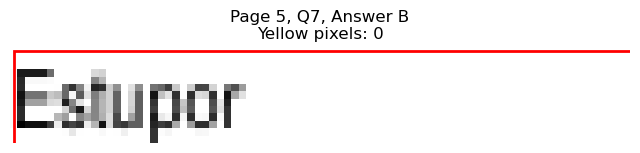

Page 5, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=96.9, y1=619.6
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 158
Page 5, Q7, C: Yellow percentage: 0.0%


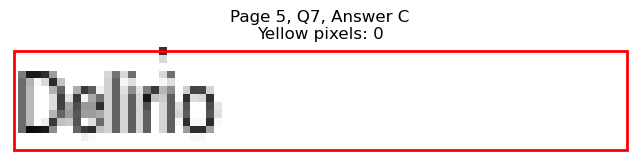

Page 5, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=384.8, y1=594.4
Page 5, Q7, D: Yellow pixels: 108
Page 5, Q7, D: Total non-white pixels: 427
Page 5, Q7, D: Yellow percentage: 25.3%


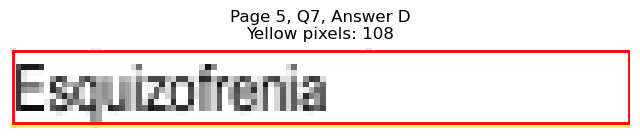

Page 5, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=368.2, y1=607.0
Page 5, Q7, E: Yellow pixels: 1040
Page 5, Q7, E: Total non-white pixels: 1196
Page 5, Q7, E: Yellow percentage: 87.0%


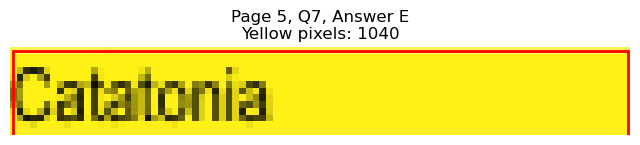


Page 5, Q7 - Selected Answer: E (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=112.0, y1=657.5
Page 5, Q8, A: Yellow pixels: 94
Page 5, Q8, A: Total non-white pixels: 314
Page 5, Q8, A: Yellow percentage: 29.9%


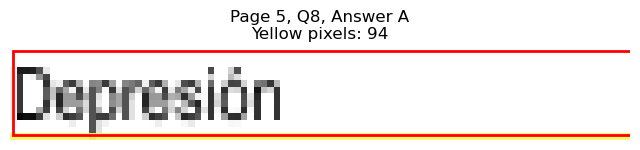

Page 5, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=125.5, y1=670.1
Page 5, Q8, B: Yellow pixels: 1161
Page 5, Q8, B: Total non-white pixels: 1512
Page 5, Q8, B: Yellow percentage: 76.8%


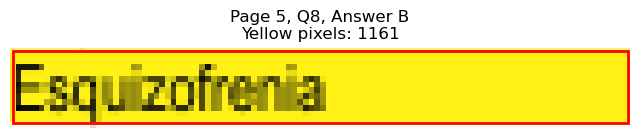

Page 5, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=195.6, y1=682.7
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 805
Page 5, Q8, C: Yellow percentage: 0.0%


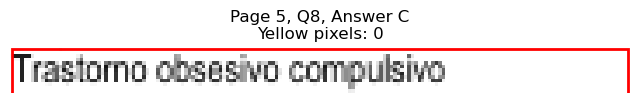

Page 5, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=467.5, y1=657.5
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 692
Page 5, Q8, D: Yellow percentage: 0.0%


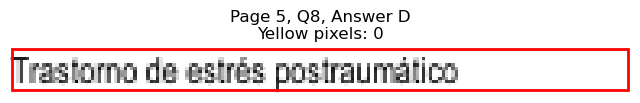

Page 5, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=466.5, y1=670.1
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 649
Page 5, Q8, E: Yellow percentage: 0.0%


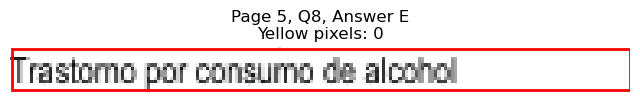


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=150.0, y1=733.2
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 424
Page 5, Q9, A: Yellow percentage: 0.0%


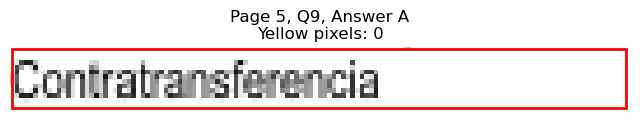

Page 5, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=150.5, y1=745.8
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 555
Page 5, Q9, B: Yellow percentage: 0.0%


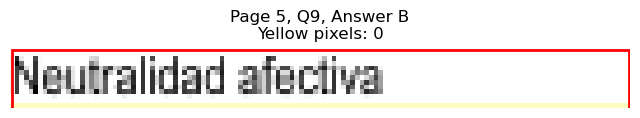

Page 5, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=126.5, y1=758.4
Page 5, Q9, C: Yellow pixels: 1199
Page 5, Q9, C: Total non-white pixels: 1526
Page 5, Q9, C: Yellow percentage: 78.6%


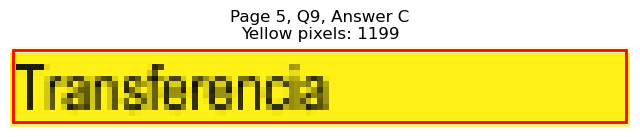

Page 5, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=384.2, y1=733.2
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 295
Page 5, Q9, D: Yellow percentage: 0.0%


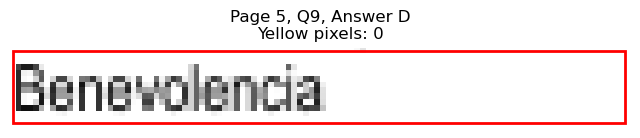

Page 5, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=363.2, y1=745.8
Page 5, Q9, E: Yellow pixels: 0
Page 5, Q9, E: Total non-white pixels: 178
Page 5, Q9, E: Yellow percentage: 0.0%


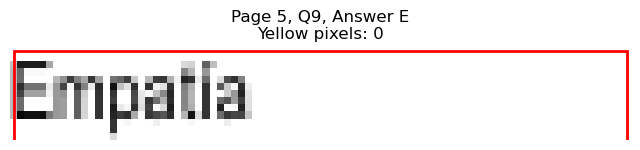


Page 5, Q9 - Selected Answer: C (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=112.0, y1=102.1
Page 6, Q1, A: Yellow pixels: 1066
Page 6, Q1, A: Total non-white pixels: 1316
Page 6, Q1, A: Yellow percentage: 81.0%


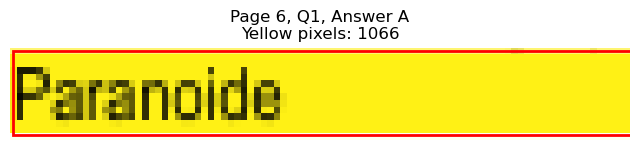

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=112.9, y1=114.7
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 340
Page 6, Q1, B: Yellow percentage: 0.0%


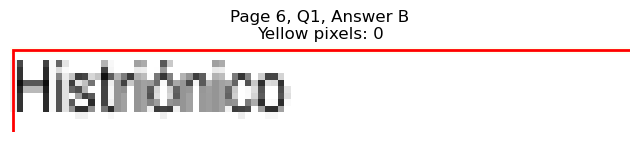

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=110.9, y1=127.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 225
Page 6, Q1, C: Yellow percentage: 0.0%


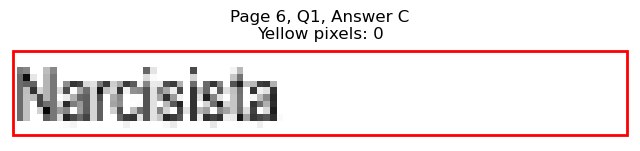

Page 6, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=365.1, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 167
Page 6, Q1, D: Yellow percentage: 0.0%


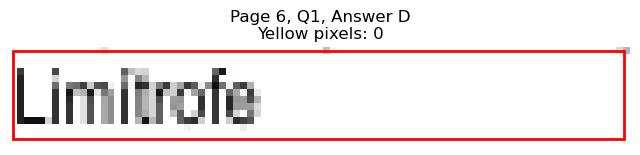

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=368.2, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 211
Page 6, Q1, E: Yellow percentage: 0.0%


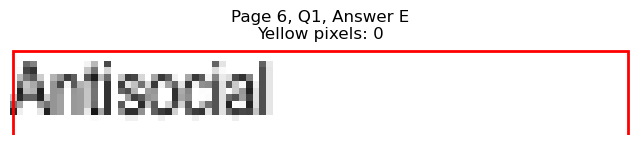


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=230.8, y1=177.8
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 827
Page 6, Q2, A: Yellow percentage: 0.0%


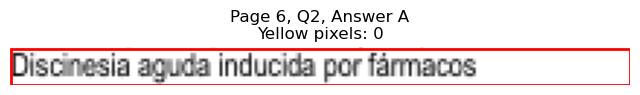

Page 6, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=195.7, y1=190.4
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 660
Page 6, Q2, B: Yellow percentage: 0.0%


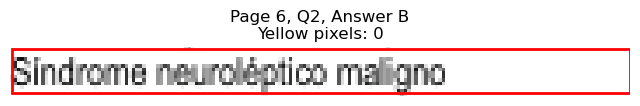

Page 6, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=223.2, y1=203.0
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 768
Page 6, Q2, C: Yellow percentage: 0.0%


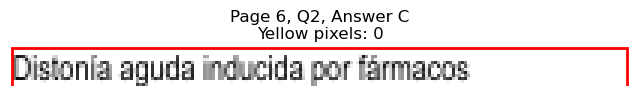

Page 6, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=480.5, y1=177.8
Page 6, Q2, D: Yellow pixels: 2057
Page 6, Q2, D: Total non-white pixels: 2652
Page 6, Q2, D: Yellow percentage: 77.6%


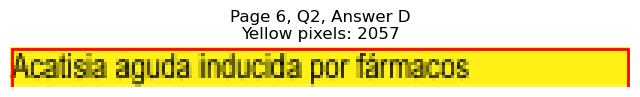

Page 6, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=454.0, y1=190.4
Page 6, Q2, E: Yellow pixels: 176
Page 6, Q2, E: Total non-white pixels: 787
Page 6, Q2, E: Yellow percentage: 22.4%


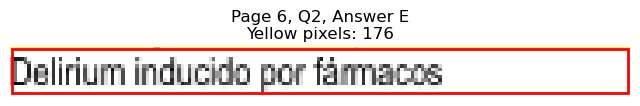


Page 6, Q2 - Selected Answer: D (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=109.5, y1=253.5
Page 6, Q3, A: Yellow pixels: 92
Page 6, Q3, A: Total non-white pixels: 323
Page 6, Q3, A: Yellow percentage: 28.5%


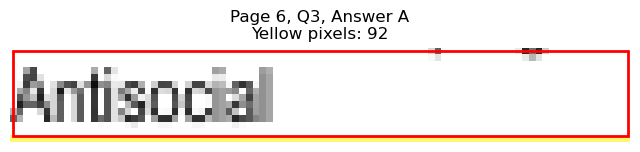

Page 6, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=127.9, y1=266.1
Page 6, Q3, B: Yellow pixels: 1224
Page 6, Q3, B: Total non-white pixels: 1540
Page 6, Q3, B: Yellow percentage: 79.5%


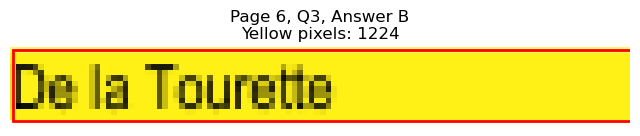

Page 6, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=126.5, y1=278.7
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 392
Page 6, Q3, C: Yellow percentage: 0.0%


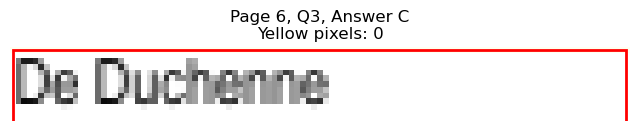

Page 6, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=413.3, y1=253.5
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 440
Page 6, Q3, D: Yellow percentage: 0.0%


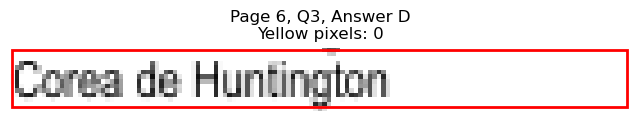

Page 6, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=370.7, y1=266.1
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 244
Page 6, Q3, E: Yellow percentage: 0.0%


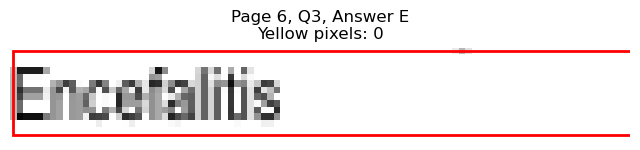


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=168.6, y1=354.6
Page 6, Q4, A: Yellow pixels: 1565
Page 6, Q4, A: Total non-white pixels: 2114
Page 6, Q4, A: Yellow percentage: 74.0%


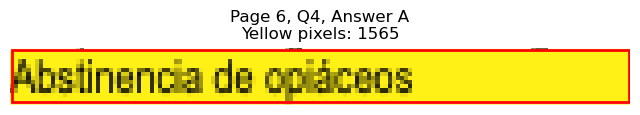

Page 6, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=163.6, y1=367.2
Page 6, Q4, B: Yellow pixels: 146
Page 6, Q4, B: Total non-white pixels: 618
Page 6, Q4, B: Yellow percentage: 23.6%


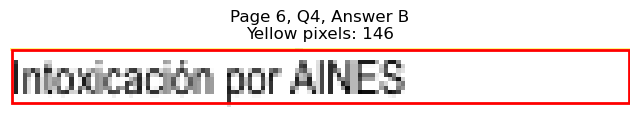

Page 6, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=150.5, y1=379.8
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 415
Page 6, Q4, C: Yellow percentage: 0.0%


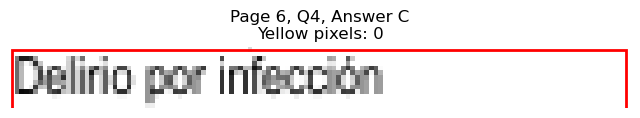

Page 6, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=399.3, y1=354.6
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 363
Page 6, Q4, D: Yellow percentage: 0.0%


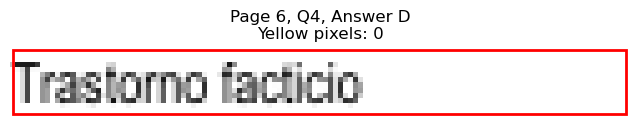

Page 6, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=393.8, y1=367.2
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 326
Page 6, Q4, E: Yellow percentage: 0.0%


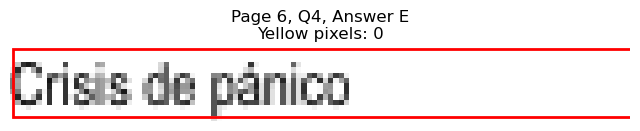


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=405.0, x1=90.4, y1=417.7
Page 6, Q5, A: Yellow pixels: 2
Page 6, Q5, A: Total non-white pixels: 162
Page 6, Q5, A: Yellow percentage: 1.2%


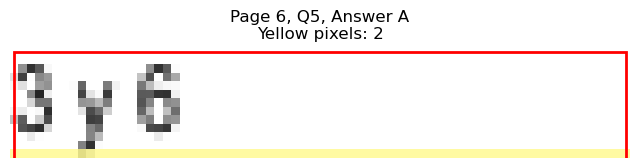

Page 6, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=90.4, y1=430.3
Page 6, Q5, B: Yellow pixels: 819
Page 6, Q5, B: Total non-white pixels: 1022
Page 6, Q5, B: Yellow percentage: 80.1%


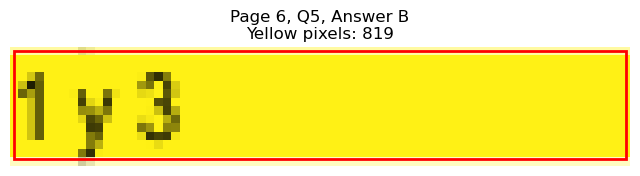

Page 6, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=98.4, y1=442.9
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 191
Page 6, Q5, C: Yellow percentage: 0.0%


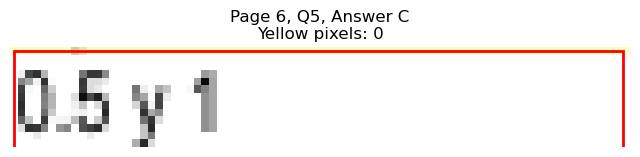

Page 6, Q5 - D: Detected box: x0=327.5, y0=405.0, x1=362.2, y1=417.7
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 143
Page 6, Q5, D: Yellow percentage: 0.0%


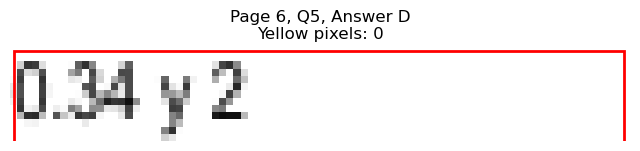

Page 6, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=356.7, y1=430.3
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 126
Page 6, Q5, E: Yellow percentage: 0.0%


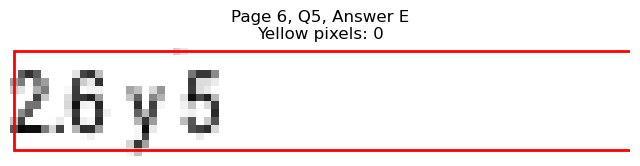


Page 6, Q5 - Selected Answer: B (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=252.9, y1=506.0
Page 6, Q6, A: Yellow pixels: 2041
Page 6, Q6, A: Total non-white pixels: 2785
Page 6, Q6, A: Yellow percentage: 73.3%


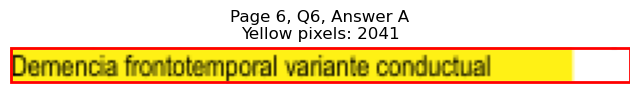

Page 6, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=194.8, y1=518.6
Page 6, Q6, B: Yellow pixels: 176
Page 6, Q6, B: Total non-white pixels: 760
Page 6, Q6, B: Yellow percentage: 23.2%


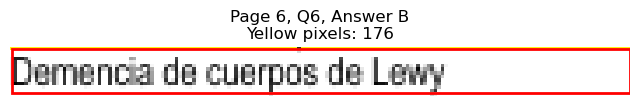

Page 6, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=243.4, y1=531.2
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 862
Page 6, Q6, C: Yellow percentage: 0.0%


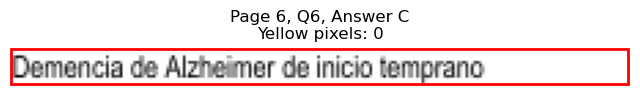

Page 6, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=399.8, y1=506.0
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 384
Page 6, Q6, D: Yellow percentage: 0.0%


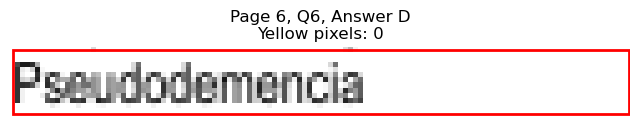

Page 6, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=425.3, y1=518.6
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 475
Page 6, Q6, E: Yellow percentage: 0.0%


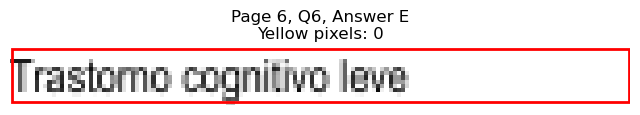


Page 6, Q6 - Selected Answer: A (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=116.9, y1=594.4
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 250
Page 6, Q7, A: Yellow percentage: 0.0%


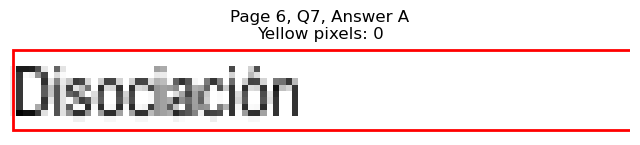

Page 6, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=133.9, y1=607.0
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 309
Page 6, Q7, B: Yellow percentage: 0.0%


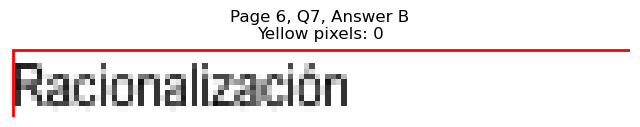

Page 6, Q7 - C: Detected box: x0=68.8, y0=607.0, x1=134.5, y1=619.7
Page 6, Q7, C: Yellow pixels: 1263
Page 6, Q7, C: Total non-white pixels: 1521
Page 6, Q7, C: Yellow percentage: 83.0%


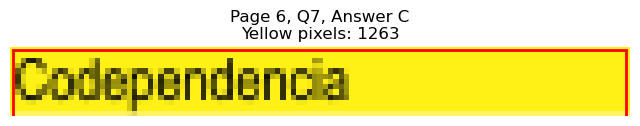

Page 6, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=395.7, y1=594.4
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 359
Page 6, Q7, D: Yellow percentage: 0.0%


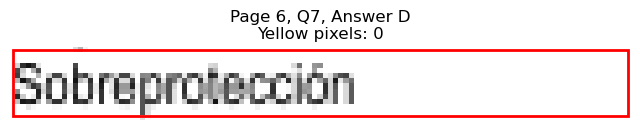

Page 6, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=371.7, y1=607.0
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 221
Page 6, Q7, E: Yellow percentage: 0.0%


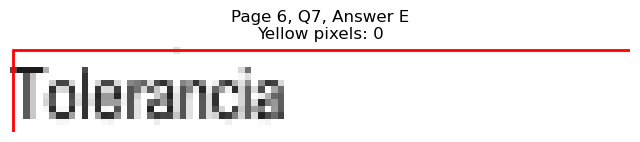


Page 6, Q7 - Selected Answer: C (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=98.9, y1=657.5
Page 6, Q8, A: Yellow pixels: 81
Page 6, Q8, A: Total non-white pixels: 246
Page 6, Q8, A: Yellow percentage: 32.9%


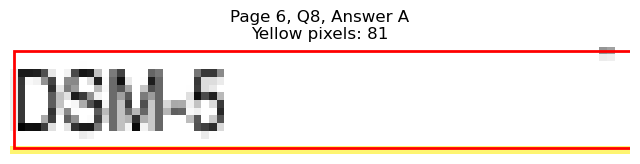

Page 6, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=117.4, y1=670.1
Page 6, Q8, B: Yellow pixels: 1123
Page 6, Q8, B: Total non-white pixels: 1400
Page 6, Q8, B: Yellow percentage: 80.2%


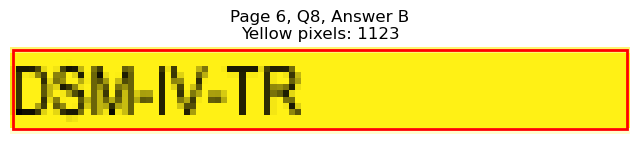

Page 6, Q8 - C: Detected box: x0=68.8, y0=670.2, x1=101.9, y1=682.8
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 257
Page 6, Q8, C: Yellow percentage: 0.0%


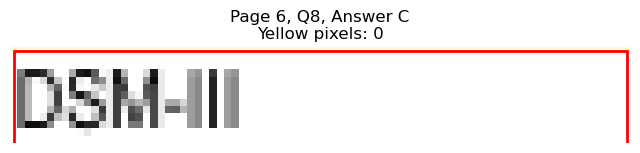

Page 6, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=350.1, y1=657.5
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 119
Page 6, Q8, D: Yellow percentage: 0.0%


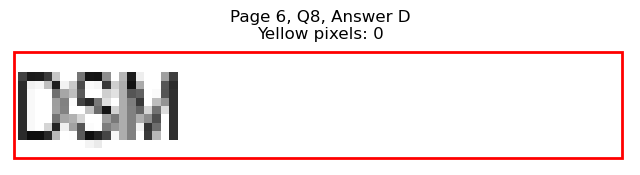

Page 6, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=361.1, y1=670.1
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 166
Page 6, Q8, E: Yellow percentage: 0.0%


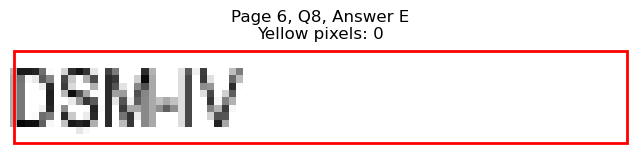


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=733.2, x1=150.0, y1=745.8
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 403
Page 6, Q9, A: Yellow percentage: 0.0%


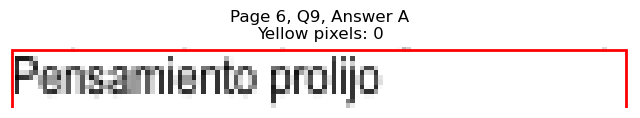

Page 6, Q9 - B: Detected box: x0=68.3, y0=745.9, x1=170.7, y1=758.6
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 528
Page 6, Q9, B: Yellow percentage: 0.0%


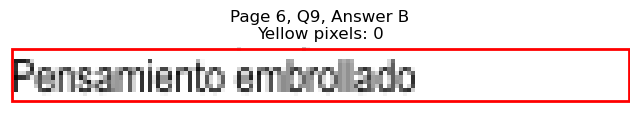

Page 6, Q9 - C: Detected box: x0=68.8, y0=758.5, x1=171.1, y1=771.2
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 534
Page 6, Q9, C: Yellow percentage: 0.0%


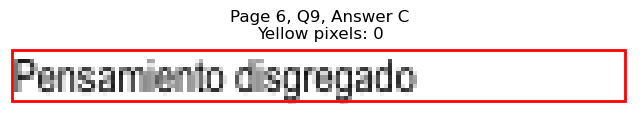

Page 6, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=387.2, y1=745.8
Page 6, Q9, D: Yellow pixels: 1209
Page 6, Q9, D: Total non-white pixels: 1443
Page 6, Q9, D: Yellow percentage: 83.8%


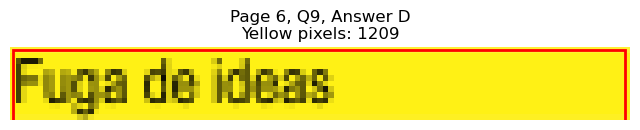

Page 6, Q9 - E: Detected box: x0=327.0, y0=745.9, x1=413.4, y1=758.6
Page 6, Q9, E: Yellow pixels: 136
Page 6, Q9, E: Total non-white pixels: 605
Page 6, Q9, E: Yellow percentage: 22.5%


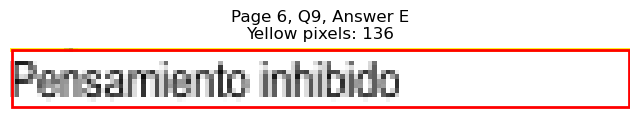


Page 6, Q9 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=80.9, y1=102.1
Page 7, Q1, A: Yellow pixels: 63
Page 7, Q1, A: Total non-white pixels: 130
Page 7, Q1, A: Yellow percentage: 48.5%


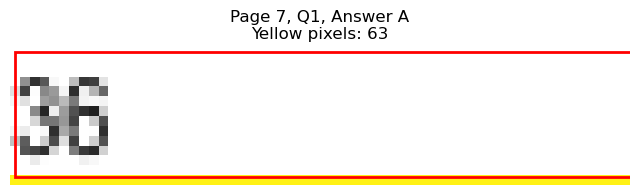

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=80.9, y1=114.7
Page 7, Q1, B: Yellow pixels: 781
Page 7, Q1, B: Total non-white pixels: 819
Page 7, Q1, B: Yellow percentage: 95.4%


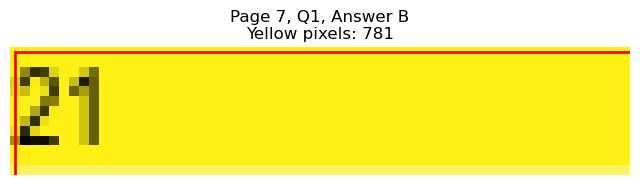

Page 7, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=81.4, y1=127.3
Page 7, Q1, C: Yellow pixels: 64
Page 7, Q1, C: Total non-white pixels: 119
Page 7, Q1, C: Yellow percentage: 53.8%


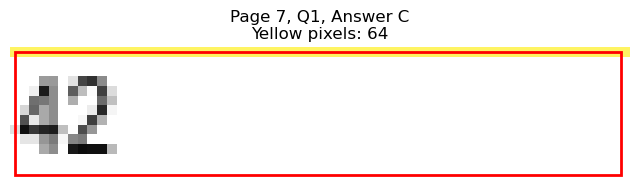

Page 7, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=340.1, y1=102.1
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 67
Page 7, Q1, D: Yellow percentage: 0.0%


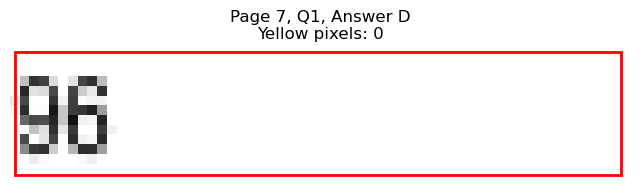

Page 7, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=339.7, y1=114.7
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 51
Page 7, Q1, E: Yellow percentage: 0.0%


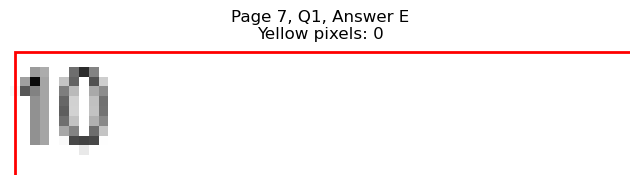


Page 7, Q1 - Selected Answer: B (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=171.6, y1=177.8
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 546
Page 7, Q2, A: Yellow percentage: 0.0%


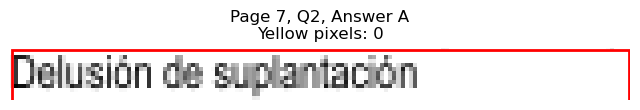

Page 7, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=189.1, y1=190.4
Page 7, Q2, B: Yellow pixels: 172
Page 7, Q2, B: Total non-white pixels: 794
Page 7, Q2, B: Yellow percentage: 21.7%


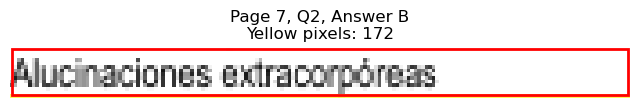

Page 7, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=207.8, y1=203.0
Page 7, Q2, C: Yellow pixels: 1899
Page 7, Q2, C: Total non-white pixels: 2470
Page 7, Q2, C: Yellow percentage: 76.9%


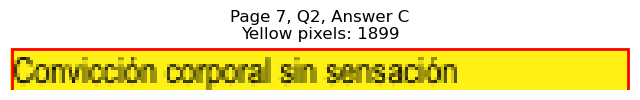

Page 7, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=427.9, y1=177.8
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 539
Page 7, Q2, D: Yellow percentage: 0.0%


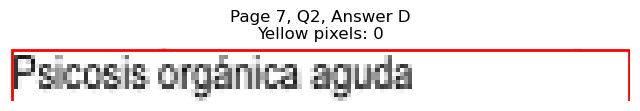

Page 7, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=432.4, y1=190.4
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 524
Page 7, Q2, E: Yellow percentage: 0.0%


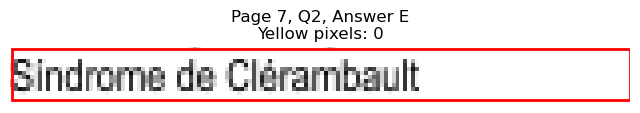


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=97.3, y1=240.9
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 143
Page 7, Q3, A: Yellow percentage: 0.0%


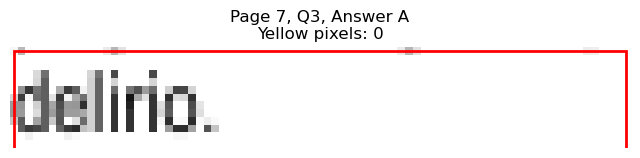

Page 7, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=112.0, y1=253.5
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 206
Page 7, Q3, B: Yellow percentage: 0.0%


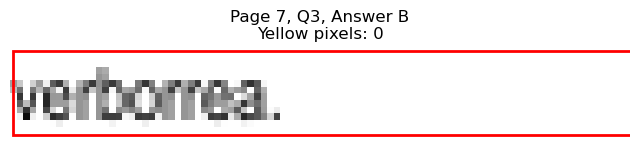

Page 7, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=119.9, y1=266.1
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 263
Page 7, Q3, C: Yellow percentage: 0.0%


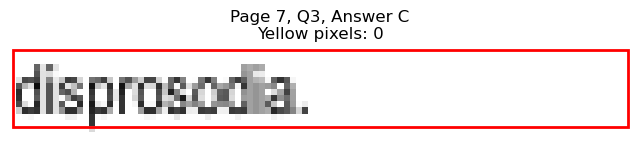

Page 7, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=370.1, y1=240.9
Page 7, Q3, D: Yellow pixels: 1045
Page 7, Q3, D: Total non-white pixels: 1222
Page 7, Q3, D: Yellow percentage: 85.5%


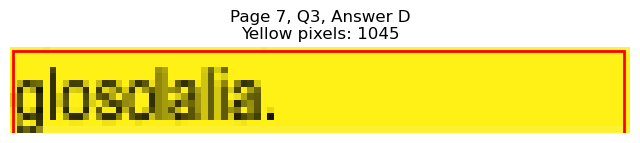

Page 7, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=380.2, y1=253.5
Page 7, Q3, E: Yellow pixels: 100
Page 7, Q3, E: Total non-white pixels: 375
Page 7, Q3, E: Yellow percentage: 26.7%


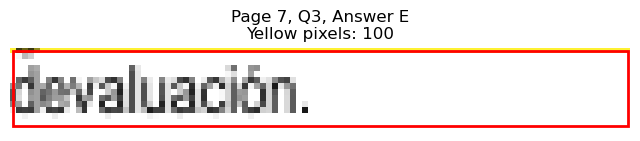


Page 7, Q3 - Selected Answer: D (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=119.4, y1=304.1
Page 7, Q4, A: Yellow pixels: 1094
Page 7, Q4, A: Total non-white pixels: 1428
Page 7, Q4, A: Yellow percentage: 76.6%


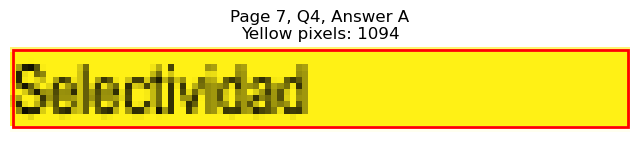

Page 7, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=119.9, y1=316.7
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 351
Page 7, Q4, B: Yellow percentage: 0.0%


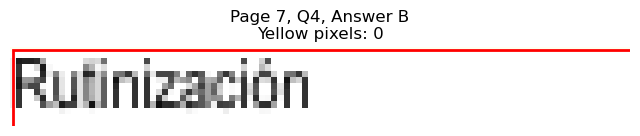

Page 7, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=128.4, y1=329.3
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 300
Page 7, Q4, C: Yellow percentage: 0.0%


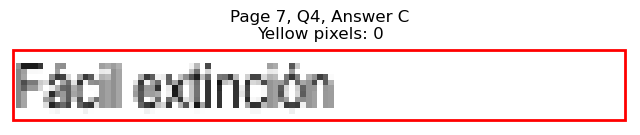

Page 7, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=382.3, y1=304.1
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 303
Page 7, Q4, D: Yellow percentage: 0.0%


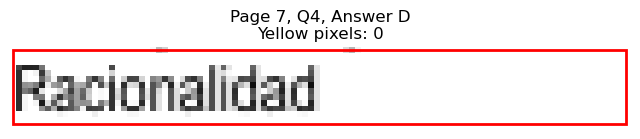

Page 7, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=388.7, y1=316.7
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 331
Page 7, Q4, E: Yellow percentage: 0.0%


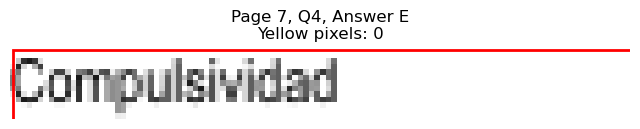


Page 7, Q4 - Selected Answer: A (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=103.5, y1=367.2
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 176
Page 7, Q5, A: Yellow percentage: 0.0%


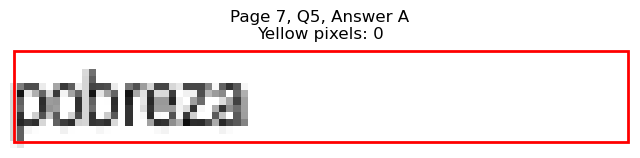

Page 7, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=104.4, y1=379.8
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 198
Page 7, Q5, B: Yellow percentage: 0.0%


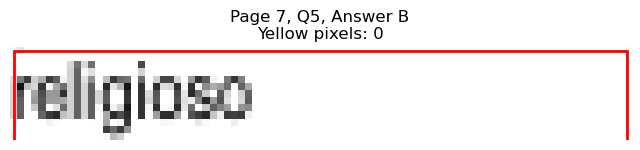

Page 7, Q5 - C: Detected box: x0=68.8, y0=379.7, x1=108.9, y1=392.4
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 211
Page 7, Q5, C: Yellow percentage: 0.0%


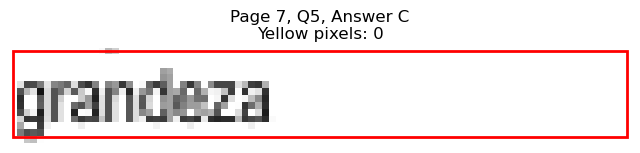

Page 7, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=351.7, y1=367.2
Page 7, Q5, D: Yellow pixels: 75
Page 7, Q5, D: Total non-white pixels: 202
Page 7, Q5, D: Yellow percentage: 37.1%


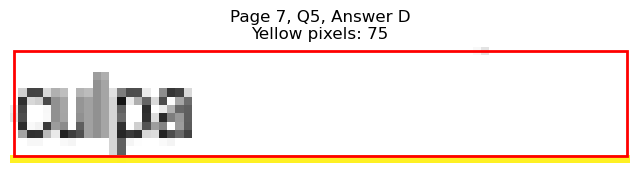

Page 7, Q5 - E: Detected box: x0=327.0, y0=367.1, x1=359.7, y1=379.8
Page 7, Q5, E: Yellow pixels: 916
Page 7, Q5, E: Total non-white pixels: 1079
Page 7, Q5, E: Yellow percentage: 84.9%


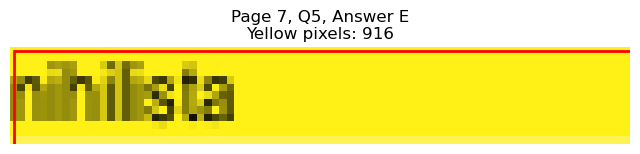


Page 7, Q5 - Selected Answer: E (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=118.9, y1=430.3
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 248
Page 7, Q6, A: Yellow percentage: 0.0%


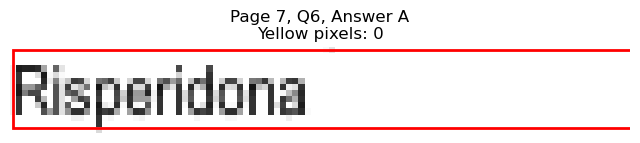

Page 7, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=121.0, y1=442.9
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 369
Page 7, Q6, B: Yellow percentage: 0.0%


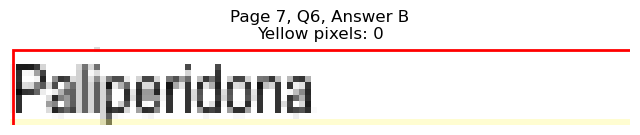

Page 7, Q6 - C: Detected box: x0=68.8, y0=442.8, x1=113.9, y1=455.5
Page 7, Q6, C: Yellow pixels: 1067
Page 7, Q6, C: Total non-white pixels: 1344
Page 7, Q6, C: Yellow percentage: 79.4%


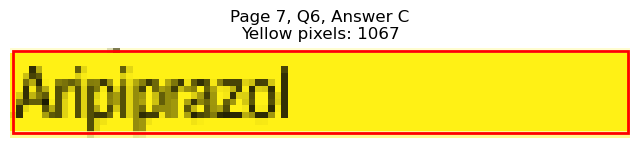

Page 7, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=375.7, y1=430.3
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 267
Page 7, Q6, D: Yellow percentage: 0.0%


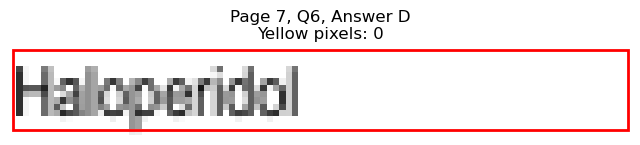

Page 7, Q6 - E: Detected box: x0=327.0, y0=430.2, x1=376.3, y1=442.9
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 248
Page 7, Q6, E: Yellow percentage: 0.0%


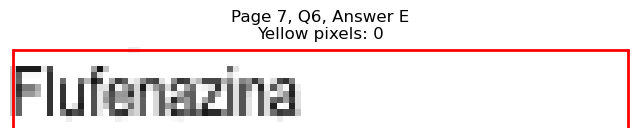


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=480.8, x1=159.6, y1=493.4
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 469
Page 7, Q7, A: Yellow percentage: 0.0%


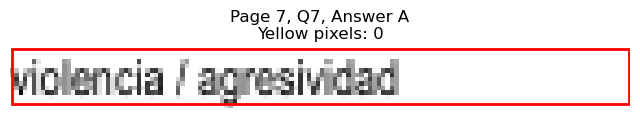

Page 7, Q7 - B: Detected box: x0=68.3, y0=493.4, x1=162.6, y1=506.0
Page 7, Q7, B: Yellow pixels: 145
Page 7, Q7, B: Total non-white pixels: 768
Page 7, Q7, B: Yellow percentage: 18.9%


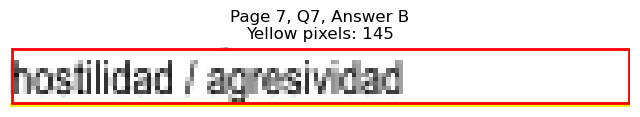

Page 7, Q7 - C: Detected box: x0=68.8, y0=506.0, x1=160.1, y1=518.6
Page 7, Q7, C: Yellow pixels: 1476
Page 7, Q7, C: Total non-white pixels: 2002
Page 7, Q7, C: Yellow percentage: 73.7%


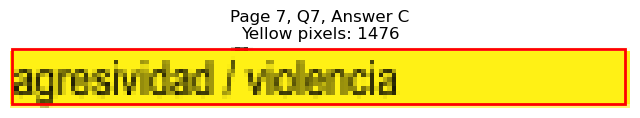

Page 7, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=421.9, y1=493.4
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 512
Page 7, Q7, D: Yellow percentage: 0.0%


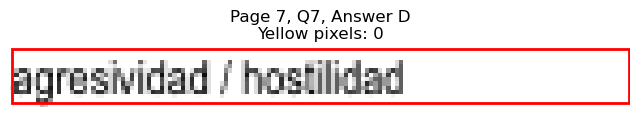

Page 7, Q7 - E: Detected box: x0=327.0, y0=493.4, x1=430.9, y1=506.0
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 571
Page 7, Q7, E: Yellow percentage: 0.0%


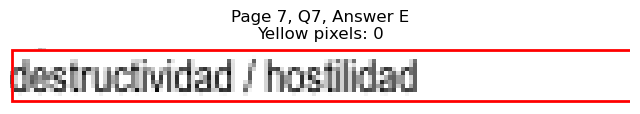


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=115.0, y1=619.6
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 259
Page 7, Q8, A: Yellow percentage: 0.0%


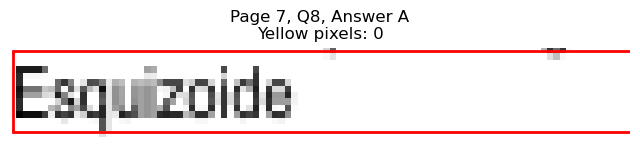

Page 7, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=109.5, y1=632.3
Page 7, Q8, B: Yellow pixels: 937
Page 7, Q8, B: Total non-white pixels: 1288
Page 7, Q8, B: Yellow percentage: 72.7%


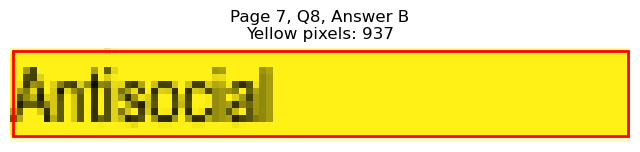

Page 7, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=110.9, y1=644.9
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 318
Page 7, Q8, C: Yellow percentage: 0.0%


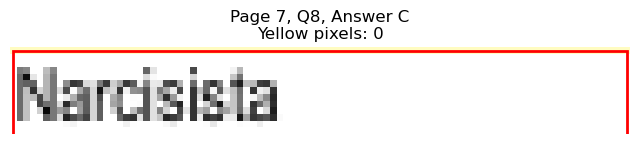

Page 7, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=372.2, y1=619.6
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 241
Page 7, Q8, D: Yellow percentage: 0.0%


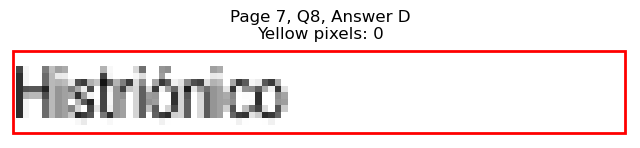

Page 7, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=364.6, y1=632.3
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 183
Page 7, Q8, E: Yellow percentage: 0.0%


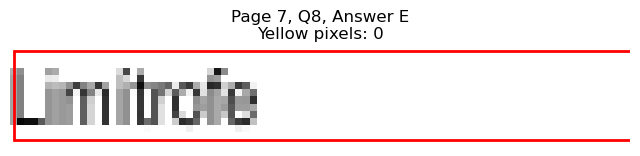


Page 7, Q8 - Selected Answer: B (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=100.3, y1=695.3
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 183
Page 7, Q9, A: Yellow percentage: 0.0%


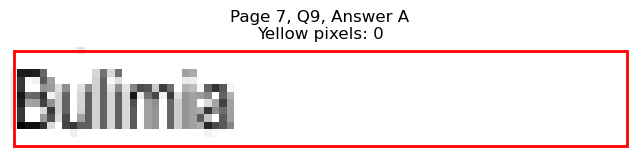

Page 7, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=88.3, y1=708.0
Page 7, Q9, B: Yellow pixels: 850
Page 7, Q9, B: Total non-white pixels: 923
Page 7, Q9, B: Yellow percentage: 92.1%


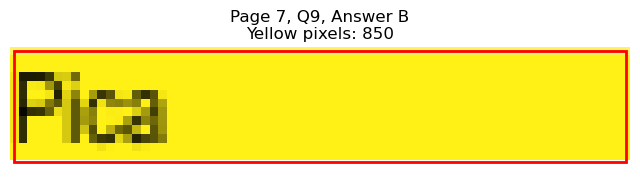

Page 7, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=113.9, y1=720.6
Page 7, Q9, C: Yellow pixels: 96
Page 7, Q9, C: Total non-white pixels: 319
Page 7, Q9, C: Yellow percentage: 30.1%


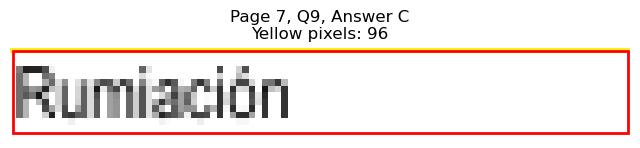

Page 7, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=363.2, y1=695.3
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 167
Page 7, Q9, D: Yellow percentage: 0.0%


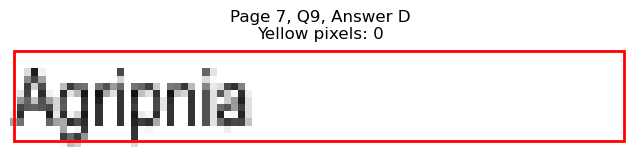

Page 7, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=366.7, y1=708.0
Page 7, Q9, E: Yellow pixels: 0
Page 7, Q9, E: Total non-white pixels: 227
Page 7, Q9, E: Yellow percentage: 0.0%


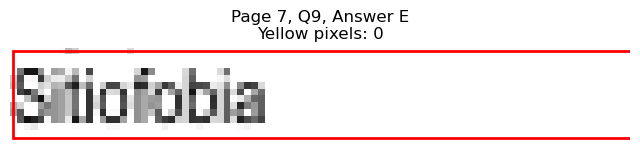


Page 7, Q9 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 8 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=115.9, y1=102.1
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 199
Page 8, Q1, A: Yellow percentage: 0.0%


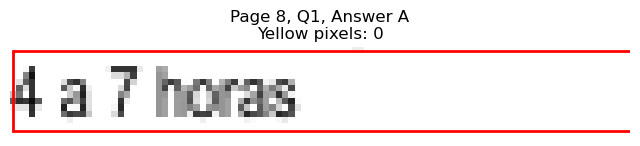

Page 8, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=120.5, y1=114.7
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 321
Page 8, Q1, B: Yellow percentage: 0.0%


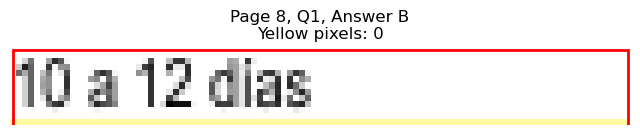

Page 8, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=110.9, y1=127.3
Page 8, Q1, C: Yellow pixels: 978
Page 8, Q1, C: Total non-white pixels: 1302
Page 8, Q1, C: Yellow percentage: 75.1%


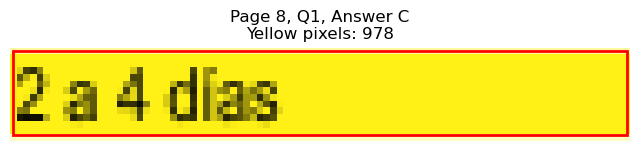

Page 8, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=385.3, y1=102.1
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 252
Page 8, Q1, D: Yellow percentage: 0.0%


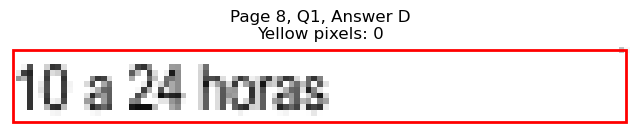

Page 8, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=374.2, y1=114.7
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 213
Page 8, Q1, E: Yellow percentage: 0.0%


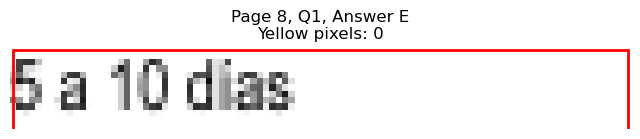


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=124.5, y1=177.8
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 270
Page 8, Q2, A: Yellow percentage: 0.0%


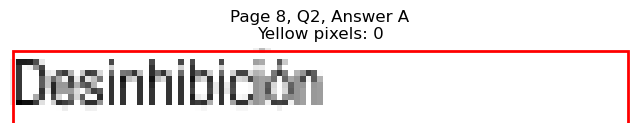

Page 8, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=146.5, y1=190.4
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 385
Page 8, Q2, B: Yellow percentage: 0.0%


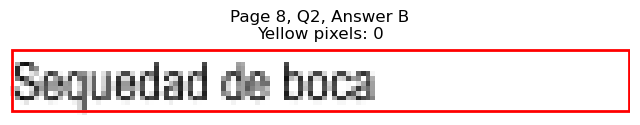

Page 8, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=238.4, y1=203.0
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 845
Page 8, Q2, C: Yellow percentage: 0.0%


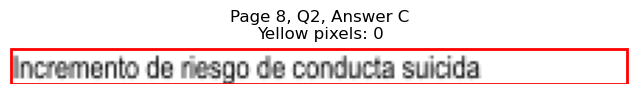

Page 8, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=356.1, y1=177.8
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 224
Page 8, Q2, D: Yellow percentage: 0.0%


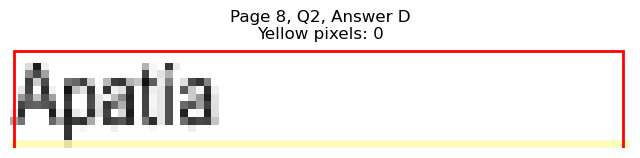

Page 8, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=436.4, y1=190.4
Page 8, Q2, E: Yellow pixels: 1489
Page 8, Q2, E: Total non-white pixels: 2240
Page 8, Q2, E: Yellow percentage: 66.5%


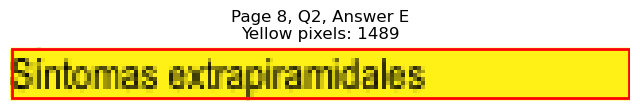


Page 8, Q2 - Selected Answer: E (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=98.4, y1=278.7
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 157
Page 8, Q3, A: Yellow percentage: 0.0%


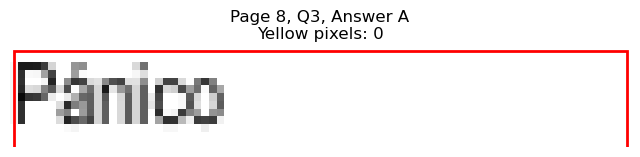

Page 8, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=144.5, y1=291.5
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 390
Page 8, Q3, B: Yellow percentage: 0.0%


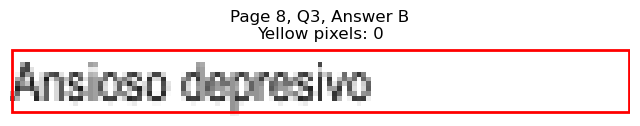

Page 8, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=113.9, y1=304.1
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 248
Page 8, Q3, C: Yellow percentage: 0.0%


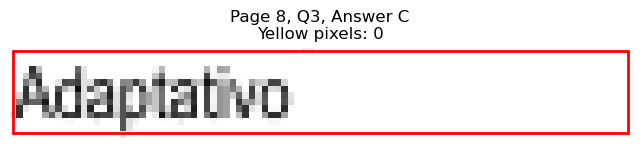

Page 8, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=414.8, y1=278.7
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 440
Page 8, Q3, D: Yellow percentage: 0.0%


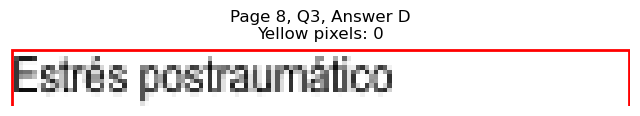

Page 8, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=421.4, y1=291.5
Page 8, Q3, E: Yellow pixels: 1496
Page 8, Q3, E: Total non-white pixels: 2030
Page 8, Q3, E: Yellow percentage: 73.7%


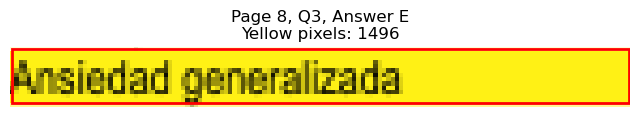


Page 8, Q3 - Selected Answer: E (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=121.0, y1=341.9
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 274
Page 8, Q4, A: Yellow percentage: 0.0%


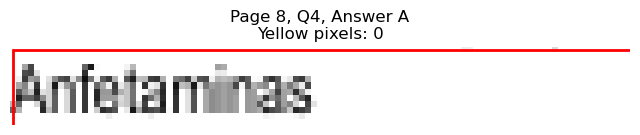

Page 8, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=104.4, y1=354.6
Page 8, Q4, B: Yellow pixels: 87
Page 8, Q4, B: Total non-white pixels: 259
Page 8, Q4, B: Yellow percentage: 33.6%


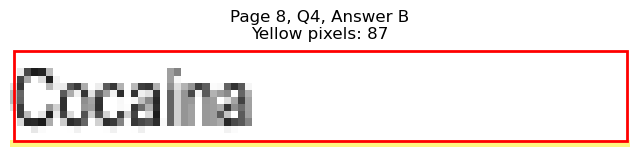

Page 8, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=100.9, y1=367.2
Page 8, Q4, C: Yellow pixels: 967
Page 8, Q4, C: Total non-white pixels: 1162
Page 8, Q4, C: Yellow percentage: 83.2%


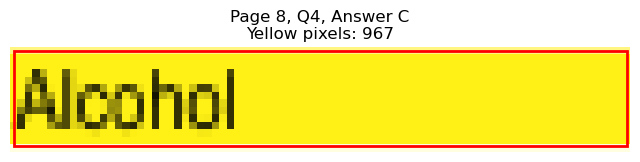

Page 8, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=394.3, y1=341.9
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 348
Page 8, Q4, D: Yellow percentage: 0.0%


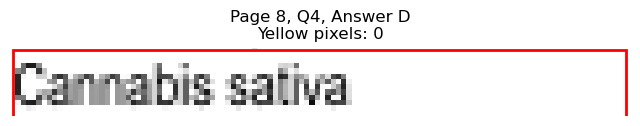

Page 8, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=370.1, y1=354.6
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 237
Page 8, Q4, E: Yellow percentage: 0.0%


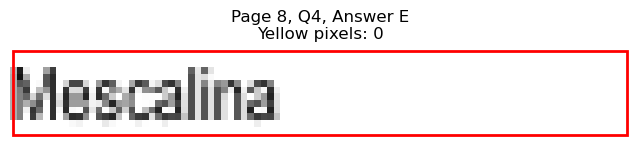


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=100.9, y1=417.6
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 137
Page 8, Q5, A: Yellow percentage: 0.0%


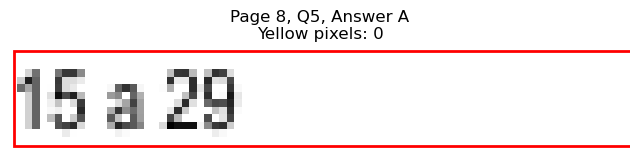

Page 8, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=100.9, y1=430.3
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 148
Page 8, Q5, B: Yellow percentage: 0.0%


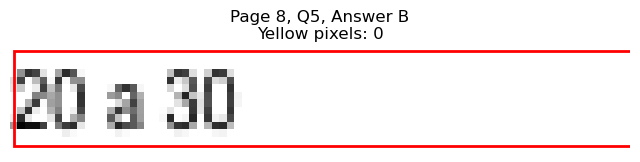

Page 8, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=101.4, y1=442.9
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 119
Page 8, Q5, C: Yellow percentage: 0.0%


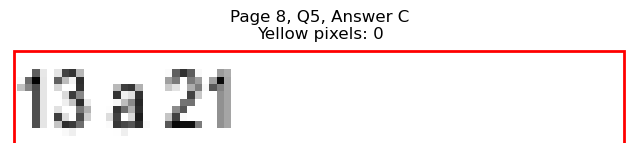

Page 8, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=360.2, y1=417.6
Page 8, Q5, D: Yellow pixels: 978
Page 8, Q5, D: Total non-white pixels: 1176
Page 8, Q5, D: Yellow percentage: 83.2%


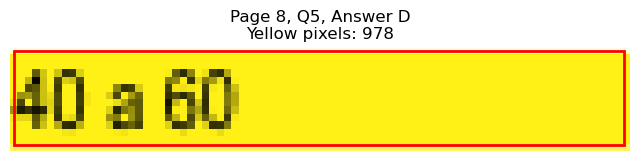

Page 8, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=359.7, y1=430.3
Page 8, Q5, E: Yellow pixels: 83
Page 8, Q5, E: Total non-white pixels: 245
Page 8, Q5, E: Yellow percentage: 33.9%


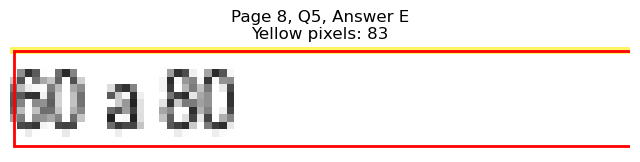


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=225.3, y1=480.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 788
Page 8, Q6, A: Yellow percentage: 0.0%


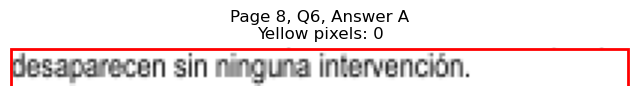

Page 8, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=194.2, y1=493.4
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 591
Page 8, Q6, B: Yellow percentage: 0.0%


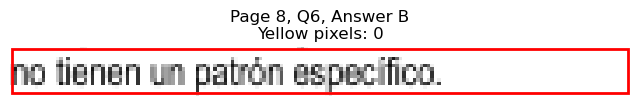

Page 8, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=236.3, y1=506.0
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 800
Page 8, Q6, C: Yellow percentage: 0.0%


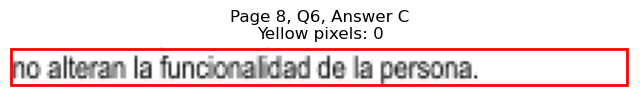

Page 8, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=451.9, y1=480.7
Page 8, Q6, D: Yellow pixels: 1788
Page 8, Q6, D: Total non-white pixels: 2275
Page 8, Q6, D: Yellow percentage: 78.6%


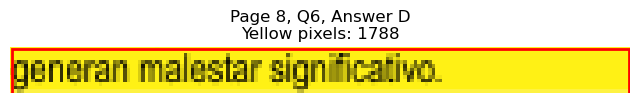

Page 8, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=526.8, y1=493.4
Page 8, Q6, E: Yellow pixels: 209
Page 8, Q6, E: Total non-white pixels: 1181
Page 8, Q6, E: Yellow percentage: 17.7%


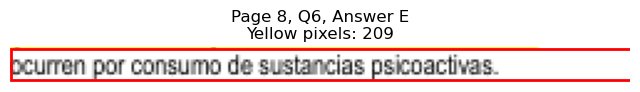


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=205.2, y1=543.8
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 686
Page 8, Q7, A: Yellow percentage: 0.0%


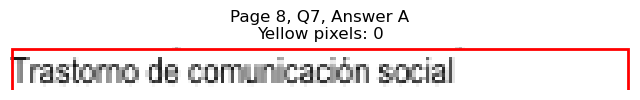

Page 8, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=279.9, y1=556.4
Page 8, Q7, B: Yellow pixels: 172
Page 8, Q7, B: Total non-white pixels: 1309
Page 8, Q7, B: Yellow percentage: 13.1%


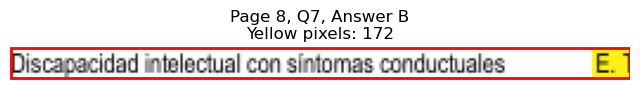

Page 8, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=235.8, y1=569.2
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 844
Page 8, Q7, C: Yellow percentage: 0.0%


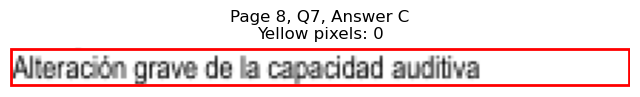

Page 8, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=413.8, y1=543.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 571
Page 8, Q7, D: Yellow percentage: 0.0%


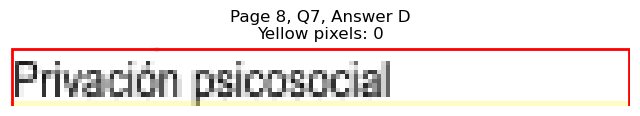

Page 8, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=475.1, y1=556.4
Page 8, Q7, E: Yellow pixels: 2001
Page 8, Q7, E: Total non-white pixels: 2786
Page 8, Q7, E: Yellow percentage: 71.8%


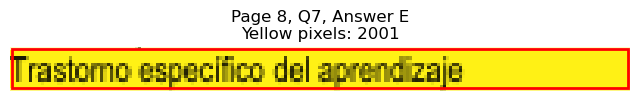


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=368.8, y1=644.9
Page 8, Q8, A: Yellow pixels: 3352
Page 8, Q8, A: Total non-white pixels: 4563
Page 8, Q8, A: Yellow percentage: 73.5%


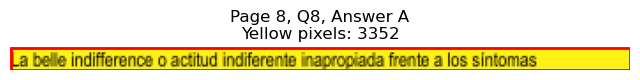

Page 8, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=355.1, y1=657.5
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 1453
Page 8, Q8, B: Yellow percentage: 0.0%


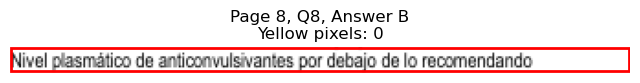

Page 8, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=297.5, y1=670.1
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 1188
Page 8, Q8, C: Yellow percentage: 0.0%


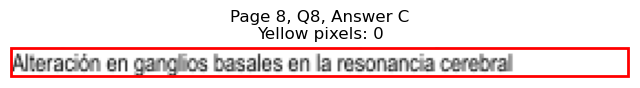

Page 8, Q8 - D: Detected box: x0=68.8, y0=670.1, x1=323.1, y1=682.7
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 1254
Page 8, Q8, D: Yellow percentage: 0.0%


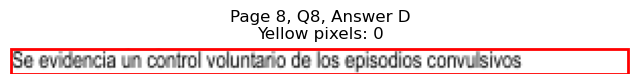

Page 8, Q8 - E: Detected box: x0=68.3, y0=682.7, x1=400.9, y1=695.3
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 1714
Page 8, Q8, E: Yellow percentage: 0.0%


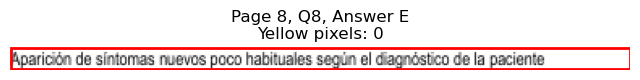


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=113.9, y1=127.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 252
Page 9, Q1, A: Yellow percentage: 0.0%


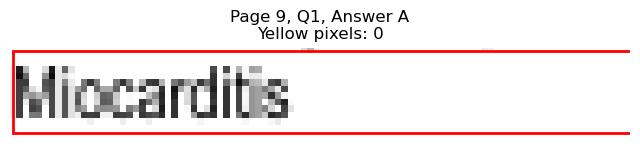

Page 9, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=171.6, y1=139.9
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 518
Page 9, Q1, B: Yellow percentage: 0.0%


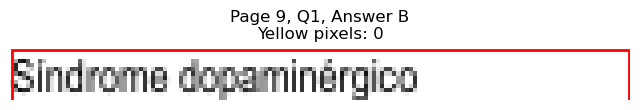

Page 9, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=190.2, y1=152.6
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 611
Page 9, Q1, C: Yellow percentage: 0.0%


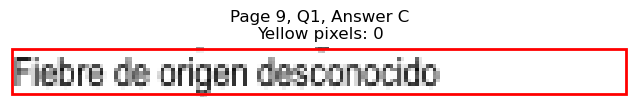

Page 9, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=433.4, y1=127.3
Page 9, Q1, D: Yellow pixels: 157
Page 9, Q1, D: Total non-white pixels: 723
Page 9, Q1, D: Yellow percentage: 21.7%


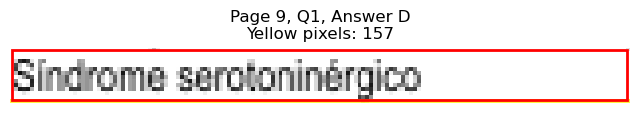

Page 9, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=390.8, y1=139.9
Page 9, Q1, E: Yellow pixels: 1209
Page 9, Q1, E: Total non-white pixels: 1482
Page 9, Q1, E: Yellow percentage: 81.6%


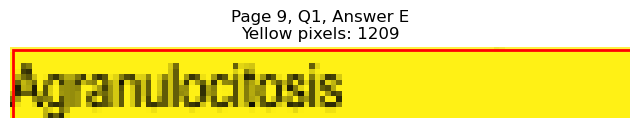


Page 9, Q1 - Selected Answer: E (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=81.4, y1=228.3
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 52
Page 9, Q2, A: Yellow percentage: 0.0%


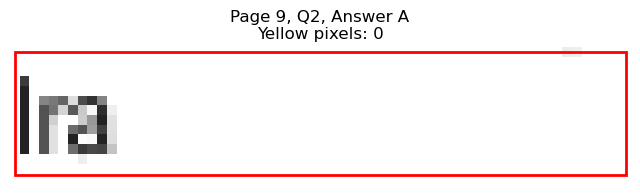

Page 9, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=115.5, y1=240.9
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 346
Page 9, Q2, B: Yellow percentage: 0.0%


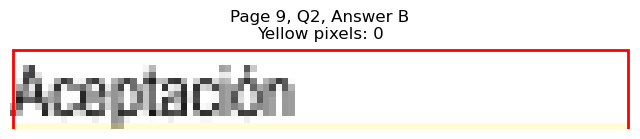

Page 9, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=121.0, y1=253.5
Page 9, Q2, C: Yellow pixels: 1110
Page 9, Q2, C: Total non-white pixels: 1442
Page 9, Q2, C: Yellow percentage: 77.0%


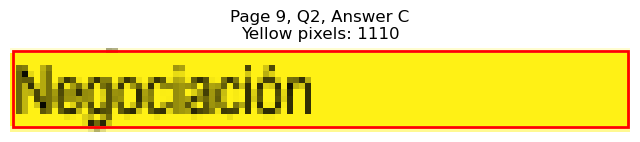

Page 9, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=368.2, y1=228.3
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 223
Page 9, Q2, D: Yellow percentage: 0.0%


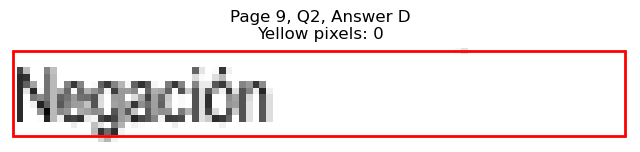

Page 9, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=370.7, y1=240.9
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 227
Page 9, Q2, E: Yellow percentage: 0.0%


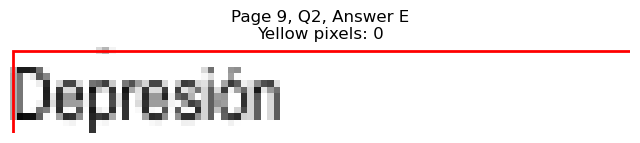


Page 9, Q2 - Selected Answer: C (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=316.6, x1=170.1, y1=329.3
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 536
Page 9, Q3, A: Yellow percentage: 0.0%


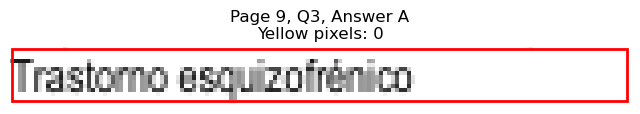

Page 9, Q3 - B: Detected box: x0=68.3, y0=329.2, x1=139.0, y1=341.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 361
Page 9, Q3, B: Yellow percentage: 0.0%


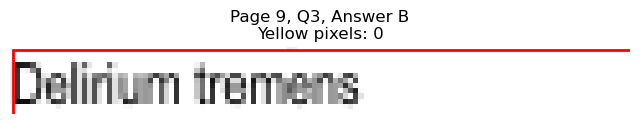

Page 9, Q3 - C: Detected box: x0=68.8, y0=341.9, x1=249.9, y1=354.6
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 896
Page 9, Q3, C: Yellow percentage: 0.0%


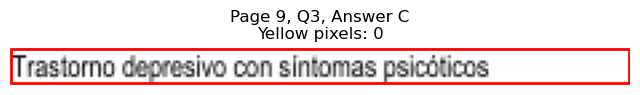

Page 9, Q3 - D: Detected box: x0=327.5, y0=316.6, x1=453.4, y1=329.3
Page 9, Q3, D: Yellow pixels: 1636
Page 9, Q3, D: Total non-white pixels: 2478
Page 9, Q3, D: Yellow percentage: 66.0%


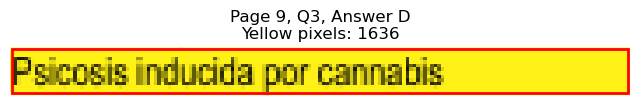

Page 9, Q3 - E: Detected box: x0=327.0, y0=329.2, x1=483.1, y1=341.9
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 972
Page 9, Q3, E: Yellow percentage: 0.0%


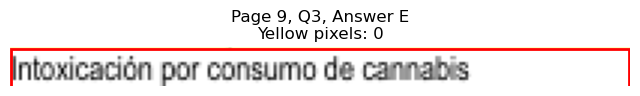


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=392.3, x1=133.0, y1=405.0
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 342
Page 9, Q4, A: Yellow percentage: 0.0%


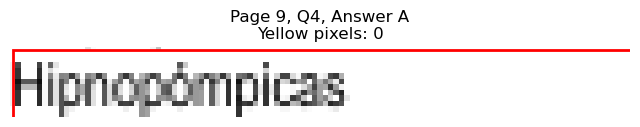

Page 9, Q4 - B: Detected box: x0=68.3, y0=404.9, x1=144.0, y1=417.6
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 399
Page 9, Q4, B: Yellow percentage: 0.0%


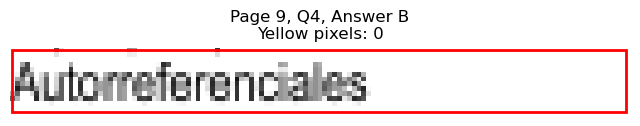

Page 9, Q4 - C: Detected box: x0=68.8, y0=417.6, x1=126.0, y1=430.3
Page 9, Q4, C: Yellow pixels: 1059
Page 9, Q4, C: Total non-white pixels: 1526
Page 9, Q4, C: Yellow percentage: 69.4%


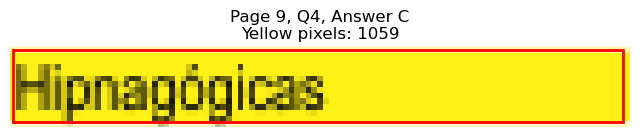

Page 9, Q4 - D: Detected box: x0=327.5, y0=392.3, x1=375.7, y1=405.0
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 234
Page 9, Q4, D: Yellow percentage: 0.0%


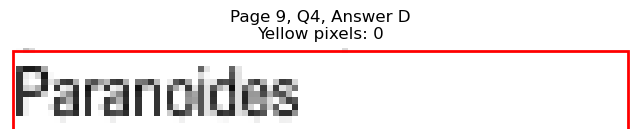

Page 9, Q4 - E: Detected box: x0=327.0, y0=404.9, x1=387.3, y1=417.6
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 327
Page 9, Q4, E: Yellow percentage: 0.0%


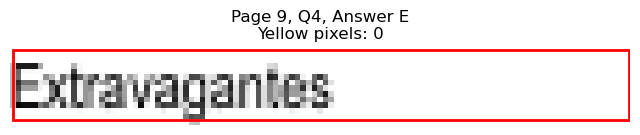


Page 9, Q4 - Selected Answer: C (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=468.1, x1=108.4, y1=480.7
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 209
Page 9, Q5, A: Yellow percentage: 0.0%


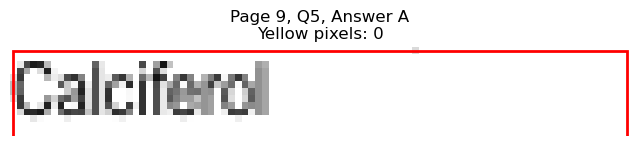

Page 9, Q5 - B: Detected box: x0=68.3, y0=480.8, x1=102.9, y1=493.4
Page 9, Q5, B: Yellow pixels: 898
Page 9, Q5, B: Total non-white pixels: 1190
Page 9, Q5, B: Yellow percentage: 75.5%


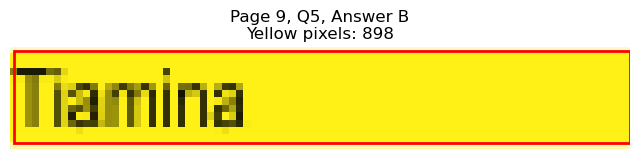

Page 9, Q5 - C: Detected box: x0=68.8, y0=493.4, x1=141.0, y1=506.0
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 489
Page 9, Q5, C: Yellow percentage: 0.0%


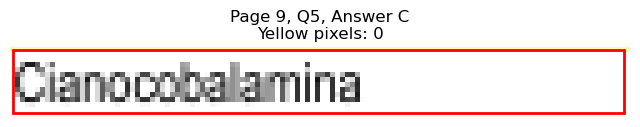

Page 9, Q5 - D: Detected box: x0=327.5, y0=468.1, x1=367.6, y1=480.7
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 204
Page 9, Q5, D: Yellow percentage: 0.0%


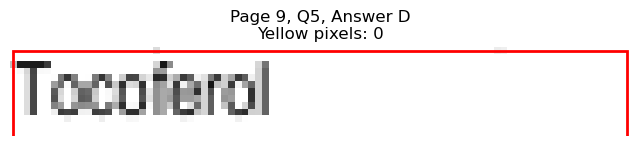

Page 9, Q5 - E: Detected box: x0=327.0, y0=480.8, x1=374.2, y1=493.4
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 248
Page 9, Q5, E: Yellow percentage: 0.0%


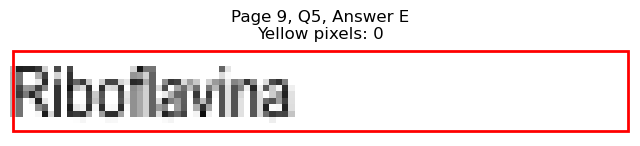


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=556.5, x1=139.5, y1=569.2
Page 9, Q6, A: Yellow pixels: 122
Page 9, Q6, A: Total non-white pixels: 466
Page 9, Q6, A: Yellow percentage: 26.2%


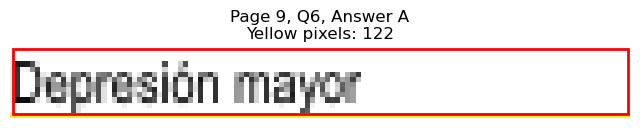

Page 9, Q6 - B: Detected box: x0=68.3, y0=569.1, x1=158.1, y1=581.8
Page 9, Q6, B: Yellow pixels: 1472
Page 9, Q6, B: Total non-white pixels: 1833
Page 9, Q6, B: Yellow percentage: 80.3%


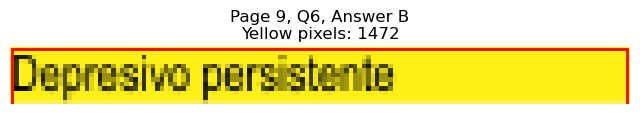

Page 9, Q6 - C: Detected box: x0=68.8, y0=581.7, x1=148.0, y1=594.4
Page 9, Q6, C: Yellow pixels: 130
Page 9, Q6, C: Total non-white pixels: 545
Page 9, Q6, C: Yellow percentage: 23.9%


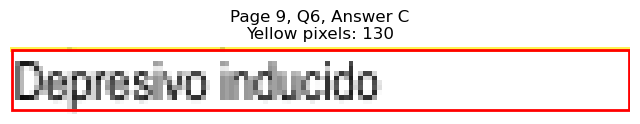

Page 9, Q6 - D: Detected box: x0=327.5, y0=556.5, x1=435.9, y1=569.2
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 551
Page 9, Q6, D: Yellow percentage: 0.0%


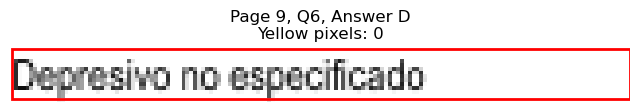

Page 9, Q6 - E: Detected box: x0=327.0, y0=569.1, x1=372.2, y1=581.8
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 243
Page 9, Q6, E: Yellow percentage: 0.0%


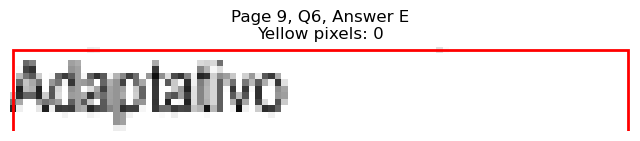


Page 9, Q6 - Selected Answer: B (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=146.1, y1=632.3
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 377
Page 9, Q7, A: Yellow percentage: 0.0%


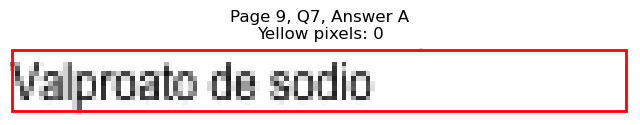

Page 9, Q7 - B: Detected box: x0=68.3, y0=632.2, x1=134.5, y1=644.9
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 341
Page 9, Q7, B: Yellow percentage: 0.0%


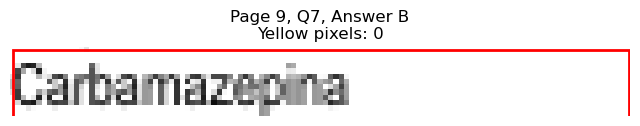

Page 9, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=115.0, y1=657.5
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 228
Page 9, Q7, C: Yellow percentage: 0.0%


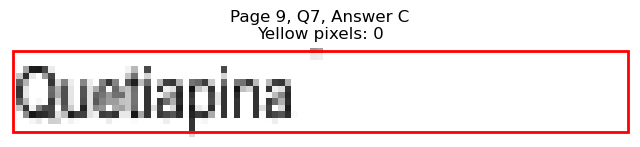

Page 9, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=412.3, y1=632.3
Page 9, Q7, D: Yellow pixels: 136
Page 9, Q7, D: Total non-white pixels: 571
Page 9, Q7, D: Yellow percentage: 23.8%


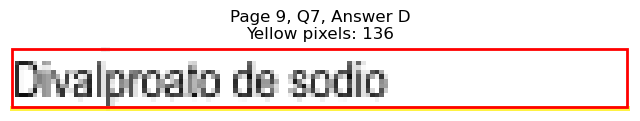

Page 9, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=376.7, y1=644.9
Page 9, Q7, E: Yellow pixels: 1083
Page 9, Q7, E: Total non-white pixels: 1300
Page 9, Q7, E: Yellow percentage: 83.3%


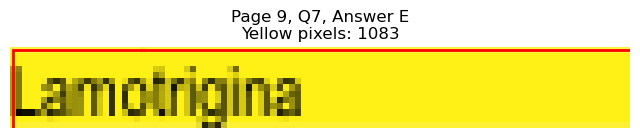


Page 9, Q7 - Selected Answer: E (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=109.5, y1=632.3
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 377
Page 9, Q8, A: Yellow percentage: 0.0%


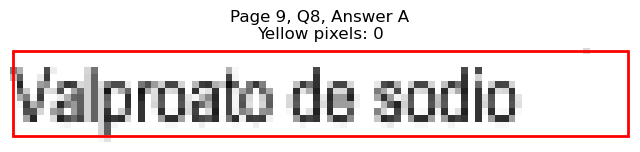

Page 9, Q8 - B: Detected box: x0=68.3, y0=708.0, x1=114.5, y1=720.6
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 264
Page 9, Q8, B: Yellow percentage: 0.0%


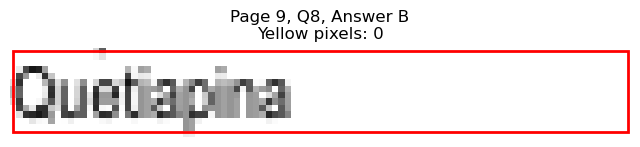

Page 9, Q8 - C: Detected box: x0=68.8, y0=720.6, x1=118.5, y1=733.2
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 267
Page 9, Q8, C: Yellow percentage: 0.0%


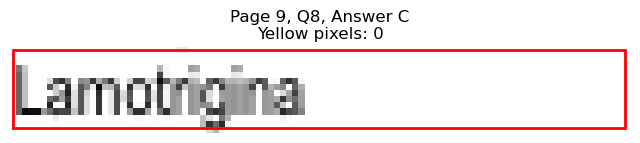

Page 9, Q8 - D: Detected box: x0=327.5, y0=695.4, x1=346.6, y1=708.0
Page 9, Q8, D: Yellow pixels: 845
Page 9, Q8, D: Total non-white pixels: 910
Page 9, Q8, D: Yellow percentage: 92.9%


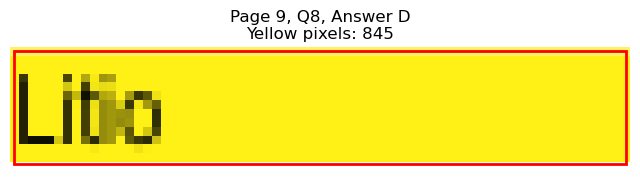

Page 9, Q8 - E: Detected box: x0=327.0, y0=708.0, x1=370.1, y1=720.6
Page 9, Q8, E: Yellow pixels: 94
Page 9, Q8, E: Total non-white pixels: 325
Page 9, Q8, E: Yellow percentage: 28.9%


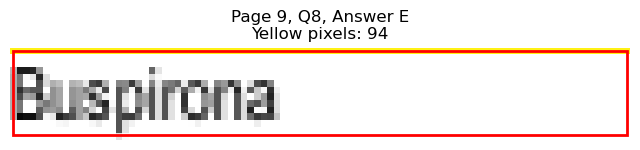


Page 9, Q8 - Selected Answer: D (based on yellow pixel count)





Page 10: Found 8 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=95.9, y1=114.7
Page 10, Q1, A: Yellow pixels: 1
Page 10, Q1, A: Total non-white pixels: 224
Page 10, Q1, A: Yellow percentage: 0.4%


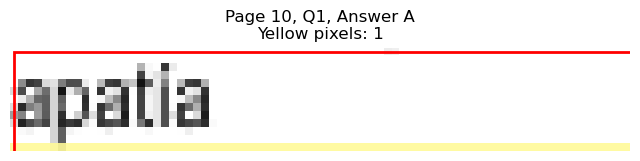

Page 10, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=109.5, y1=127.3
Page 10, Q1, B: Yellow pixels: 922
Page 10, Q1, B: Total non-white pixels: 1288
Page 10, Q1, B: Yellow percentage: 71.6%


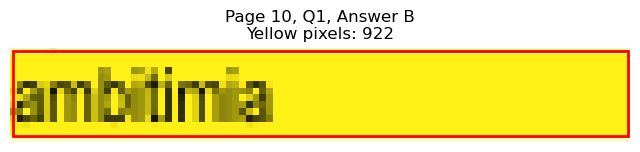

Page 10, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=167.5, y1=139.9
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 645
Page 10, Q1, C: Yellow percentage: 0.0%


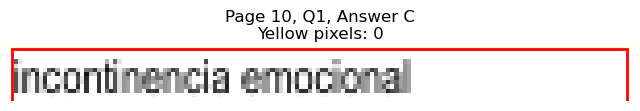

Page 10, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=360.7, y1=114.7
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 165
Page 10, Q1, D: Yellow percentage: 0.0%


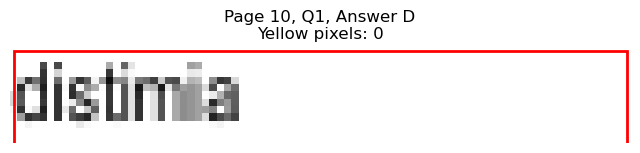

Page 10, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=382.7, y1=127.3
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 294
Page 10, Q1, E: Yellow percentage: 0.0%


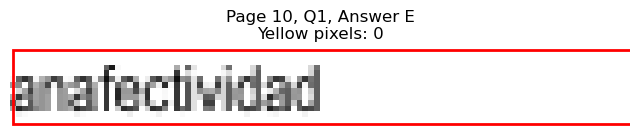


Page 10, Q1 - Selected Answer: B (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=124.9, y1=215.6
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 286
Page 10, Q2, A: Yellow percentage: 0.0%


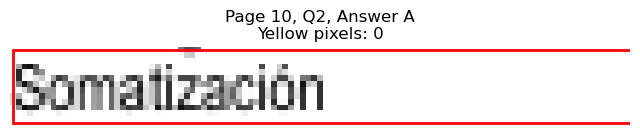

Page 10, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=121.0, y1=228.3
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 245
Page 10, Q2, B: Yellow percentage: 0.0%


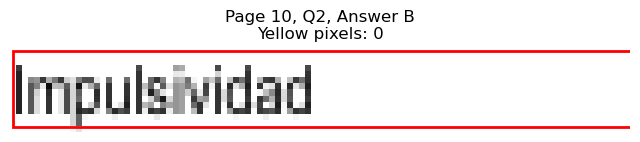

Page 10, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=118.9, y1=240.9
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 253
Page 10, Q2, C: Yellow percentage: 0.0%


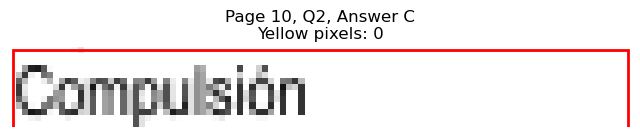

Page 10, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=374.2, y1=215.6
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 270
Page 10, Q2, D: Yellow percentage: 0.0%


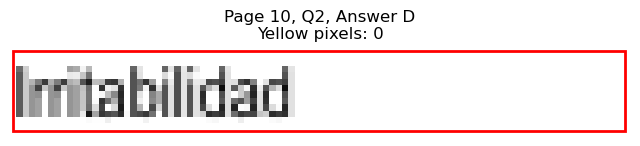

Page 10, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=376.3, y1=228.3
Page 10, Q2, E: Yellow pixels: 1012
Page 10, Q2, E: Total non-white pixels: 1400
Page 10, Q2, E: Yellow percentage: 72.3%


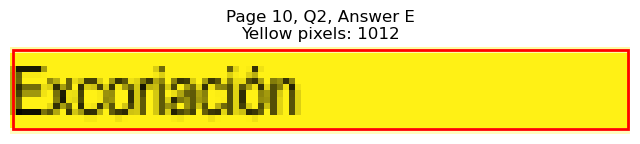


Page 10, Q2 - Selected Answer: E (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=98.4, y1=278.7
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 163
Page 10, Q3, A: Yellow percentage: 0.0%


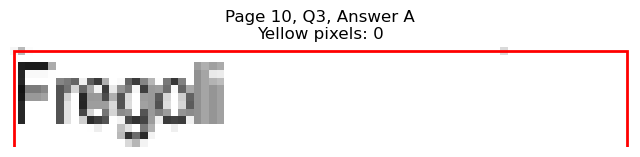

Page 10, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=107.4, y1=291.5
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 213
Page 10, Q3, B: Yellow percentage: 0.0%


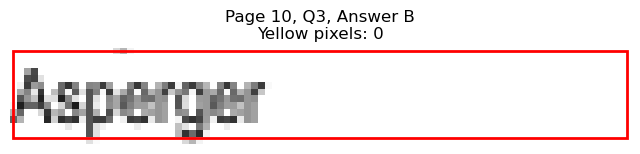

Page 10, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=109.5, y1=304.1
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 210
Page 10, Q3, C: Yellow percentage: 0.0%


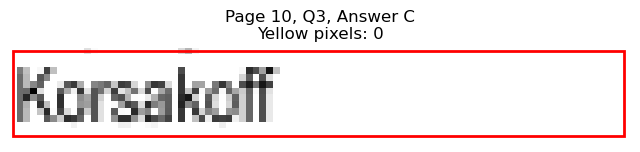

Page 10, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=364.1, y1=278.7
Page 10, Q3, D: Yellow pixels: 984
Page 10, Q3, D: Total non-white pixels: 1144
Page 10, Q3, D: Yellow percentage: 86.0%


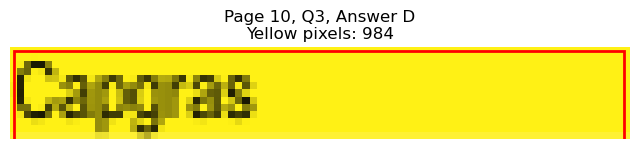

Page 10, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=391.7, y1=291.5
Page 10, Q3, E: Yellow pixels: 114
Page 10, Q3, E: Total non-white pixels: 424
Page 10, Q3, E: Yellow percentage: 26.9%


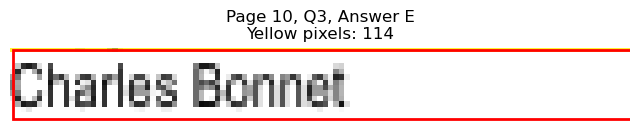


Page 10, Q3 - Selected Answer: D (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=103.5, y1=367.2
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 192
Page 10, Q4, A: Yellow percentage: 0.0%


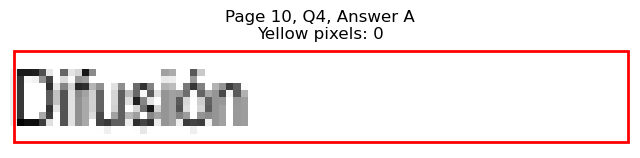

Page 10, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=92.4, y1=379.8
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 117
Page 10, Q4, B: Yellow percentage: 0.0%


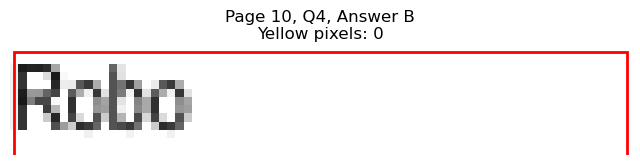

Page 10, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=104.4, y1=392.4
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 189
Page 10, Q4, C: Yellow percentage: 0.0%


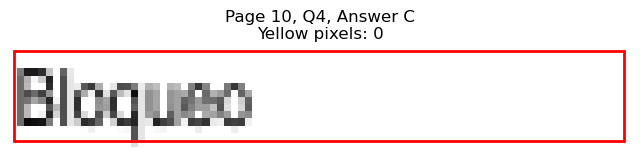

Page 10, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=366.7, y1=367.2
Page 10, Q4, D: Yellow pixels: 1006
Page 10, Q4, D: Total non-white pixels: 1260
Page 10, Q4, D: Yellow percentage: 79.8%


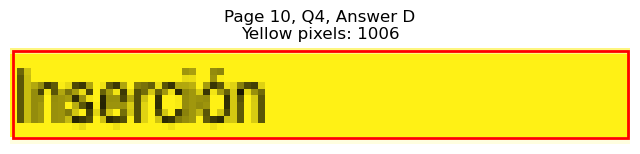

Page 10, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=372.2, y1=379.8
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 321
Page 10, Q4, E: Yellow percentage: 0.0%


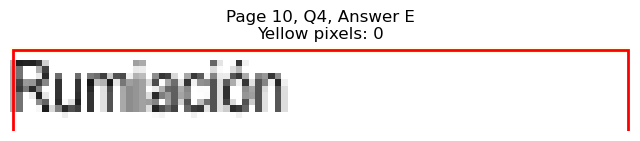


Page 10, Q4 - Selected Answer: D (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=172.6, y1=430.3
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 553
Page 10, Q5, A: Yellow percentage: 0.0%


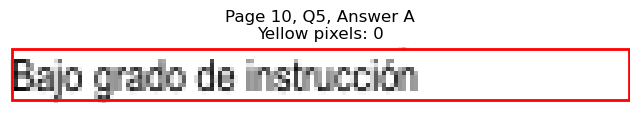

Page 10, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=165.1, y1=442.9
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 627
Page 10, Q5, B: Yellow percentage: 0.0%


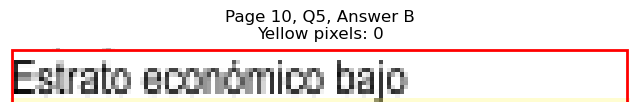

Page 10, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=184.1, y1=455.5
Page 10, Q5, C: Yellow pixels: 1728
Page 10, Q5, C: Total non-white pixels: 2338
Page 10, Q5, C: Yellow percentage: 73.9%


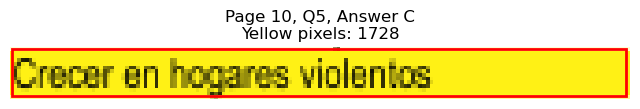

Page 10, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=421.9, y1=430.3
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 477
Page 10, Q5, D: Yellow percentage: 0.0%


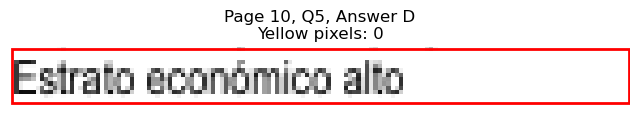

Page 10, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=425.3, y1=442.9
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 501
Page 10, Q5, E: Yellow percentage: 0.0%


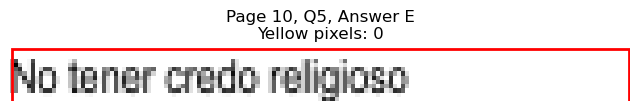


Page 10, Q5 - Selected Answer: C (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=166.6, y1=518.6
Page 10, Q6, A: Yellow pixels: 149
Page 10, Q6, A: Total non-white pixels: 667
Page 10, Q6, A: Yellow percentage: 22.3%


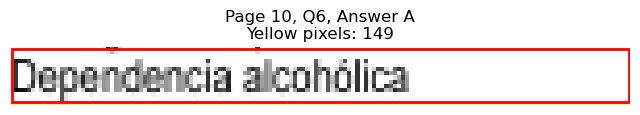

Page 10, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=188.7, y1=531.2
Page 10, Q6, B: Yellow pixels: 1725
Page 10, Q6, B: Total non-white pixels: 2394
Page 10, Q6, B: Yellow percentage: 72.1%


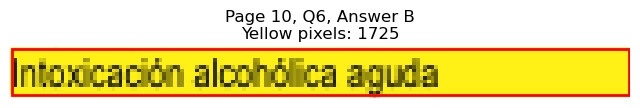

Page 10, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=204.2, y1=543.8
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 871
Page 10, Q6, C: Yellow percentage: 0.0%


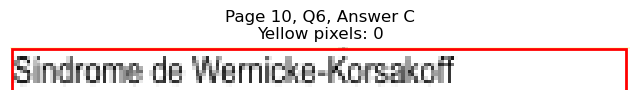

Page 10, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=468.5, y1=518.6
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 725
Page 10, Q6, D: Yellow percentage: 0.0%


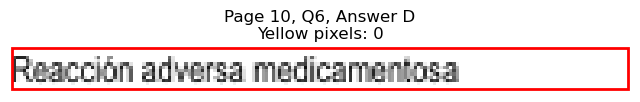

Page 10, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=390.3, y1=531.2
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 328
Page 10, Q6, E: Yellow percentage: 0.0%


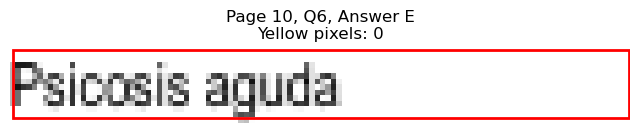


Page 10, Q6 - Selected Answer: B (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=160.6, y1=594.4
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 484
Page 10, Q7, A: Yellow percentage: 0.0%


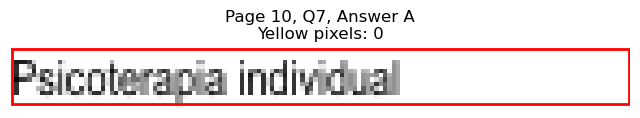

Page 10, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=187.1, y1=607.0
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 605
Page 10, Q7, B: Yellow percentage: 0.0%


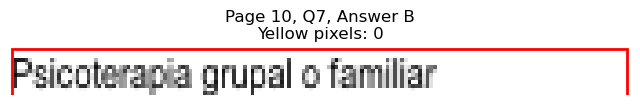

Page 10, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=227.8, y1=619.6
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 831
Page 10, Q7, C: Yellow percentage: 0.0%


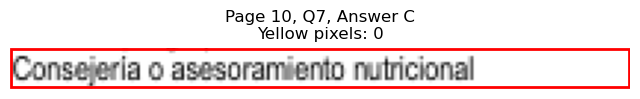

Page 10, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=389.2, y1=594.4
Page 10, Q7, D: Yellow pixels: 113
Page 10, Q7, D: Total non-white pixels: 440
Page 10, Q7, D: Yellow percentage: 25.7%


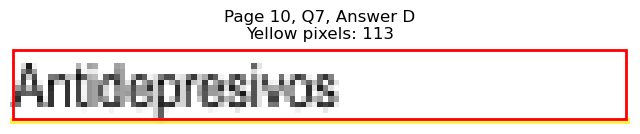

Page 10, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=454.0, y1=607.0
Page 10, Q7, E: Yellow pixels: 1808
Page 10, Q7, E: Total non-white pixels: 2314
Page 10, Q7, E: Yellow percentage: 78.1%


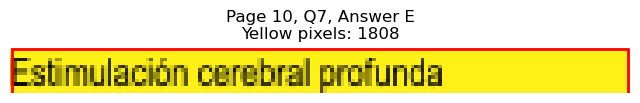


Page 10, Q7 - Selected Answer: E (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=241.8, y1=695.3
Page 10, Q8, A: Yellow pixels: 1956
Page 10, Q8, A: Total non-white pixels: 2996
Page 10, Q8, A: Yellow percentage: 65.3%


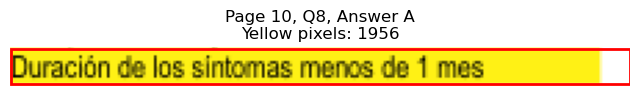

Page 10, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=201.3, y1=708.0
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 859
Page 10, Q8, B: Yellow percentage: 0.0%


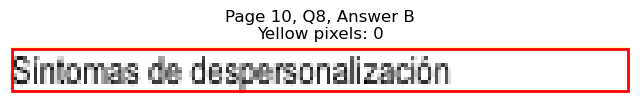

Page 10, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=182.2, y1=720.6
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 575
Page 10, Q8, C: Yellow percentage: 0.0%


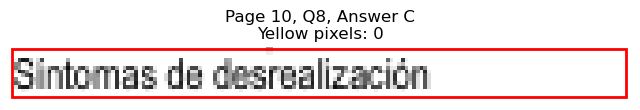

Page 10, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=388.7, y1=695.3
Page 10, Q8, D: Yellow pixels: 0
Page 10, Q8, D: Total non-white pixels: 345
Page 10, Q8, D: Yellow percentage: 0.0%


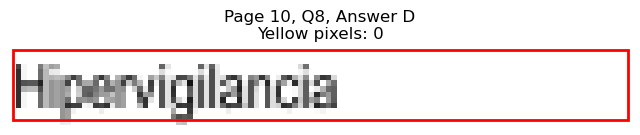

Page 10, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=411.3, y1=708.0
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 439
Page 10, Q8, E: Yellow percentage: 0.0%


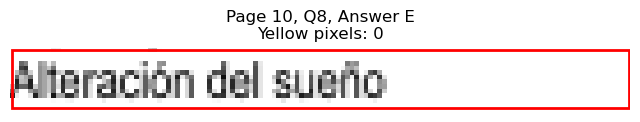


Page 10, Q8 - Selected Answer: A (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=100.9, y1=102.1
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 139
Page 11, Q1, A: Yellow percentage: 0.0%


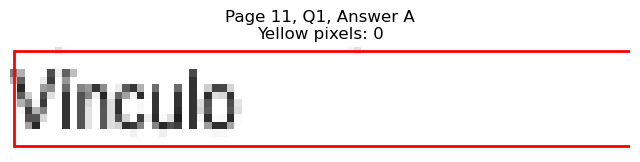

Page 11, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=106.0, y1=114.7
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 197
Page 11, Q1, B: Yellow percentage: 0.0%


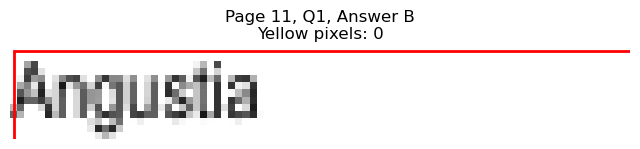

Page 11, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=98.9, y1=127.3
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 148
Page 11, Q1, C: Yellow percentage: 0.0%


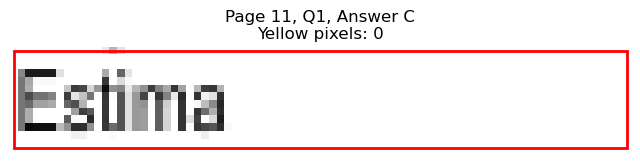

Page 11, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=370.6, y1=102.1
Page 11, Q1, D: Yellow pixels: 94
Page 11, Q1, D: Total non-white pixels: 304
Page 11, Q1, D: Yellow percentage: 30.9%


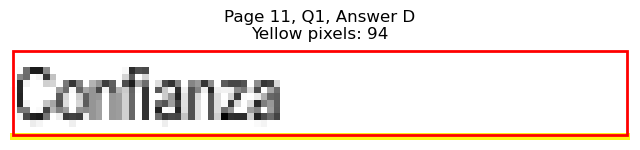

Page 11, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=355.6, y1=114.7
Page 11, Q1, E: Yellow pixels: 897
Page 11, Q1, E: Total non-white pixels: 1027
Page 11, Q1, E: Yellow percentage: 87.3%


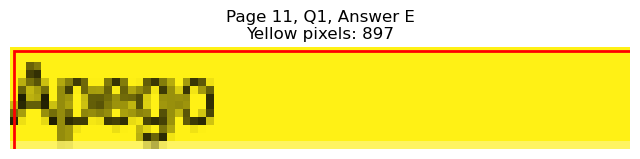


Page 11, Q1 - Selected Answer: E (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=125.5, y1=177.8
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 301
Page 11, Q2, A: Yellow percentage: 0.0%


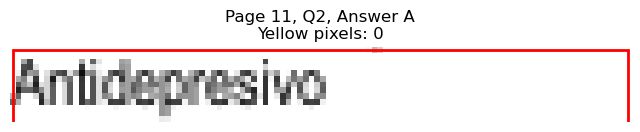

Page 11, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=123.0, y1=190.4
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 322
Page 11, Q2, B: Yellow percentage: 0.0%


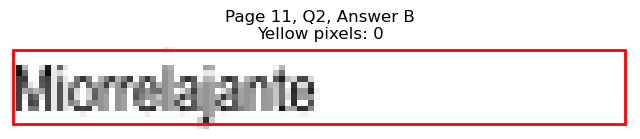

Page 11, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=164.5, y1=203.0
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 477
Page 11, Q2, C: Yellow percentage: 0.0%


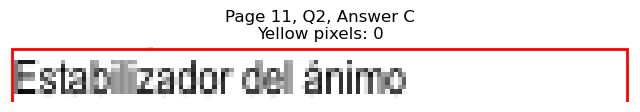

Page 11, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=380.7, y1=177.8
Page 11, Q2, D: Yellow pixels: 1139
Page 11, Q2, D: Total non-white pixels: 1352
Page 11, Q2, D: Yellow percentage: 84.2%


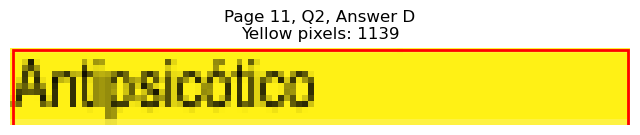

Page 11, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=367.1, y1=190.4
Page 11, Q2, E: Yellow pixels: 91
Page 11, Q2, E: Total non-white pixels: 285
Page 11, Q2, E: Yellow percentage: 31.9%


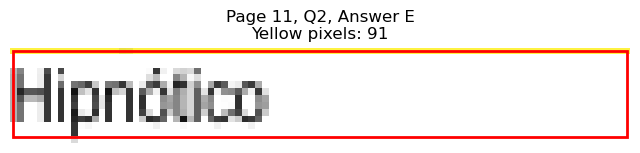


Page 11, Q2 - Selected Answer: D (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=155.5, y1=266.1
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 444
Page 11, Q3, A: Yellow percentage: 0.0%


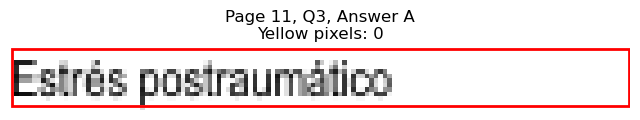

Page 11, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=102.9, y1=278.7
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 178
Page 11, Q3, B: Yellow percentage: 0.0%


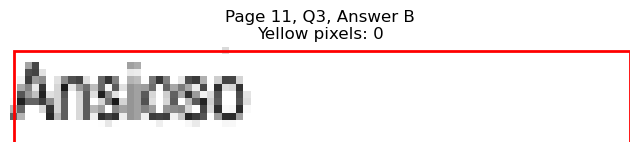

Page 11, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=156.5, y1=291.5
Page 11, Q3, C: Yellow pixels: 1441
Page 11, Q3, C: Total non-white pixels: 1946
Page 11, Q3, C: Yellow percentage: 74.0%


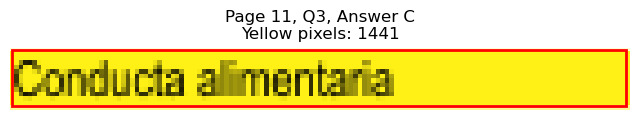

Page 11, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=370.6, y1=266.1
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 223
Page 11, Q3, D: Yellow percentage: 0.0%


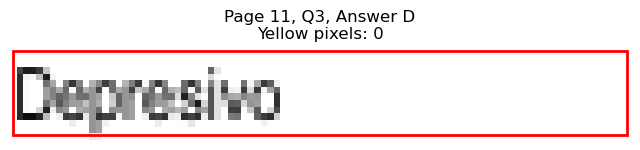

Page 11, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=370.1, y1=278.7
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 212
Page 11, Q3, E: Yellow percentage: 0.0%


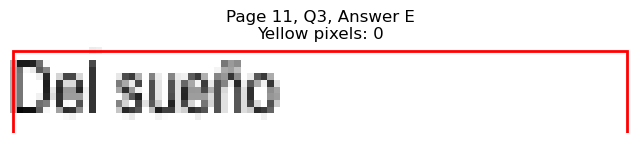


Page 11, Q3 - Selected Answer: C (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=245.3, y1=329.3
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 865
Page 11, Q4, A: Yellow percentage: 0.0%


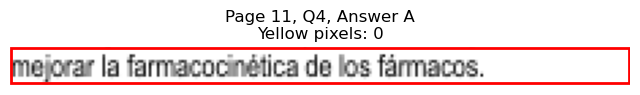

Page 11, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=246.3, y1=341.9
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 840
Page 11, Q4, B: Yellow percentage: 0.0%


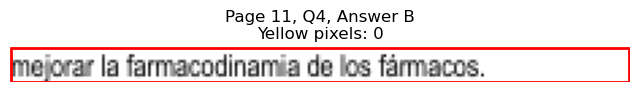

Page 11, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=266.8, y1=354.6
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 985
Page 11, Q4, C: Yellow percentage: 0.0%


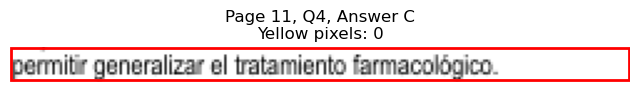

Page 11, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=530.6, y1=329.3
Page 11, Q4, D: Yellow pixels: 1730
Page 11, Q4, D: Total non-white pixels: 2996
Page 11, Q4, D: Yellow percentage: 57.7%


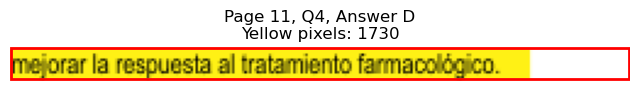

Page 11, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=492.1, y1=341.9
Page 11, Q4, E: Yellow pixels: 0
Page 11, Q4, E: Total non-white pixels: 1072
Page 11, Q4, E: Yellow percentage: 0.0%


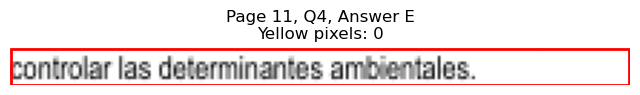


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=162.6, y1=417.6
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 501
Page 11, Q5, A: Yellow percentage: 0.0%


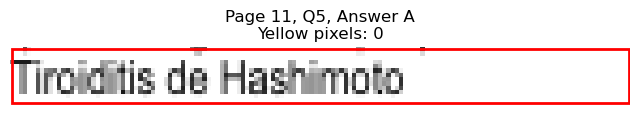

Page 11, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=185.2, y1=430.3
Page 11, Q5, B: Yellow pixels: 1577
Page 11, Q5, B: Total non-white pixels: 2352
Page 11, Q5, B: Yellow percentage: 67.0%


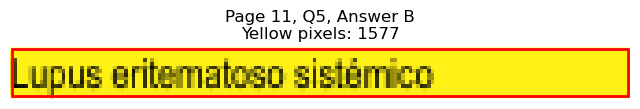

Page 11, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=200.2, y1=442.9
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 828
Page 11, Q5, C: Yellow percentage: 0.0%


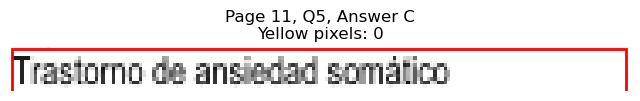

Page 11, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=440.9, y1=417.6
Page 11, Q5, D: Yellow pixels: 0
Page 11, Q5, D: Total non-white pixels: 584
Page 11, Q5, D: Yellow percentage: 0.0%


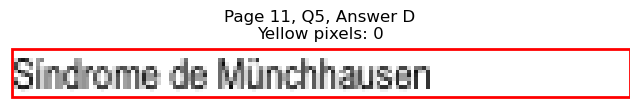

Page 11, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=443.9, y1=430.3
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 574
Page 11, Q5, E: Yellow percentage: 0.0%


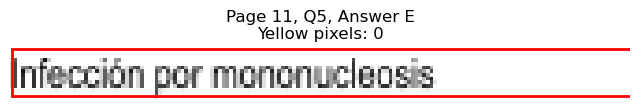


Page 11, Q5 - Selected Answer: B (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=172.1, y1=506.0
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 528
Page 11, Q6, A: Yellow percentage: 0.0%


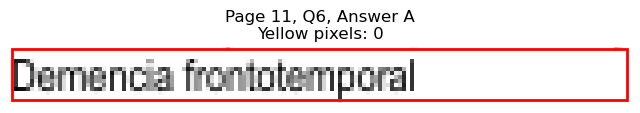

Page 11, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=147.5, y1=518.6
Page 11, Q6, B: Yellow pixels: 0
Page 11, Q6, B: Total non-white pixels: 398
Page 11, Q6, B: Yellow percentage: 0.0%


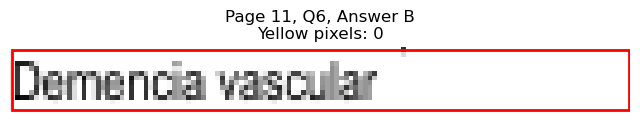

Page 11, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=246.3, y1=531.2
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 888
Page 11, Q6, C: Yellow percentage: 0.0%


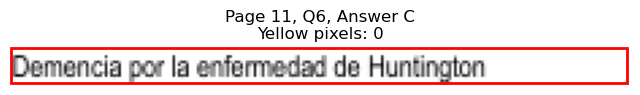

Page 11, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=441.4, y1=506.0
Page 11, Q6, D: Yellow pixels: 1704
Page 11, Q6, D: Total non-white pixels: 2149
Page 11, Q6, D: Yellow percentage: 79.3%


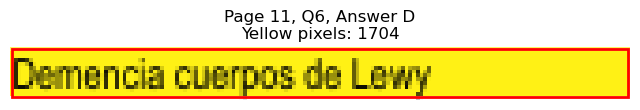

Page 11, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=394.3, y1=518.6
Page 11, Q6, E: Yellow pixels: 114
Page 11, Q6, E: Total non-white pixels: 457
Page 11, Q6, E: Yellow percentage: 24.9%


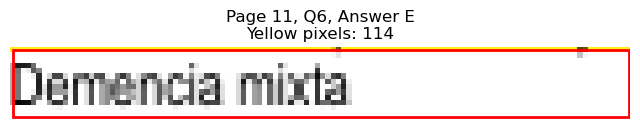


Page 11, Q6 - Selected Answer: D (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=152.1, y1=581.8
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 423
Page 11, Q7, A: Yellow percentage: 0.0%


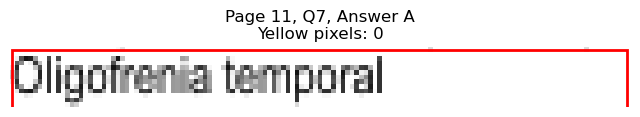

Page 11, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=124.0, y1=594.4
Page 11, Q7, B: Yellow pixels: 106
Page 11, Q7, B: Total non-white pixels: 390
Page 11, Q7, B: Yellow percentage: 27.2%


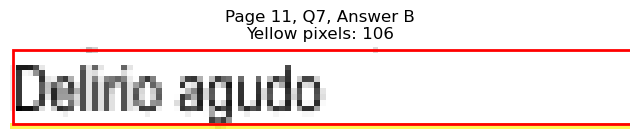

Page 11, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=157.6, y1=607.0
Page 11, Q7, C: Yellow pixels: 1448
Page 11, Q7, C: Total non-white pixels: 1820
Page 11, Q7, C: Yellow percentage: 79.6%


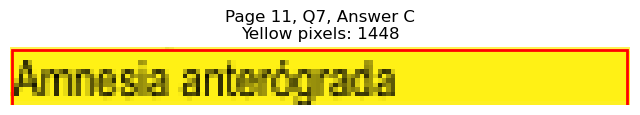

Page 11, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=397.3, y1=581.8
Page 11, Q7, D: Yellow pixels: 0
Page 11, Q7, D: Total non-white pixels: 367
Page 11, Q7, D: Yellow percentage: 0.0%


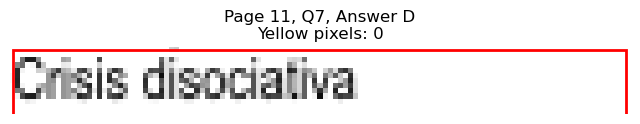

Page 11, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=405.8, y1=594.4
Page 11, Q7, E: Yellow pixels: 0
Page 11, Q7, E: Total non-white pixels: 384
Page 11, Q7, E: Yellow percentage: 0.0%


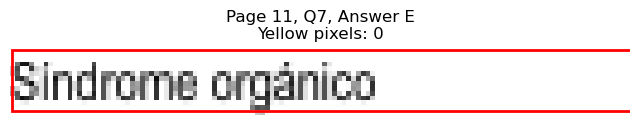


Page 11, Q7 - Selected Answer: C (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=109.5, y1=657.5
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 211
Page 11, Q8, A: Yellow percentage: 0.0%


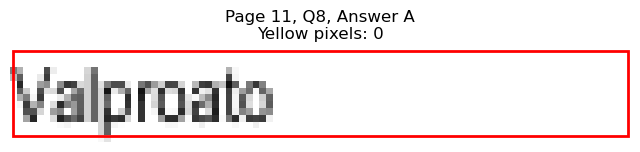

Page 11, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=113.4, y1=670.1
Page 11, Q8, B: Yellow pixels: 96
Page 11, Q8, B: Total non-white pixels: 341
Page 11, Q8, B: Yellow percentage: 28.2%


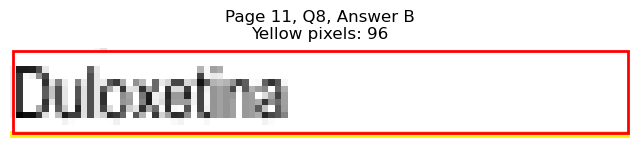

Page 11, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=116.9, y1=682.7
Page 11, Q8, C: Yellow pixels: 1109
Page 11, Q8, C: Total non-white pixels: 1287
Page 11, Q8, C: Yellow percentage: 86.2%


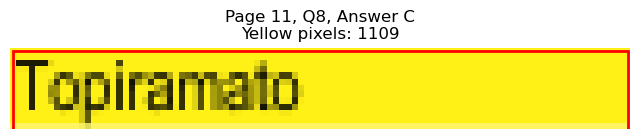

Page 11, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=393.8, y1=657.5
Page 11, Q8, D: Yellow pixels: 0
Page 11, Q8, D: Total non-white pixels: 352
Page 11, Q8, D: Yellow percentage: 0.0%


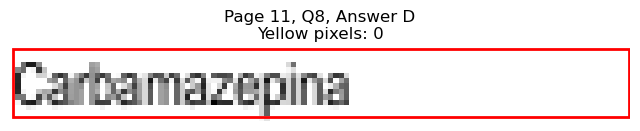

Page 11, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=370.1, y1=670.1
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 220
Page 11, Q8, E: Yellow percentage: 0.0%


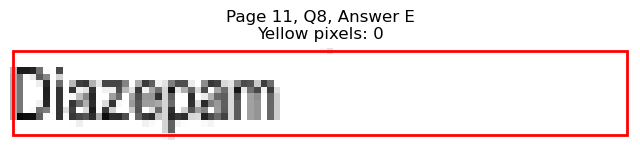


Page 11, Q8 - Selected Answer: C (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=136.0, y1=733.2
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 338
Page 11, Q9, A: Yellow percentage: 0.0%


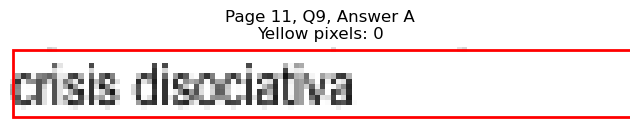

Page 11, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=141.5, y1=745.8
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 365
Page 11, Q9, B: Yellow percentage: 0.0%


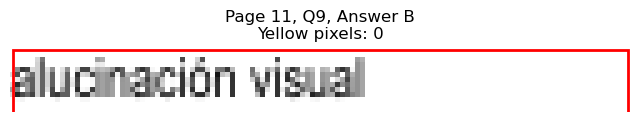

Page 11, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=156.5, y1=758.4
Page 11, Q9, C: Yellow pixels: 0
Page 11, Q9, C: Total non-white pixels: 439
Page 11, Q9, C: Yellow percentage: 0.0%


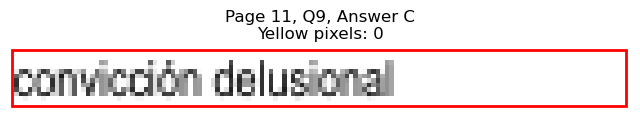

Page 11, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=430.9, y1=733.2
Page 11, Q9, D: Yellow pixels: 1594
Page 11, Q9, D: Total non-white pixels: 2156
Page 11, Q9, D: Yellow percentage: 73.9%


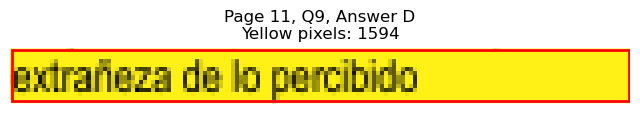

Page 11, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=427.9, y1=745.8
Page 11, Q9, E: Yellow pixels: 0
Page 11, Q9, E: Total non-white pixels: 646
Page 11, Q9, E: Yellow percentage: 0.0%


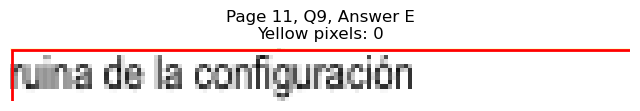


Page 11, Q9 - Selected Answer: D (based on yellow pixel count)





Page 12: Found 5 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=109.9, y1=102.1
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 222
Page 12, Q1, A: Yellow percentage: 0.0%


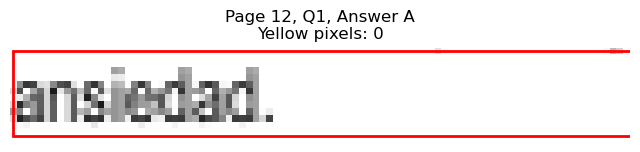

Page 12, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=124.9, y1=114.7
Page 12, Q1, B: Yellow pixels: 0
Page 12, Q1, B: Total non-white pixels: 308
Page 12, Q1, B: Yellow percentage: 0.0%


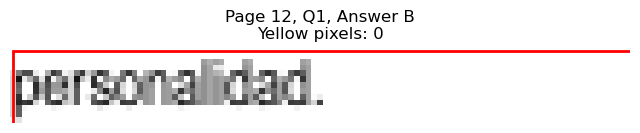

Page 12, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=157.1, y1=127.3
Page 12, Q1, C: Yellow pixels: 0
Page 12, Q1, C: Total non-white pixels: 441
Page 12, Q1, C: Yellow percentage: 0.0%


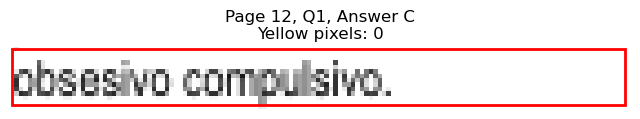

Page 12, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=372.2, y1=102.1
Page 12, Q1, D: Yellow pixels: 1084
Page 12, Q1, D: Total non-white pixels: 1344
Page 12, Q1, D: Yellow percentage: 80.7%


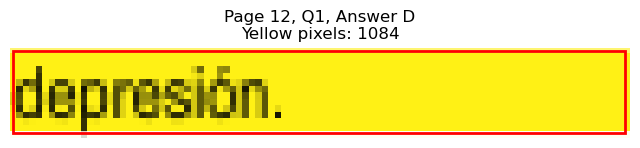

Page 12, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=415.9, y1=114.7
Page 12, Q1, E: Yellow pixels: 0
Page 12, Q1, E: Total non-white pixels: 607
Page 12, Q1, E: Yellow percentage: 0.0%


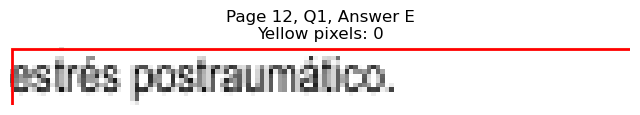


Page 12, Q1 - Selected Answer: D (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=99.9, y1=177.8
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 159
Page 12, Q2, A: Yellow percentage: 0.0%


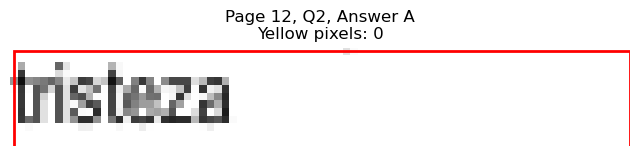

Page 12, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=106.9, y1=190.4
Page 12, Q2, B: Yellow pixels: 89
Page 12, Q2, B: Total non-white pixels: 277
Page 12, Q2, B: Yellow percentage: 32.1%


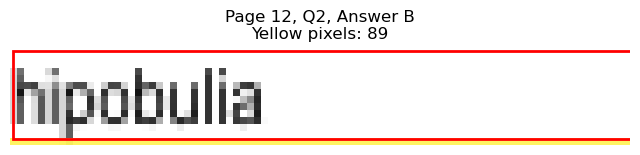

Page 12, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=113.4, y1=203.0
Page 12, Q2, C: Yellow pixels: 1064
Page 12, Q2, C: Total non-white pixels: 1248
Page 12, Q2, C: Yellow percentage: 85.3%


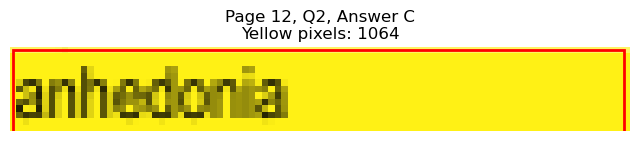

Page 12, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=354.2, y1=177.8
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 128
Page 12, Q2, D: Yellow percentage: 0.0%


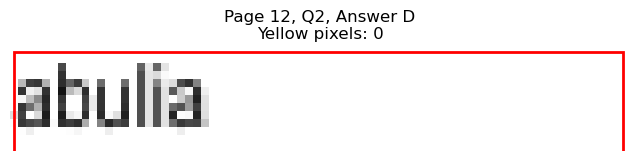

Page 12, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=351.7, y1=190.4
Page 12, Q2, E: Yellow pixels: 0
Page 12, Q2, E: Total non-white pixels: 143
Page 12, Q2, E: Yellow percentage: 0.0%


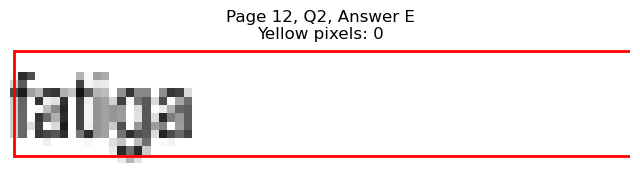


Page 12, Q2 - Selected Answer: C (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=115.5, y1=240.9
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 242
Page 12, Q3, A: Yellow percentage: 0.0%


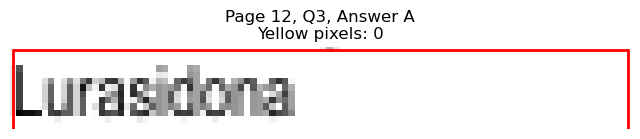

Page 12, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=111.4, y1=253.5
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 218
Page 12, Q3, B: Yellow percentage: 0.0%


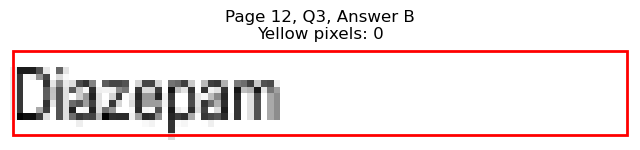

Page 12, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=121.5, y1=266.1
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 278
Page 12, Q3, C: Yellow percentage: 0.0%


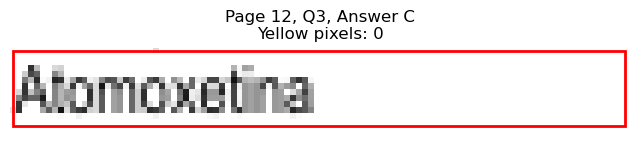

Page 12, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=373.7, y1=240.9
Page 12, Q3, D: Yellow pixels: 0
Page 12, Q3, D: Total non-white pixels: 346
Page 12, Q3, D: Yellow percentage: 0.0%


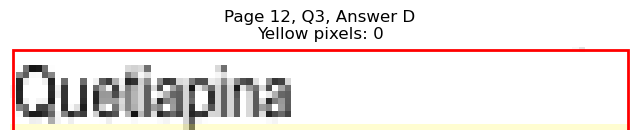

Page 12, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=385.3, y1=253.5
Page 12, Q3, E: Yellow pixels: 1179
Page 12, Q3, E: Total non-white pixels: 1526
Page 12, Q3, E: Yellow percentage: 77.3%


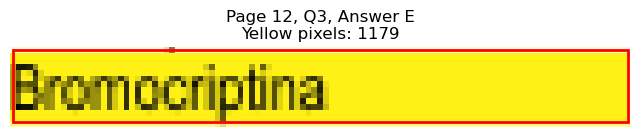


Page 12, Q3 - Selected Answer: E (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=123.0, y1=304.1
Page 12, Q4, A: Yellow pixels: 0
Page 12, Q4, A: Total non-white pixels: 305
Page 12, Q4, A: Yellow percentage: 0.0%


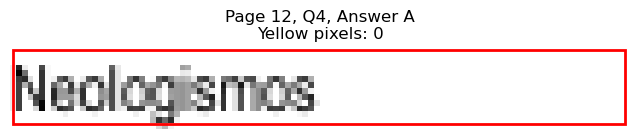

Page 12, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=189.1, y1=316.7
Page 12, Q4, B: Yellow pixels: 0
Page 12, Q4, B: Total non-white pixels: 625
Page 12, Q4, B: Yellow percentage: 0.0%


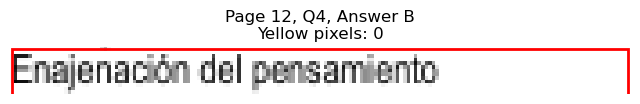

Page 12, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=178.6, y1=329.3
Page 12, Q4, C: Yellow pixels: 0
Page 12, Q4, C: Total non-white pixels: 593
Page 12, Q4, C: Yellow percentage: 0.0%


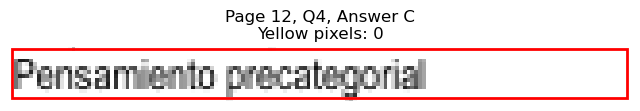

Page 12, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=416.8, y1=304.1
Page 12, Q4, D: Yellow pixels: 1477
Page 12, Q4, D: Total non-white pixels: 1960
Page 12, Q4, D: Yellow percentage: 75.4%


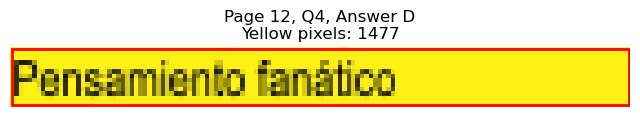

Page 12, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=502.2, y1=316.7
Page 12, Q4, E: Yellow pixels: 0
Page 12, Q4, E: Total non-white pixels: 1137
Page 12, Q4, E: Yellow percentage: 0.0%


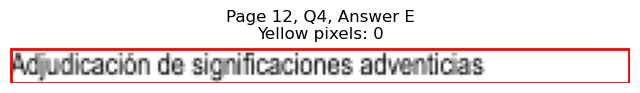


Page 12, Q4 - Selected Answer: D (based on yellow pixel count)




Page 12, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=131.5, y1=379.8
Page 12, Q5, A: Yellow pixels: 0
Page 12, Q5, A: Total non-white pixels: 330
Page 12, Q5, A: Yellow percentage: 0.0%


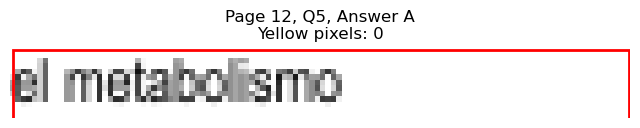

Page 12, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=116.4, y1=392.4
Page 12, Q5, B: Yellow pixels: 0
Page 12, Q5, B: Total non-white pixels: 237
Page 12, Q5, B: Yellow percentage: 0.0%


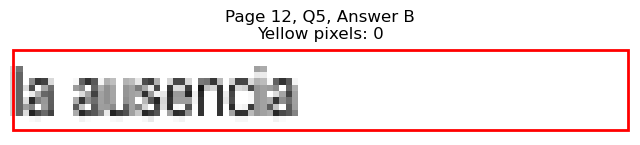

Page 12, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=119.4, y1=405.0
Page 12, Q5, C: Yellow pixels: 0
Page 12, Q5, C: Total non-white pixels: 264
Page 12, Q5, C: Yellow percentage: 0.0%


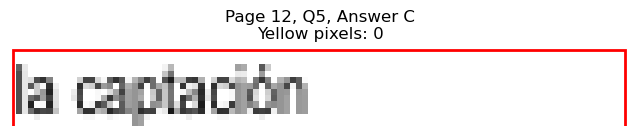

Page 12, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=384.7, y1=379.8
Page 12, Q5, D: Yellow pixels: 0
Page 12, Q5, D: Total non-white pixels: 393
Page 12, Q5, D: Yellow percentage: 0.0%


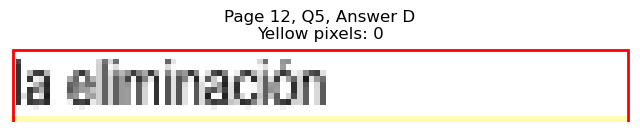

Page 12, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=378.2, y1=392.4
Page 12, Q5, E: Yellow pixels: 1021
Page 12, Q5, E: Total non-white pixels: 1428
Page 12, Q5, E: Yellow percentage: 71.5%


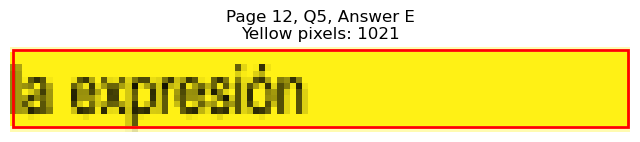


Page 12, Q5 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,La oxitocina es la hormona implicada en el ape...
1,Mujer de 25 años con trastorno bipolar y trata...
2,Madre de un varón de 7 años que acaba de ser d...
3,¿Cuál de las siguientes afirmaciones sobre sui...
4,¿Cuál de los siguientes fármacos tiene mayor e...
...,...
95,"En relación con la patología dual, el alcoholi..."
96,La......es un síntoma crucial en el diagnóstic...
97,¿Cuál de los siguientes fármacos es el más usa...
98,¿Cuál de las alternativas NO corresponde a un ...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Hipófisis anterior,Núcleo mamilar,Hipófisis posterior,Suprarrenal,Putamen
1,Ampliar la historia clínica,Incrementar la dosis de litio,Agregar un estabilizador del ánimo,No modificar el tratamiento,Rotar a otro estabilizador de ánimo
2,No tiene ningún rol en el caso,Hay una heredabilidad variable,Herencia recesivo probable,Herencia dominante probable,Herencia ligada al X probable
3,Todas,Los que intentan matarse lo hacen sin aviso,La mejor psicoterapia es la psicoanalítica,Hay necesidad de sedarlos de inmediato,Los médicos presentan mayor riesgo que la
4,Risperidona,Clozapina,Quetiapina,Ziprasidona,Clorpromazina
...,...,...,...,...,...
95,ansiedad.,personalidad.,obsesivo compulsivo.,depresión.,estrés postraumático.
96,tristeza,hipobulia,anhedonia,abulia,fatiga
97,Lurasidona,Diazepam,Atomoxetina,Quetiapina,Bromocriptina
98,Neologismos,Enajenación del pensamiento,Pensamiento precategorial,Pensamiento fanático,Adjudicación de significaciones adventicias


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,La oxitocina es la hormona implicada en el ape...,Hipófisis anterior,Núcleo mamilar,Hipófisis posterior,Suprarrenal,Putamen,C
1,Mujer de 25 años con trastorno bipolar y trata...,Ampliar la historia clínica,Incrementar la dosis de litio,Agregar un estabilizador del ánimo,No modificar el tratamiento,Rotar a otro estabilizador de ánimo,E
2,Madre de un varón de 7 años que acaba de ser d...,No tiene ningún rol en el caso,Hay una heredabilidad variable,Herencia recesivo probable,Herencia dominante probable,Herencia ligada al X probable,B
3,¿Cuál de las siguientes afirmaciones sobre sui...,Todas,Los que intentan matarse lo hacen sin aviso,La mejor psicoterapia es la psicoanalítica,Hay necesidad de sedarlos de inmediato,Los médicos presentan mayor riesgo que la,E
4,¿Cuál de los siguientes fármacos tiene mayor e...,Risperidona,Clozapina,Quetiapina,Ziprasidona,Clorpromazina,A
...,...,...,...,...,...,...,...
95,"En relación con la patología dual, el alcoholi...",ansiedad.,personalidad.,obsesivo compulsivo.,depresión.,estrés postraumático.,D
96,La......es un síntoma crucial en el diagnóstic...,tristeza,hipobulia,anhedonia,abulia,fatiga,C
97,¿Cuál de los siguientes fármacos es el más usa...,Lurasidona,Diazepam,Atomoxetina,Quetiapina,Bromocriptina,E
98,¿Cuál de las alternativas NO corresponde a un ...,Neologismos,Enajenación del pensamiento,Pensamiento precategorial,Pensamiento fanático,Adjudicación de significaciones adventicias,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Psiquiatría.csv
